# Compare F, F0, and dF/F — sessions 216–231

Adapted from `compare_F_F0_dff.ipynb`. Choose one session/run for the full original diagnostics (both channels, artifact detection, red regression, stacked traces and rankings). The final section compares F/F0/dF/F across **every discovered run** in sessions 216–231, processing one run at a time. ROI numbers are local to each run, not matched cells across recordings.

Use the `mini2p-preprocessing` Python environment. Inputs on `/Volumes/behrens` must be mounted. Saving is off by default and uses the repository's `output` directory. Baselines are computed over full traces before restricting the plot window.

**Definition:** raw `F.npy` is distinct from the neuropil-corrected `F` plotted here. This notebook consistently uses `(F_corrected − F0) / max(mean(F0), 1e-3)`, reproducing the explicit formula in the original comparison notebook. Installed Suite2p preprocessing is checked separately; it must not silently determine whether outputs are ΔF or ΔF/F.

In [15]:
from pathlib import Path
import json
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, minimum_filter1d, maximum_filter1d
from scipy.signal import medfilt
from sklearn.linear_model import HuberRegressor, LinearRegression, Ridge

# Shared plotting style.
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Helvetica Neue', 'Helvetica', 'Arial']
mpl.rcParams['xtick.labelsize'] = 12
mpl.rcParams['ytick.labelsize'] = 12
mpl.rcParams['axes.labelsize'] = 12
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.spines.top'] = False
mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['legend.frameon'] = False
mpl.rcParams['figure.dpi'] = 110
mpl.rcParams['savefig.dpi'] = 200

try:
    import torch
    import suite2p
except ImportError:
    torch = None
    suite2p = None

## How the arrays were generated, and the comparison with session 177

The following is established from the **current repository code** (`Convert_seg_to_stat`, `convert_seg_to_stat_216_231.py`, `calculate_run_dff.py`), not a complete historical execution log.

1. **Inputs already exist.** The converter reads `ops.npy`, registered int16 `data.bin`, and (when present) `data_chan2.bin`. Registration, destriping and distortion correction happened upstream; this converter does not perform them.
2. **Cellpose labels → `stat`.** Each positive mask label becomes one ROI: `ypix`, `xpix`, `npix`, uniform `lam=1`, and mean-coordinate `med`. `roi_stats` fills in Suite2p ROI properties. Rows follow ascending positive label order; IDs need not correspond between runs.
3. **ROI and neuropil masks.** `create_masks` uses saved ops or fallbacks: `lam_percentile=50`, `allow_overlap=False`, inner exclusion radius 2 pixels, at least 350 neuropil pixels, `circular_neuropil=False`. Normalized ROI weights extract mean fluorescence; surrounding neuropil masks supply the background trace.
4. **Registered movies → fluorescence.** `extraction_wrapper` reads frames in batches on CPU using the same spatial masks for both channels. It produces raw ROI `F.npy`, surrounding `Fneu.npy`, and their `_chan2` equivalents. These saved arrays are NOT neuropil-subtracted. Check `functional_chan` rather than assuming file channel 1 always means physical green.
5. **Classification.** Suite2p's classifier produces `iscell.npy`; the converter does not discard non-cell rows from the fluorescence arrays.
6. **Neuropil correction for deconvolution.** `Fc = F − neucoeff × Fneu`. Missing flat ops entries receive defaults: `neucoeff=0.7`, baseline `maximin`, window 60 seconds, smoothing sigma 10 frames, percentile 8, `fs=7.52 Hz`, `tau=1 s`, batch size 500. Existing entries win. Defaults do not establish the actual acquisition settings.
7. **Baseline preprocessing → spikes.** `suite2p.extraction.preprocess(Fc, ...)` feeds `oasis`, whose result is saved as `spks.npy`. The inspected installed Suite2p source subtracts its estimated baseline, without dividing by F0. Neither converter saves its intermediate corrected trace, F0, or dF/F. `spks` is a deconvolution output, not dF/F.
8. **This comparison notebook calculates F0 and dF/F later.** It applies the explicit SciPy formula above to saved fluorescence. Red-reference regression and artifact treatment are further analysis steps, not part of mask conversion.
9. **The newer percentile export is separate.** `calculate_run_dff.py` computes one F0 per ROI: the 20th percentile of Fc over the whole recording, then `(Fc−F0)/F0`. Nonpositive F0 or nonfinite input makes the ROI's dF/F NaN. It can save `dff.npy`, `dff_F0.npy`, `dff_valid.npy`, channel-2 equivalents and `dff_metadata.json`. It applies no red regression, artifact replacement or smoothing. Therefore those saved dff files should not be expected to equal this notebook's maximin outputs.

| Aspect | Session 177 converter | Sessions 216–231 converter |
|---|---|---|
| Input path | Current active assignment is `destriped_distortion_uncorrected/suite2p/plane0`; the earlier striped assignment is overwritten | Each `funcimg/run-*/suite2p/plane0` |
| Segmentation | `meanImg_ch1_seg.npy` | Each run's `meanImg_green_functional_contrast_seg.npy` |
| Extraction and deconvolution | Same core calls/settings in current code | Same core calls/settings in current code |
| Label selection | `unique(masks)[1:]`, assumes background zero exists | Explicitly selects positive labels and validates masks |
| Channels and validation | Opens both binaries unconditionally | Supports one channel; checks frame sizes/counts and missing two-channel binary |
| Saving | Overwrites eight output files | Backs up eight existing outputs, then replaces them |

Different segmentation, registered input movies, saved ops, or Suite2p versions can change the values even when the core algorithm is shared. Folder names alone do not prove how the 216–231 movies were preprocessed. The converter does not update existing downstream dff files: if F was re-extracted later, previously saved dff may be stale and must be regenerated. The original comparison notebook also mixed its explicit normalized formula with installed `preprocess` in later method plots; this copy uses the normalized formula consistently.

### Saved settings inspected during notebook creation

Session 216/run-01 (420 ROIs × 4079 frames), session 231/run-03 (480 × 10609), and session 177's destriped folder (254 × 14001) all had `fs=7.52`, `neucoeff=0.7`, `baseline=maximin`, `win_baseline=60`, `sig_baseline=10`, `prctile_baseline=8`, `functional_chan=2`, and two channels. **`tau` was 1.0 s in the two newer runs and 0.4 s in session 177.** Tau changes spike deconvolution, not F extraction or the F0/dF/F formula here. These are spot checks, not a claim that all runs have identical ops.

Both sampled newer runs also have `dff_metadata.json` recording the whole-recording 20th-percentile method. The session-177 folder did not have that metadata file. In the acquisition notebook, physical channel 2 is green/functional and channel 1 is red/structural: `data.bin`/`F.npy` correspond to functional green, whereas the `_chan2` output suffix denotes the other Suite2p channel. Thus file-channel numbering in the comparison plots is not the acquisition-channel numbering.


## Choose the saved Suite2p folder

In [16]:
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / 'scripts' / 'convert_seg_to_stat_216_231.py').exists())
SUBJECT_DIR = Path('/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R')
SESSIONS = list(range(216, 232))
SESSION = 216
RUN = 1
CHANNEL = 1  # Keep 1 for the downstream green/red artifact comparisons.
VALID_FRAMES_PATH = None
REFERENCE_DFF_PATH = None  # Only compare a file using the SAME baseline definition.
LED_STATE_PATH = None
ROI_IDS = [0, 1, 2]
FRAME_START = None
FRAME_STOP = None
USE_SECONDS = True
SAVE_RESULTS = False
RUN_BATCH_COMPARISON = True
BATCH_ROI_IDS = [0]  # Independent ROI indices in each run, not tracked cells.
BATCH_CHANNELS = (1, 2)
SAVE_BATCH_FIGURES = False
OUTPUT_ROOT = REPO_ROOT / 'output' / 'compare_F_F0_dff_216_231'

if SESSION not in SESSIONS or CHANNEL != 1:
    raise ValueError('Select a session in 216–231; CHANNEL must be 1 for the full method comparison.')
if not SUBJECT_DIR.is_dir():
    raise FileNotFoundError(f'Mount the input volume: {SUBJECT_DIR}')
run_planes = []
for session in SESSIONS:
    planes = sorted(SUBJECT_DIR.glob(f'ses-{session}_*/funcimg/run-*/suite2p/plane0'))
    print(f'Session {session}: {len(planes)} runs')
    run_planes.extend((session, plane) for plane in planes)
matches = [p for s, p in run_planes if s == SESSION and p.parents[1].name == f'run-{RUN:02d}']
if len(matches) != 1:
    raise ValueError(f'Expected one plane for session {SESSION}, run {RUN}: {matches}')
PLANE_DIR = matches[0]
RESULTS_DIR = OUTPUT_ROOT / f'ses-{SESSION}_run-{RUN:02d}'
print('Selected:', PLANE_DIR)

Session 216: 7 runs
Session 217: 3 runs
Session 218: 5 runs
Session 219: 6 runs
Session 220: 4 runs
Session 221: 6 runs
Session 222: 3 runs
Session 223: 4 runs
Session 224: 3 runs
Session 225: 5 runs
Session 226: 3 runs
Session 227: 4 runs
Session 228: 4 runs
Session 229: 4 runs
Session 230: 4 runs
Session 231: 3 runs
Selected: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/run-01/suite2p/plane0


## Load saved traces

The defaults below match the Suite2p extraction code you supplied and are used only if a key is absent from `ops.npy`.

In [17]:
deconv_defaults = {
    'neucoeff': 0.7,
    'baseline': 'maximin',
    'win_baseline': 60.0,
    'sig_baseline': 10.0,
    'prctile_baseline': 8.0,
    'batch_size': 500,
    'fs': 7.52,
}

ops = np.load(PLANE_DIR / 'ops.npy', allow_pickle=True).item()
for key, value in deconv_defaults.items():
    ops.setdefault(key, value)

if CHANNEL == 1:
    f_path, fneu_path = PLANE_DIR / 'F.npy', PLANE_DIR / 'Fneu.npy'
elif CHANNEL == 2:
    f_path, fneu_path = PLANE_DIR / 'F_chan2.npy', PLANE_DIR / 'Fneu_chan2.npy'
else:
    raise ValueError('CHANNEL must be 1 or 2')

for path in (f_path, fneu_path, PLANE_DIR / 'ops.npy'):
    if not path.exists():
        raise FileNotFoundError(path)

F_roi = np.load(f_path).astype(np.float32)
F_neuropil = np.load(fneu_path).astype(np.float32)
if F_roi.shape != F_neuropil.shape:
    raise ValueError(f'F shape {F_roi.shape} != Fneu shape {F_neuropil.shape}')

frame_selector = slice(None)
if VALID_FRAMES_PATH is not None:
    with np.load(VALID_FRAMES_PATH) as valid_file:
        valid_frames = valid_file['valid_frames']
    frame_selector = valid_frames
    F_roi = F_roi[:, frame_selector]
    F_neuropil = F_neuropil[:, frame_selector]

F = F_roi - ops['neucoeff'] * F_neuropil
print('Plane:', PLANE_DIR)
print('ROIs × frames:', F.shape)
print('Parameters:', {key: ops[key] for key in deconv_defaults})

Plane: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/run-01/suite2p/plane0
ROIs × frames: (420, 4079)
Parameters: {'neucoeff': 0.7, 'baseline': 'maximin', 'win_baseline': 60.0, 'sig_baseline': 10.0, 'prctile_baseline': 8.0, 'batch_size': 500, 'fs': 7.52}


## Calculate F0 and dF/F

For `maximin`, the original comparison formula applies Gaussian smoothing (sigma in frames), a running minimum, then a running maximum (window = `int(win_baseline * fs)` frames). It subtracts that time-varying F0 and divides by the ROI's **mean** F0, floored at `1e-3`, not by instantaneous F0. The SciPy filters use their default reflected boundaries. This is the comparison notebook's explicit implementation, not a claim of exact equivalence to every Suite2p version.

A negative or near-zero mean F0 makes this normalization unstable; inspect the diagnostics. Existing `dff.npy` files from `calculate_run_dff.py` use a different, constant 20th-percentile baseline.

In [18]:
def suite2p_dff_with_f0(F, ops):
    baseline = ops['baseline']
    sigma = float(ops['sig_baseline'])
    window = max(1, int(float(ops['win_baseline']) * float(ops['fs'])))

    if baseline == 'maximin':
        F0 = gaussian_filter(F, sigma=(0, sigma))
        F0 = minimum_filter1d(F0, window, axis=1)
        F0 = maximum_filter1d(F0, window, axis=1)
    elif baseline == 'constant':
        smoothed = gaussian_filter(F, sigma=(0, sigma))
        F0 = np.broadcast_to(np.min(smoothed, axis=1, keepdims=True), F.shape).copy()
    elif baseline in ('constant_prctile', 'prctile'):
        value = np.percentile(F, ops['prctile_baseline'], axis=1, keepdims=True)
        F0 = np.broadcast_to(value, F.shape).copy()
    else:
        raise ValueError(f'Unsupported baseline: {baseline!r}')

    F0_mean = np.mean(F0, axis=1, keepdims=True)
    denominator = np.maximum(F0_mean, 1e-3)
    dff = (F - F0) / denominator
    return dff.astype(np.float32), F0.astype(np.float32), denominator

dff, F0, dff_denominator = suite2p_dff_with_f0(F, ops)
print('F0 shape:', F0.shape)
print('Finite dF/F range:', np.nanmin(dff), np.nanmax(dff))

F0 shape: (420, 4079)
Finite dF/F range: -4.8182535 11.387682


## Check the installed Suite2p preprocessing semantics

In [19]:
# Compare only a small subset to avoid duplicating a whole recording in memory.
if suite2p is None:
    print('Suite2p unavailable: using the explicit comparison formula throughout.')
else:
    import inspect
    from suite2p.extraction import dcnv
    sample = F[:min(3, len(F))].copy()
    kwargs = dict(baseline=ops['baseline'], win_baseline=ops['win_baseline'],
                  sig_baseline=ops['sig_baseline'], fs=ops['fs'],
                  prctile_baseline=ops['prctile_baseline'])
    parameters = inspect.signature(dcnv.preprocess).parameters
    if 'batch_size' in parameters: kwargs['batch_size'] = ops['batch_size']
    if 'device' in parameters: kwargs['device'] = torch.device('cpu')
    try:
        result = np.asarray(dcnv.preprocess(sample.copy(), **kwargs))
        print('Implementation:', inspect.getfile(dcnv.preprocess))
        for label, expected in [('baseline-subtracted ΔF', sample-F0[:len(sample)]),
                                ('normalized ΔF/F', dff[:len(sample)])]:
            print(label, 'maximum absolute difference:', np.nanmax(np.abs(result-expected)),
                  'matches:', np.allclose(result, expected, rtol=1e-5, atol=1e-6))
        print('Filter boundaries and version differences can prevent either match. Explicit formula retained.')
    except (ValueError, RuntimeError) as exc:
        print('Installed preprocess check failed:', exc, '; explicit formula retained.')
if REFERENCE_DFF_PATH is not None:
    reference = np.load(REFERENCE_DFF_PATH)
    if reference.shape != dff.shape:
        raise ValueError('Reference shape mismatch; check ROI and frame selection.')
    print('Reference ΔF/F matches:', np.allclose(reference, dff, equal_nan=True))

Implementation: /Users/megyoung/anaconda3/envs/mini2p-preprocessing/lib/python3.11/site-packages/suite2p/extraction/dcnv.py
baseline-subtracted ΔF maximum absolute difference: 0.11854553 matches: False
normalized ΔF/F maximum absolute difference: 251.27995 matches: False
Filter boundaries and version differences can prevent either match. Explicit formula retained.


## Baseline and trace sanity checks

These diagnostics assess scaling separately from implementation agreement. Near-zero or negative mean F0 can produce very large normalized values.

In [20]:
iscell_path = PLANE_DIR / 'iscell.npy'
iscell = np.load(iscell_path)[:, 0].astype(bool) if iscell_path.exists() else None

header = 'ROI  iscell  median(F)  mean(F0)  F<0(%)  |dF/F| p99  status'
print(header)
print('-' * len(header))
for roi in ROI_IDS:
    if not 0 <= roi < F.shape[0]:
        continue
    median_f = np.nanmedian(F[roi])
    mean_f0 = float(np.nanmean(F0[roi]))
    negative_pct = 100 * np.mean(F[roi] < 0)
    dff_p99 = np.nanpercentile(np.abs(dff[roi]), 99)
    scale = np.nanpercentile(np.abs(F[roi]), 50)
    unstable = mean_f0 <= 0 or mean_f0 < 0.05 * max(scale, 1e-12)
    cell_label = '?' if iscell is None else str(bool(iscell[roi]))
    status = 'CHECK: near-zero F0' if unstable else 'OK scale'
    print(f'{roi:3d}  {cell_label:>6}  {median_f:9.3f}  {mean_f0:8.3f}  {negative_pct:6.1f}  {dff_p99:11.3f}  {status}')

print('\nInterpretation: the explicit comparison formula divides by max(mean(F0), 1e-3).')
print('If mean(F0) is near zero, large dF/F values are expected and should not be treated as biological transients.')

ROI  iscell  median(F)  mean(F0)  F<0(%)  |dF/F| p99  status
------------------------------------------------------------
  0    True     35.019    27.182     4.0        2.071  OK scale
  1    True     62.216    47.083     1.9        2.181  OK scale
  2    True     34.079    23.061     6.0        4.116  OK scale

Interpretation: the explicit comparison formula divides by max(mean(F0), 1e-3).
If mean(F0) is near zero, large dF/F values are expected and should not be treated as biological transients.


## Plot selected ROIs

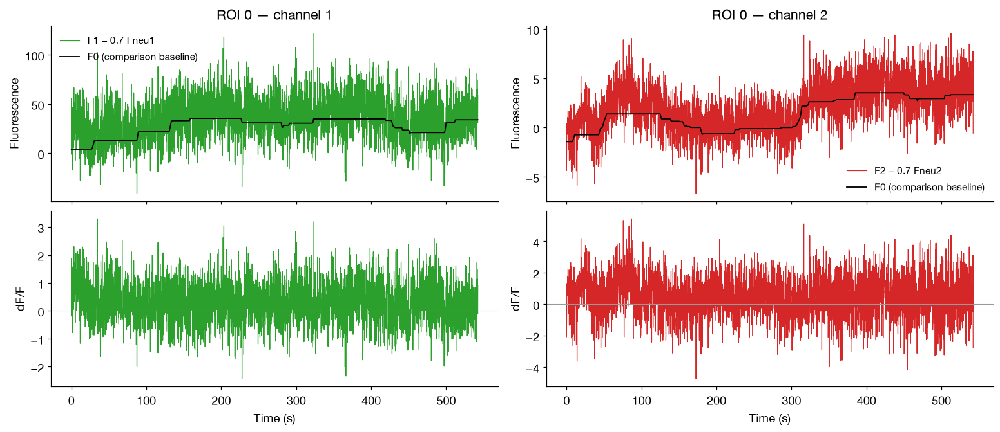

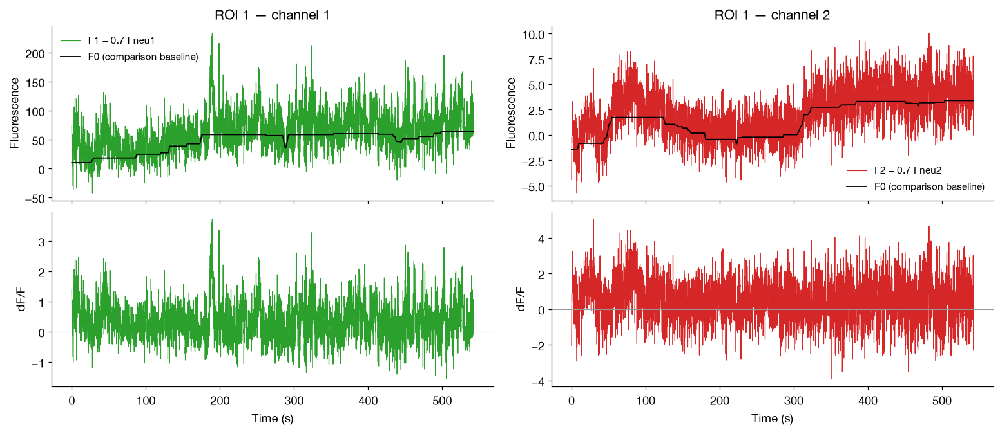

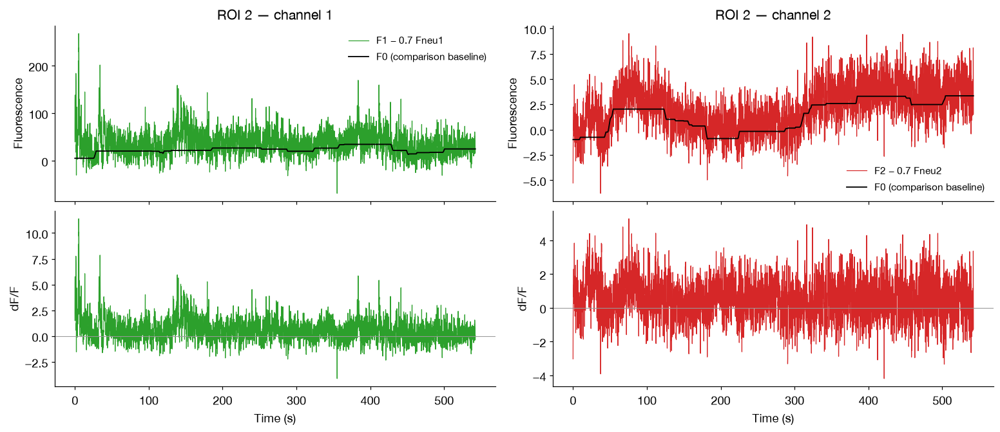

In [21]:
start = 0 if FRAME_START is None else int(FRAME_START)
stop = F.shape[1] if FRAME_STOP is None else min(int(FRAME_STOP), F.shape[1])
selection = slice(start, stop)
frame_numbers = np.arange(start, stop)
x = frame_numbers / ops['fs'] if USE_SECONDS else frame_numbers
x_label = 'Time (s)' if USE_SECONDS else 'Valid-frame index'

channel_traces = {}
for channel_id, f_name, fneu_name, color in [
    (1, 'F.npy', 'Fneu.npy', 'tab:green'),
    (2, 'F_chan2.npy', 'Fneu_chan2.npy', 'tab:red'),
]:
    channel_f_path = PLANE_DIR / f_name
    channel_fneu_path = PLANE_DIR / fneu_name
    if not channel_f_path.exists() or not channel_fneu_path.exists():
        print(f'Skipping channel {channel_id}: required files were not found')
        continue
    channel_f = np.load(channel_f_path).astype(np.float32)[:, frame_selector]
    channel_fneu = np.load(channel_fneu_path).astype(np.float32)[:, frame_selector]
    channel_corrected = channel_f - ops['neucoeff'] * channel_fneu
    channel_dff, channel_f0, _ = suite2p_dff_with_f0(channel_corrected, ops)
    channel_traces[channel_id] = (channel_corrected, channel_f0, channel_dff, color)

for roi in ROI_IDS:
    if not 0 <= roi < F.shape[0]:
        print(f'Skipping ROI {roi}; valid IDs are 0–{F.shape[0] - 1}')
        continue
    n_channels = len(channel_traces)
    fig, axes = plt.subplots(2, n_channels, figsize=(7 * n_channels, 6), sharex=True, squeeze=False, constrained_layout=True)
    for column, (channel_id, (channel_f, channel_f0, channel_dff, color)) in enumerate(channel_traces.items()):
        axes[0, column].plot(x, channel_f[roi, selection], color=color, lw=0.8, label=f"F{channel_id} − {ops['neucoeff']:g} Fneu{channel_id}")
        axes[0, column].plot(x, channel_f0[roi, selection], color='black', lw=1.2, label='F0 (comparison baseline)')
        axes[0, column].set_title(f'ROI {roi} — channel {channel_id}')
        axes[0, column].set_ylabel('Fluorescence')
        axes[0, column].legend(frameon=False)
        axes[1, column].plot(x, channel_dff[roi, selection], color=color, lw=0.8)
        axes[1, column].axhline(0, color='0.6', lw=0.7)
        axes[1, column].set_ylabel('dF/F')
        axes[1, column].set_xlabel(x_label)
    for ax in axes.flat:
        ax.spines[['top', 'right']].set_visible(False)
    plt.show()

### Green-channel-only view

This repeats the selected-ROI view using only channel 1. The fluorescence panel intentionally has no legend.

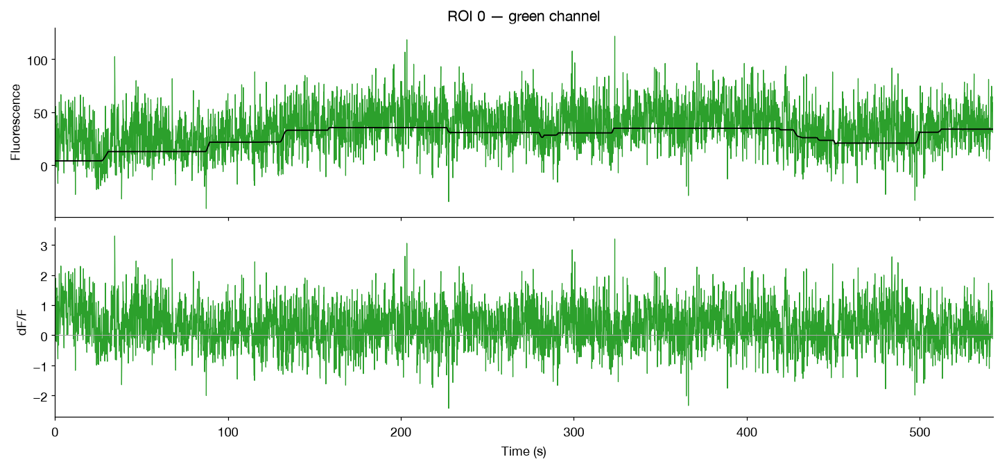

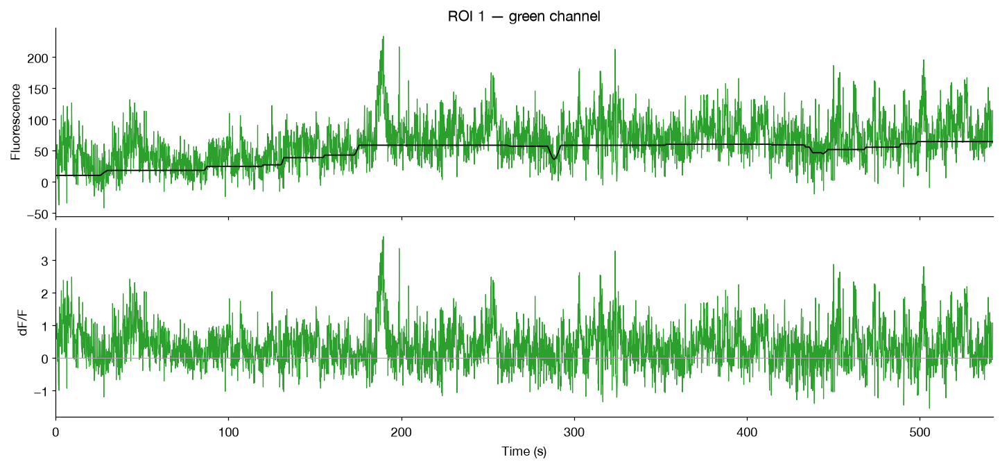

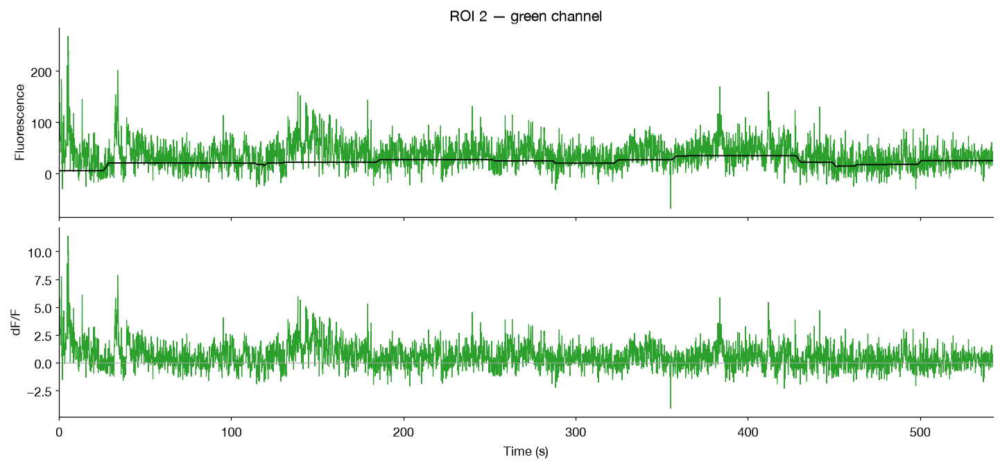

In [22]:
if 1 not in channel_traces:
    print('Channel 1 traces are unavailable.')
else:
    green_f, green_f0, green_dff, green_color = channel_traces[1]
    for roi in ROI_IDS:
        if not 0 <= roi < green_f.shape[0]:
            print(f'Skipping ROI {roi}; valid IDs are 0–{green_f.shape[0] - 1}')
            continue
        fig, axes = plt.subplots(
            2, 1, figsize=(13, 6), sharex=True,
            constrained_layout=True)
        axes[0].plot(
            x, green_f[roi, selection], color=green_color, lw=0.8)
        axes[0].plot(
            x, green_f0[roi, selection], color='black', lw=1.2)
        axes[0].set(
            title=f'ROI {roi} — green channel',
            ylabel='Fluorescence')
        axes[1].plot(
            x, green_dff[roi, selection], color=green_color, lw=0.8)
        axes[1].axhline(0, color='0.65', lw=0.7)
        axes[1].set(xlabel=x_label, ylabel='dF/F')
        for ax in axes:
            ax.margins(x=0)
        plt.show()

## Test for global illumination changes using channel 2

This comparison deliberately uses raw ROI and neuropil fluorescence, before subtraction or baseline division. Shared illumination changes should be simultaneous in green, red, and often neuropil signals. The channel ratio should suppress a truly multiplicative common-mode change.

Green/red global-level correlation: 0.086
Green/red frame-change correlation: 0.379
Green/red neuropil-change correlation: 0.429
Large positive change correlations support common illumination or motion artifacts.


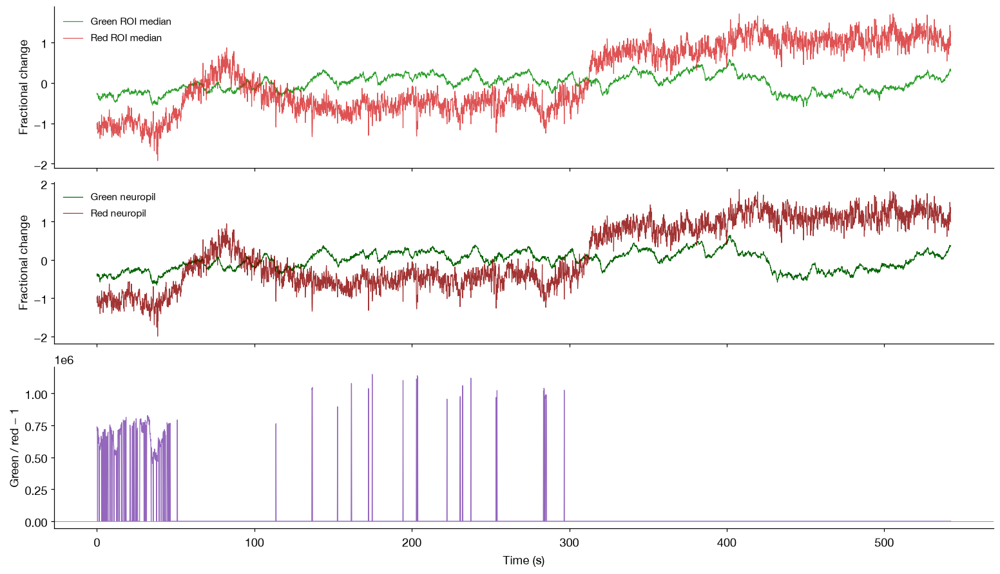

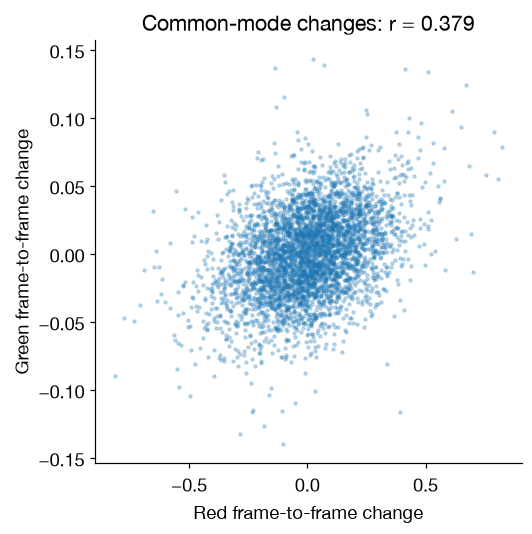

In [23]:
red_path = PLANE_DIR / 'F_chan2.npy'
red_neuropil_path = PLANE_DIR / 'Fneu_chan2.npy'
if not red_path.exists() or not red_neuropil_path.exists():
    print('Channel-2 traces were not found; cannot run the illumination comparison.')
else:
    green_raw = np.load(PLANE_DIR / 'F.npy').astype(np.float32)[:, frame_selector]
    red_raw = np.load(red_path).astype(np.float32)[:, frame_selector]
    green_neu = np.load(PLANE_DIR / 'Fneu.npy').astype(np.float32)[:, frame_selector]
    red_neu = np.load(red_neuropil_path).astype(np.float32)[:, frame_selector]
    if green_raw.shape != red_raw.shape:
        raise ValueError(f'Green shape {green_raw.shape} != red shape {red_raw.shape}')

    roi_mask = iscell if iscell is not None and np.any(iscell) else np.ones(green_raw.shape[0], bool)

    def global_fractional_trace(values, mask):
        selected = values[mask].astype(float)
        scale = np.nanmedian(selected, axis=1, keepdims=True)
        good = np.isfinite(scale[:, 0]) & (np.abs(scale[:, 0]) > 1e-6)
        return np.nanmedian(selected[good] / scale[good] - 1.0, axis=0)

    global_green = global_fractional_trace(green_raw, roi_mask)
    global_red = global_fractional_trace(red_raw, roi_mask)
    global_green_neu = global_fractional_trace(green_neu, roi_mask)
    global_red_neu = global_fractional_trace(red_neu, roi_mask)
    global_ratio = (1.0 + global_green) / np.maximum(1.0 + global_red, 1e-6) - 1.0

    level_corr = np.corrcoef(global_green, global_red)[0, 1]
    change_corr = np.corrcoef(np.diff(global_green), np.diff(global_red))[0, 1]
    neuropil_change_corr = np.corrcoef(np.diff(global_green_neu), np.diff(global_red_neu))[0, 1]
    print(f'Green/red global-level correlation: {level_corr:.3f}')
    print(f'Green/red frame-change correlation: {change_corr:.3f}')
    print(f'Green/red neuropil-change correlation: {neuropil_change_corr:.3f}')
    print('Large positive change correlations support common illumination or motion artifacts.')

    comparison_frames = np.arange(global_green.size)
    comparison_x = comparison_frames / ops['fs'] if USE_SECONDS else comparison_frames
    fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True, constrained_layout=True)
    axes[0].plot(comparison_x, global_green, color='tab:green', lw=0.8, label='Green ROI median')
    axes[0].plot(comparison_x, global_red, color='tab:red', lw=0.8, alpha=0.8, label='Red ROI median')
    axes[0].set_ylabel('Fractional change')
    axes[0].legend(frameon=False)
    axes[1].plot(comparison_x, global_green_neu, color='darkgreen', lw=0.8, label='Green neuropil')
    axes[1].plot(comparison_x, global_red_neu, color='darkred', lw=0.8, alpha=0.8, label='Red neuropil')
    axes[1].set_ylabel('Fractional change')
    axes[1].legend(frameon=False)
    axes[2].plot(comparison_x, global_ratio, color='tab:purple', lw=0.8)
    axes[2].axhline(0, color='0.6', lw=0.7)
    axes[2].set_ylabel('Green / red − 1')
    axes[2].set_xlabel('Time (s)' if USE_SECONDS else 'Valid-frame index')
    for ax in axes:
        ax.spines[['top', 'right']].set_visible(False)
    plt.show()

    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(np.diff(global_red), np.diff(global_green), s=4, alpha=0.25)
    ax.set_xlabel('Red frame-to-frame change')
    ax.set_ylabel('Green frame-to-frame change')
    ax.set_title(f'Common-mode changes: r = {change_corr:.3f}')
    ax.spines[['top', 'right']].set_visible(False)
    plt.show()

## Detect and inspect artifacts before regression

This section deliberately runs before every red-channel regression. It detects sharp population-wide changes from the standard-green trace. The resulting shared mask is excluded from all later regression fits. Choose whether affected frames become `NaN` or are linearly interpolated with `ARTIFACT_REPLACEMENT`. The diagnostic figure is followed by selected-ROI and first-20 stacked previews of the artifact-treated standard-green traces, still before any red regression.

Artifact-mask source: standard green
ROIs used for detection: 407
Frames detected before padding: 0
Frames excluded after padding: 0
Fraction of recording excluded: 0.000%
Final replacement after regression: nan


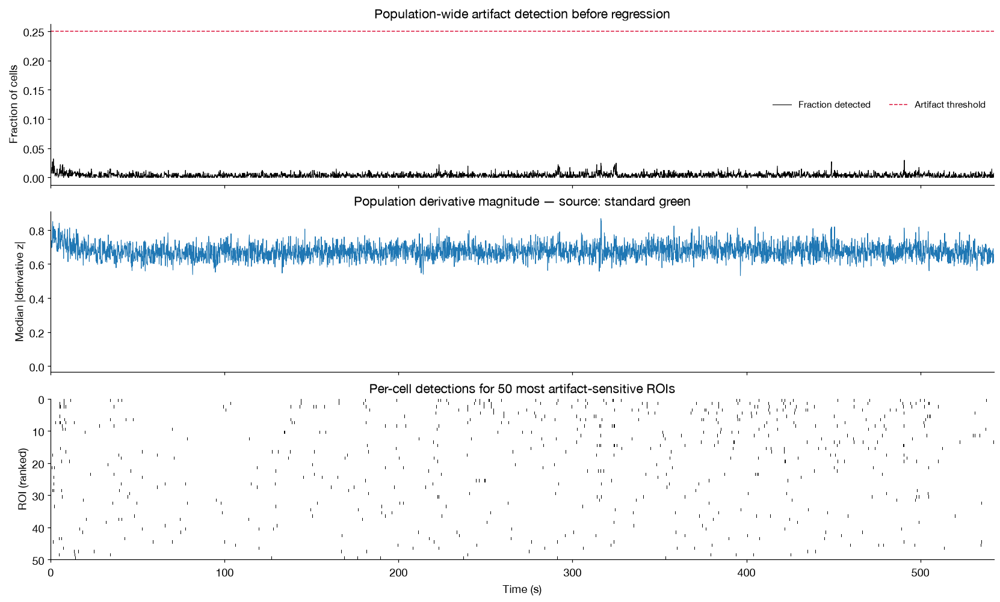

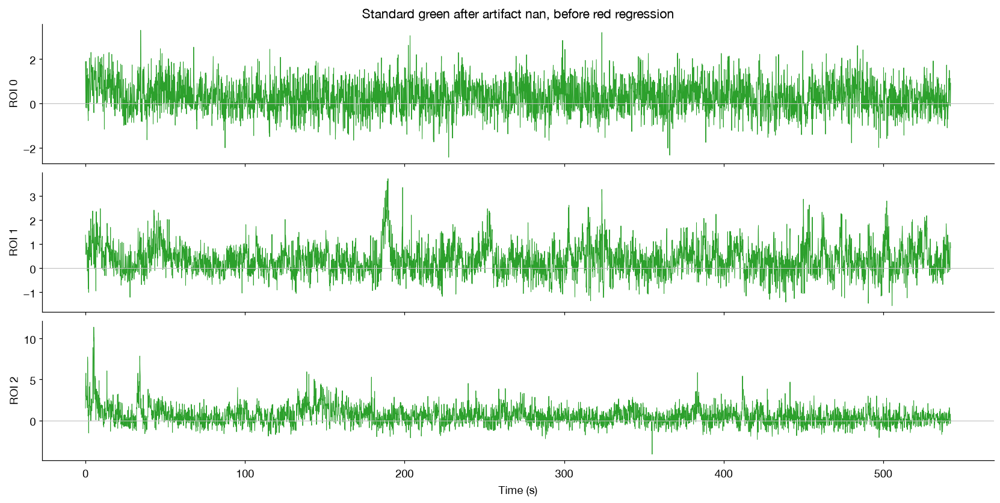

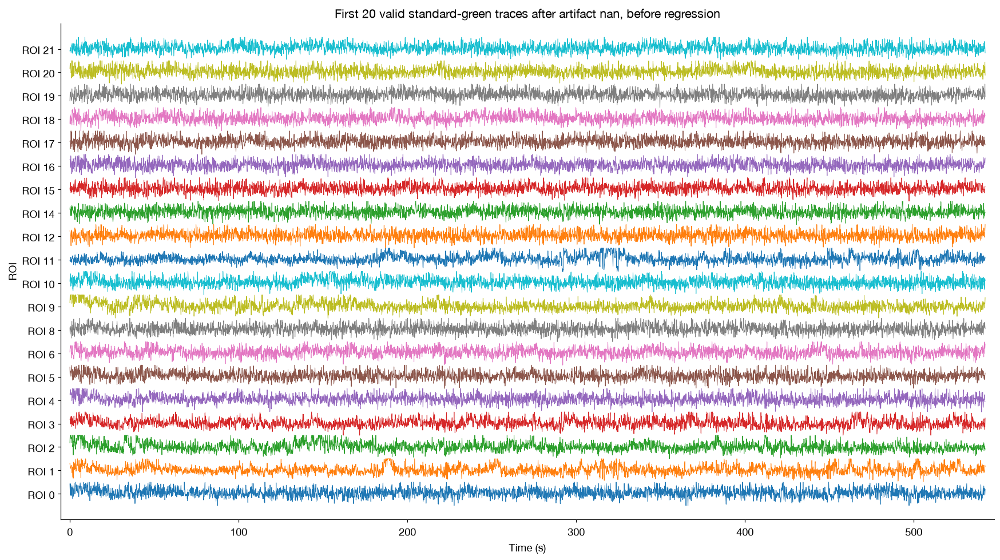

In [24]:
ARTIFACT_MASK_SOURCE = 'standard green'
ARTIFACT_DERIVATIVE_Z = 3.0
ARTIFACT_MIN_FRACTION_CELLS = 0.25
ARTIFACT_PADDING_FRAMES = 1
ARTIFACT_REPLACEMENT = 'nan'  # 'nan' or 'interpolate'
if ARTIFACT_REPLACEMENT not in {'nan', 'interpolate'}:
    raise ValueError("ARTIFACT_REPLACEMENT must be 'nan' or 'interpolate'")

artifact_source = np.asarray(dff, dtype=float)
artifact_candidate_rois = np.any(np.isfinite(artifact_source), axis=1)
if iscell is not None and np.any(iscell):
    artifact_candidate_rois &= iscell
artifact_roi_indices = np.flatnonzero(artifact_candidate_rois)
if artifact_roi_indices.size == 0:
    raise ValueError('No valid ROIs are available for artifact detection')

artifact_derivative = np.diff(
    artifact_source, axis=1, prepend=artifact_source[:, :1])
artifact_derivative_center = np.nanmedian(
    artifact_derivative, axis=1, keepdims=True)
artifact_derivative_mad = np.nanmedian(
    np.abs(artifact_derivative - artifact_derivative_center), axis=1, keepdims=True)
artifact_derivative_scale = 1.4826 * artifact_derivative_mad
artifact_derivative_scale[artifact_derivative_scale < 1e-12] = np.nan
artifact_derivative_z = (
    artifact_derivative - artifact_derivative_center) / artifact_derivative_scale
artifact_cells_spiking = np.abs(artifact_derivative_z) >= ARTIFACT_DERIVATIVE_Z
artifact_fraction_cells = np.mean(
    artifact_cells_spiking[artifact_roi_indices], axis=0)
artifact_frames = artifact_fraction_cells >= ARTIFACT_MIN_FRACTION_CELLS
artifact_frames_before_padding = artifact_frames.copy()
if ARTIFACT_PADDING_FRAMES > 0:
    artifact_kernel = np.ones(2 * ARTIFACT_PADDING_FRAMES + 1, dtype=int)
    artifact_frames = np.convolve(
        artifact_frames.astype(int), artifact_kernel, mode='same') > 0
regression_fit_frames = ~artifact_frames

print('Artifact-mask source:', ARTIFACT_MASK_SOURCE)
print('ROIs used for detection:', len(artifact_roi_indices))
print('Frames detected before padding:', artifact_frames_before_padding.sum())
print('Frames excluded after padding:', artifact_frames.sum())
print(f'Fraction of recording excluded: {100 * artifact_frames.mean():.3f}%')
print('Final replacement after regression:', ARTIFACT_REPLACEMENT)

artifact_x = np.arange(artifact_frames.size) / ops['fs'] if USE_SECONDS else np.arange(artifact_frames.size)
artifact_indices = np.flatnonzero(artifact_frames)
median_absolute_derivative_z = np.nanmedian(
    np.abs(artifact_derivative_z[artifact_roi_indices]), axis=0)
cell_artifact_counts = np.sum(
    artifact_cells_spiking[artifact_roi_indices], axis=1)
heatmap_order = artifact_roi_indices[np.argsort(cell_artifact_counts)[::-1]]
heatmap_rois = heatmap_order[:min(50, len(heatmap_order))]

fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True, constrained_layout=True)
axes[0].plot(artifact_x, artifact_fraction_cells, color='black', lw=0.7, label='Fraction detected')
axes[0].axhline(ARTIFACT_MIN_FRACTION_CELLS, color='crimson', ls='--', lw=1, label='Artifact threshold')
if artifact_indices.size:
    axes[0].scatter(artifact_x[artifact_indices], artifact_fraction_cells[artifact_indices], s=9, color='crimson', label='Excluded frames')
axes[0].set_ylabel('Fraction of cells')
axes[0].set_title('Population-wide artifact detection before regression')
axes[0].legend(frameon=False, ncols=3)
axes[1].plot(artifact_x, median_absolute_derivative_z, color='tab:blue', lw=0.7)
axes[1].fill_between(artifact_x, 0, median_absolute_derivative_z, where=artifact_frames, color='crimson', alpha=0.2, step='mid')
axes[1].set_ylabel('Median |derivative z|')
axes[1].set_title(f'Population derivative magnitude — source: {ARTIFACT_MASK_SOURCE}')
axes[2].imshow(
    artifact_cells_spiking[heatmap_rois], aspect='auto', interpolation='nearest',
    origin='upper', cmap='Greys',
    extent=[artifact_x[0], artifact_x[-1], len(heatmap_rois), 0])
for frame_index in artifact_indices:
    axes[2].axvline(artifact_x[frame_index], color='crimson', alpha=0.12, lw=0.5)
axes[2].set_ylabel('ROI (ranked)')
axes[2].set_xlabel('Time (s)' if USE_SECONDS else 'Valid-frame index')
axes[2].set_title(f'Per-cell detections for {len(heatmap_rois)} most artifact-sensitive ROIs')
for ax in axes[:2]:
    ax.spines[['top', 'right']].set_visible(False)
plt.show()

def replace_artifact_frames(traces, artifact_mask, replacement='nan'):
    """Apply one shared mask using NaNs or per-ROI linear interpolation."""
    cleaned = np.asarray(traces, dtype=np.float32).copy()
    artifact_mask = np.asarray(artifact_mask, dtype=bool)
    if replacement == 'nan':
        cleaned[:, artifact_mask] = np.nan
        return cleaned
    if replacement != 'interpolate':
        raise ValueError("replacement must be 'nan' or 'interpolate'")
    frame_numbers = np.arange(cleaned.shape[1])
    for roi in range(cleaned.shape[0]):
        retained = ~artifact_mask & np.isfinite(cleaned[roi])
        if retained.sum() >= 2:
            cleaned[roi, artifact_mask] = np.interp(
                frame_numbers[artifact_mask], frame_numbers[retained], cleaned[roi, retained])
        else:
            cleaned[roi, artifact_mask] = np.nan
    return cleaned

pre_regression_artifact_dff = replace_artifact_frames(
    artifact_source, artifact_frames, ARTIFACT_REPLACEMENT)
preview_x = np.arange(pre_regression_artifact_dff.shape[1])
preview_x = preview_x / ops['fs'] if USE_SECONDS else preview_x
preview_rois = [roi for roi in ROI_IDS if 0 <= roi < pre_regression_artifact_dff.shape[0]]
fig, axes = plt.subplots(
    len(preview_rois), 1, figsize=(15, max(3, 2.5 * len(preview_rois))),
    sharex=True, constrained_layout=True, squeeze=False)
for ax, roi in zip(axes[:, 0], preview_rois):
    ax.plot(preview_x, pre_regression_artifact_dff[roi], color='tab:green', lw=0.65)
    if artifact_indices.size:
        ax.scatter(
            preview_x[artifact_indices], pre_regression_artifact_dff[roi, artifact_indices],
            color='crimson', s=5, alpha=0.7, label=f'artifact {ARTIFACT_REPLACEMENT}')
    ax.axhline(0, color='0.75', lw=0.7)
    ax.set_ylabel(f'ROI {roi}')
    ax.spines[['top', 'right']].set_visible(False)
axes[0, 0].set_title(
    f'Standard green after artifact {ARTIFACT_REPLACEMENT}, before red regression')
axes[-1, 0].set_xlabel('Time (s)' if USE_SECONDS else 'Valid-frame index')
plt.show()

finite_preview = np.any(np.isfinite(pre_regression_artifact_dff), axis=1)
preview_candidates = finite_preview & iscell if iscell is not None and np.any(iscell) else finite_preview
preview_stacked_rois = np.flatnonzero(preview_candidates)[:20]
fig, ax = plt.subplots(figsize=(16, max(6, 0.45 * len(preview_stacked_rois))))
offsets = np.arange(len(preview_stacked_rois)) * 1.5
for offset, roi in zip(offsets, preview_stacked_rois):
    trace = np.asarray(pre_regression_artifact_dff[roi], dtype=float)
    lo, hi = np.nanpercentile(trace, [1, 95])
    if np.isfinite(hi - lo) and hi > lo:
        shown = np.clip((trace - lo) / (hi - lo), -0.25, 1.25)
        ax.plot(preview_x, shown + offset, lw=0.65)
ax.set_yticks(offsets + 0.5, [f'ROI {roi}' for roi in preview_stacked_rois])
ax.set(xlabel='Time (s)' if USE_SECONDS else 'Valid-frame index', ylabel='ROI',
       title=f'First {len(preview_stacked_rois)} valid standard-green traces after artifact {ARTIFACT_REPLACEMENT}, before regression')
ax.spines[['top', 'right']].set_visible(False)
ax.margins(x=0.01, y=0.03)
fig.tight_layout()
plt.show()

## Compare correction strategies

### Signal definitions

For ROI *i* and frame *t*, `Gᵢ(t)` and `Nᴳᵢ(t)` are the raw green ROI and green neuropil traces. `Rᵢ(t)` and `Nᴿᵢ(t)` are their structural-channel equivalents. The Suite2p neuropil coefficient is `c = ops['neucoeff']`, normally 0.7. The first operation shared by all additive methods is:

$$Gᶜᵢ(t) = Gᵢ(t) - cNᴳᵢ(t);   Rᶜᵢ(t) = Rᵢ(t) - cNᴿᵢ(t).$$

Here `Gᶜ` means neuropil-corrected green fluorescence—not dF/F. Before any regression, the detected artifact frames are replaced by the same linear interpolation in **both** `Gᶜ` and `Rᶜ`. This internal interpolation prevents missing values from contaminating median filtering or Suite2p baseline processing. The detected frames are still excluded from coefficient fitting. Finally, every signal and dF/F array is represented according to `ARTIFACT_REPLACEMENT`: either `NaN` or the interpolated values. Consequently, no regression or summary plot below should show the original artifact peaks.

### Suite2p baseline normalization

With the usual `baseline='maximin'`, Suite2p smooths each corrected trace, applies a running minimum, and then a running maximum. Call the resulting time-varying baseline `F₀ᵢ(t)` or `Flow`. The output is:

$$dF/F₀ᵢ(t) = [Fᵢ(t)-F₀ᵢ(t)] / max(mean_t F₀ᵢ(t), 10^{-3}).$$

This detail matters: Suite2p subtracts a time-varying baseline but divides by its time average. If mean F₀ is close to zero, small residual artifacts can become extremely large dF/F values.

### 1. Standard green

No structural-channel correction is performed: `Fᵢ(t) = Gᶜᵢ(t)`. This is the reference result and shows the full LED contamination.

### 2. Legacy median-filtered G/R ratio

Both corrected channels are median-filtered over approximately 0.25 s, then divided:

$$Qᵢ(t) = medfilt(Gᶜᵢ(t)) / max[medfilt(Rᶜᵢ(t)), p_{5,i}, 10^{-3}].$$

Suite2p preprocessing is then applied to `Q`. This assumes multiplicative contamination: both channels must be scaled by the same illumination factor. It is unsafe when neuropil-corrected red values approach or cross zero; replacing the denominator with `10⁻³` can create enormous ratios. It is retained only to reproduce `get_dff_GR`.

### 3. Global-red Huber regression

Each raw red ROI is normalized by its median, and the population median creates a global reference `r(t)`. Each green ROI is modelled as:

$$Gᶜᵢ(t) = αᵢ + βᵢr(t) + εᵢ(t);   Fᵢ(t)=Gᶜᵢ(t)-βᵢr(t).$$

Before this model is fitted, frames flagged by the population-wide artifact detector are excluded from the fit. Huber regression then reduces the influence of remaining green-only calcium transients. The fitted coefficient is applied to the complete trace, and flagged frames are subsequently stored as `NaN`.

### 4. Paired-red Huber regression

Instead of one population reference, every green ROI uses its matched standardized red trace `zᵢ(t) = [Rᶜᵢ(t)-median(Rᶜᵢ)]/MAD(Rᶜᵢ)`: 

$$Gᶜᵢ(t) = αᵢ + βᵢzᵢ(t) + εᵢ(t);   Fᵢ(t)=Gᶜᵢ(t)-βᵢzᵢ(t).$$

This allows the red coupling to vary spatially. Pre-detected artifact frames are excluded from fitting, and Huber remains robust to green-only transients among the retained frames. The shared artifact mask is applied after calculation for storage and plotting.

### 5. Paired-red ordinary least squares (OLS)

This uses the same paired standardized red predictor but minimizes ordinary squared error:

$$[αᵢ,βᵢ] = argmin_{α,β} Σ_t [Gᶜᵢ(t)-α-βzᵢ(t)]^2.$$

The corrected signal is again `Fᵢ(t)=Gᶜᵢ(t)-βᵢzᵢ(t)`; the fitted intercept is not removed. Pre-detected artifact frames are excluded from OLS fitting, so coefficients describe green/red coupling during retained frames rather than being dominated by the sharp LED transitions. OLS remains more sensitive than Huber to large retained green events.

### 6. Paired-red OLS without MAD scaling

This variant uses only median-centred red fluorescence in its original units: `xᵢ(t)=Rᶜᵢ(t)-median(Rᶜᵢ)`. It fits `Gᶜᵢ(t)=αᵢ+bᵢxᵢ(t)+εᵢ(t)` independently for every ROI. With one predictor and ordinary unregularized least squares, scaling by MAD cannot change the fitted artifact: if `zᵢ=xᵢ/MADᵢ`, then its fitted slope is `βᵢ=bᵢ·MADᵢ`, giving `βᵢzᵢ=bᵢxᵢ`. Thus the scaled and unscaled corrected traces should agree to floating-point precision. The notebook prints their maximum difference. The unscaled coefficient is often easier to interpret: it is green fluorescence units removed per red fluorescence unit.

### 7. Red-transition weighted Ridge (experimental)

This model uses lagged red values, the red derivative, and a squared red term, and gives strong **retained** red transitions extra weight; already-detected artifact frames are excluded. Ridge regularization penalizes large coefficients. Correlated predictors can still cause overshoot or ringing, so this method remains an explicitly experimental negative control rather than a recommended default.

### 8. Red plus measured LED state (optional)

When an LED-state vector exists, global red and LED state are fitted together. Because no LED-state record is available for this dataset, this method will be skipped automatically.

In [25]:
def run_preprocess(values):
    # Always return normalized dF/F, independent of the installed Suite2p version.
    return suite2p_dff_with_f0(values, ops)[0]

def robust_residualize(traces, regressors, fit_frames=None):
    traces = np.asarray(traces, float)
    X = np.asarray(regressors, float)
    X = X[:, None] if X.ndim == 1 else X
    cleaned = traces.copy()
    coefficients = np.full((traces.shape[0], X.shape[1]), np.nan)
    finite_x = np.all(np.isfinite(X), axis=1)
    if fit_frames is not None:
        finite_x &= np.asarray(fit_frames, dtype=bool)
    for roi, y in enumerate(traces):
        keep = finite_x & np.isfinite(y)
        if keep.sum() < X.shape[1] + 5:
            continue
        model = HuberRegressor(epsilon=1.35, max_iter=500).fit(X[keep], y[keep])
        cleaned[roi] = y - X @ model.coef_
        coefficients[roi] = model.coef_
    return cleaned, coefficients

if not red_path.exists() or not red_neuropil_path.exists():
    method_signal = {'standard green': F}
    method_dff = {'standard green': dff}
else:
    G_corr_raw = green_raw - ops['neucoeff'] * green_neu
    R_corr_raw = red_raw - ops['neucoeff'] * red_neu
    # Remove the detected frames from BOTH channels before regression.
    # Internal interpolation keeps median filters and Suite2p preprocessing
    # numerically defined; ARTIFACT_REPLACEMENT is applied to outputs below.
    G_corr = replace_artifact_frames(G_corr_raw, artifact_frames, 'interpolate')
    R_corr = replace_artifact_frames(R_corr_raw, artifact_frames, 'interpolate')
    global_red_regression = replace_artifact_frames(
        global_red[None, :], artifact_frames, 'interpolate')[0]
    method_signal = {'standard green': G_corr}
    method_dff = {'standard green': run_preprocess(G_corr)}

    # Reproduce get_dff_GR exactly.
    w = int(ops['fs'] * 0.25) | 1
    G_med = medfilt(G_corr, kernel_size=(1, w))
    R_med = medfilt(R_corr, kernel_size=(1, w))
    R_floor = np.maximum(np.percentile(R_med, 5, axis=1, keepdims=True), 1e-3)
    legacy_ratio = G_med / np.maximum(R_med, R_floor)
    method_signal['legacy G/R ratio'] = legacy_ratio
    method_dff['legacy G/R ratio'] = run_preprocess(legacy_ratio)

    G_global, beta_global = robust_residualize(
        G_corr, global_red_regression, fit_frames=regression_fit_frames)
    method_signal['global-red regression'] = G_global
    method_dff['global-red regression'] = run_preprocess(G_global)

    R_center = np.nanmedian(R_corr, axis=1, keepdims=True)
    R_scale = np.maximum(np.nanmedian(np.abs(R_corr - R_center), axis=1, keepdims=True), 1e-6)
    R_z = (R_corr - R_center) / R_scale
    G_paired = np.empty_like(G_corr, dtype=float)
    beta_paired = np.full(G_corr.shape[0], np.nan)
    for roi in range(G_corr.shape[0]):
        cleaned, coefficient = robust_residualize(
            G_corr[roi:roi + 1], R_z[roi], fit_frames=regression_fit_frames)
        G_paired[roi], beta_paired[roi] = cleaned[0], coefficient[0, 0]
    method_signal['paired-red regression'] = G_paired
    method_dff['paired-red regression'] = run_preprocess(G_paired)

    # Paired-red ordinary least squares: same predictor as paired Huber,
    # but large shared LED events are not downweighted as outliers.
    G_paired_ols = np.empty_like(G_corr, dtype=float)
    beta_paired_ols = np.full(G_corr.shape[0], np.nan)
    r2_paired_ols = np.full(G_corr.shape[0], np.nan)
    for roi, y in enumerate(G_corr):
        predictor = R_z[roi]
        keep = regression_fit_frames & np.isfinite(y) & np.isfinite(predictor)
        if keep.sum() < 5:
            G_paired_ols[roi] = y
            continue
        model = LinearRegression(fit_intercept=True)
        model.fit(predictor[keep, None], y[keep])
        predicted_artifact = model.coef_[0] * predictor
        G_paired_ols[roi] = y - predicted_artifact
        beta_paired_ols[roi] = model.coef_[0]
        r2_paired_ols[roi] = model.score(predictor[keep, None], y[keep])
    method_signal['paired-red OLS'] = G_paired_ols
    method_dff['paired-red OLS'] = run_preprocess(G_paired_ols)

    # The same OLS model using median-centred red in its original units.
    # With one unregularized predictor this should be mathematically
    # equivalent to MAD-scaled OLS; only the reported slope units differ.
    R_centered_unscaled = R_corr - R_center
    G_paired_ols_unscaled = np.empty_like(G_corr, dtype=float)
    beta_paired_ols_unscaled = np.full(G_corr.shape[0], np.nan)
    for roi, y in enumerate(G_corr):
        predictor = R_centered_unscaled[roi]
        keep = regression_fit_frames & np.isfinite(y) & np.isfinite(predictor)
        if keep.sum() < 5:
            G_paired_ols_unscaled[roi] = y
            continue
        model = LinearRegression(fit_intercept=True)
        model.fit(predictor[keep, None], y[keep])
        G_paired_ols_unscaled[roi] = y - model.coef_[0] * predictor
        beta_paired_ols_unscaled[roi] = model.coef_[0]
    method_signal['paired-red OLS unscaled'] = G_paired_ols_unscaled
    method_dff['paired-red OLS unscaled'] = run_preprocess(G_paired_ols_unscaled)
    print('Max fluorescence difference, scaled vs unscaled paired OLS:',
          np.nanmax(np.abs(G_paired_ols - G_paired_ols_unscaled)))

    # Infer LED transitions from red alone. Unlike Huber regression, this
    # deliberately gives the largest red transitions more influence.
    red_change = np.diff(global_red_regression, prepend=global_red_regression[0])
    red_change_center = np.nanmedian(red_change)
    red_change_mad = np.nanmedian(np.abs(red_change - red_change_center))
    red_change_z = 0.6745 * (red_change - red_change_center) / max(red_change_mad, 1e-12)
    transition_weights = 1.0 + 20.0 * np.clip(np.abs(red_change_z) / 8.0, 0, 1)
    red_predictors = np.column_stack([
        np.roll(global_red_regression, 1), global_red_regression,
        np.roll(global_red_regression, -1), red_change, global_red_regression ** 2,
    ])
    predictor_center = np.nanmedian(red_predictors, axis=0, keepdims=True)
    predictor_scale = np.nanmedian(
        np.abs(red_predictors - predictor_center), axis=0, keepdims=True)
    predictor_scale = np.maximum(predictor_scale, 1e-6)
    red_predictors_z = (red_predictors - predictor_center) / predictor_scale
    ridge_fit_frames = regression_fit_frames & np.all(np.isfinite(red_predictors_z), axis=1)
    ridge_fit_frames[[0, -1]] = False  # rolled predictors wrap at the edges
    G_weighted_ridge = G_corr.astype(float).copy()
    beta_weighted_ridge = np.full((G_corr.shape[0], red_predictors_z.shape[1]), np.nan)
    for roi, y in enumerate(G_corr):
        keep = ridge_fit_frames & np.isfinite(y)
        model = Ridge(alpha=1e-3, fit_intercept=True)
        model.fit(
            red_predictors_z[keep], y[keep],
            sample_weight=transition_weights[keep])
        predicted_artifact = red_predictors_z @ model.coef_
        G_weighted_ridge[roi] = y - predicted_artifact
        beta_weighted_ridge[roi] = model.coef_
    method_signal['red-transition weighted Ridge'] = G_weighted_ridge
    method_dff['red-transition weighted Ridge'] = run_preprocess(G_weighted_ridge)

    if LED_STATE_PATH is not None:
        led_state = np.asarray(np.load(LED_STATE_PATH), float).squeeze()[frame_selector]
        if led_state.size != G_corr.shape[1]:
            raise ValueError('LED state length does not match selected fluorescence frames')
        led_state -= np.nanmedian(led_state)
        G_led, beta_led = robust_residualize(
            G_corr, np.column_stack([global_red_regression, led_state]),
            fit_frames=regression_fit_frames)
        method_signal['red + LED regression'] = G_led
        method_dff['red + LED regression'] = run_preprocess(G_led)

# Apply the requested representation immediately, before any method plots.
# With 'nan', contaminated frames are absent from both signals and dF/F.
# With 'interpolate', all methods retain the same interpolated samples.
method_signal = {
    name: replace_artifact_frames(values, artifact_frames, ARTIFACT_REPLACEMENT)
    for name, values in method_signal.items()
}
method_dff = {
    name: replace_artifact_frames(values, artifact_frames, ARTIFACT_REPLACEMENT)
    for name, values in method_dff.items()
}
print('Calculated methods:', list(method_dff))
print('Green and red regression inputs were interpolated across detected artifacts.')
print('All plotted method outputs use artifact replacement:', ARTIFACT_REPLACEMENT)

Max fluorescence difference, scaled vs unscaled paired OLS: 1.52587890625e-05


/Users/megyoung/anaconda3/envs/mini2p-preprocessing/lib/python3.11/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 2.288769707092797e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/Users/megyoung/anaconda3/envs/mini2p-preprocessing/lib/python3.11/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 2.288769707092797e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/Users/megyoung/anaconda3/envs/mini2p-preprocessing/lib/python3.11/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 2.288769707092797e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/Users/megyoung/anaconda3/envs/mini2p-preprocessing/lib/python3.11/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slic

Calculated methods: ['standard green', 'legacy G/R ratio', 'global-red regression', 'paired-red regression', 'paired-red OLS', 'paired-red OLS unscaled', 'red-transition weighted Ridge']
Green and red regression inputs were interpolated across detected artifacts.
All plotted method outputs use artifact replacement: nan


## Evaluate the methods

Prefer a method that reduces residual coupling between the corrected fluorescence and red without erasing ROI-specific green transients. `level r` compares population corrected fluorescence with global red; `change r` compares their frame-to-frame changes. A huge `|dF/F| p99` identifies residual artifacts or an unstable Suite2p denominator. Correlation alone cannot select the winner because an overly aggressive method can force correlation toward zero while removing real signal.

Method                         level r   change r   median |dF/F| p99
---------------------------------------------------------------------------
standard green                    0.075      0.162               2.217
legacy G/R ratio                 -0.302     -0.260              24.653
global-red regression             0.000      0.113               2.209
paired-red regression            -0.092      0.054               2.206
paired-red OLS                   -0.093      0.054               2.211
paired-red OLS unscaled          -0.093      0.054               2.211
red-transition weighted Ridge     0.022      0.009               2.197


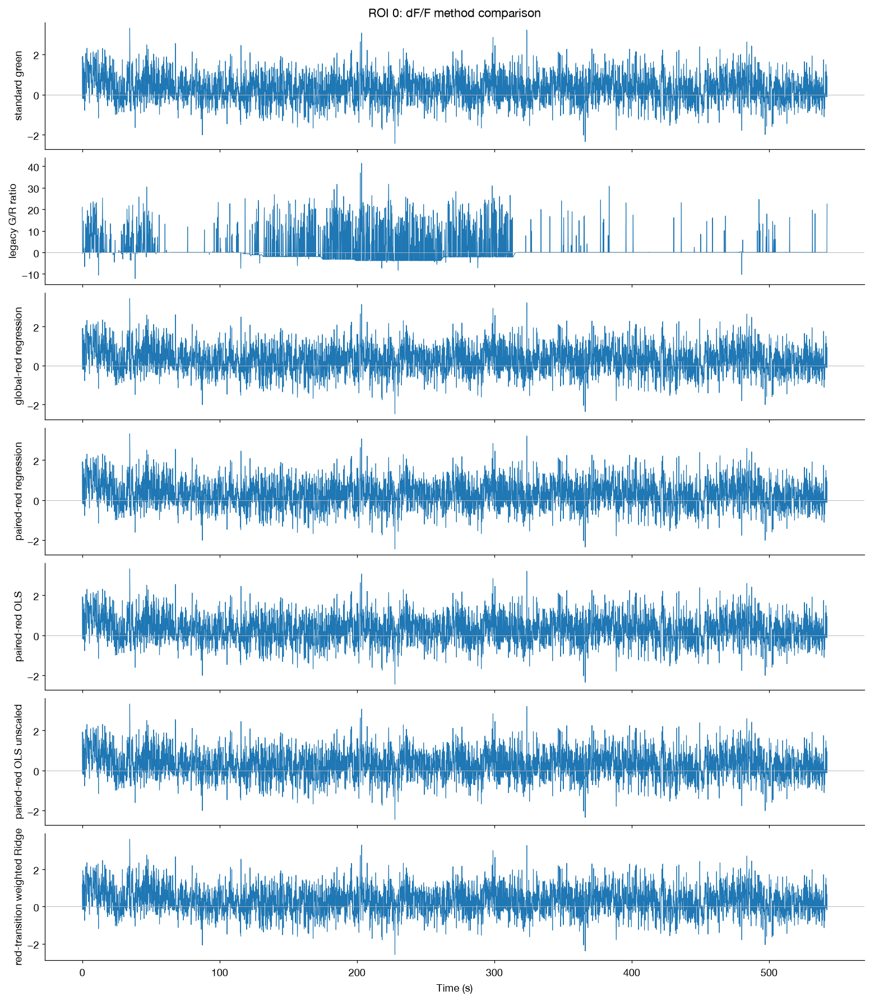

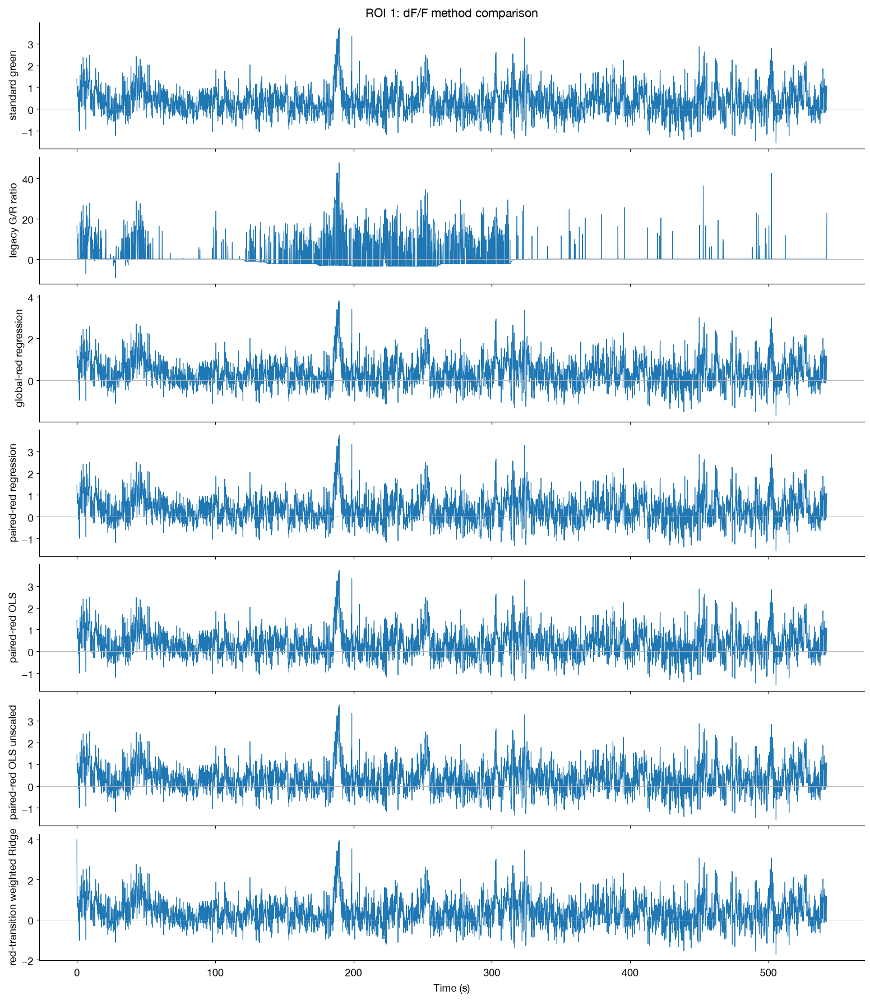

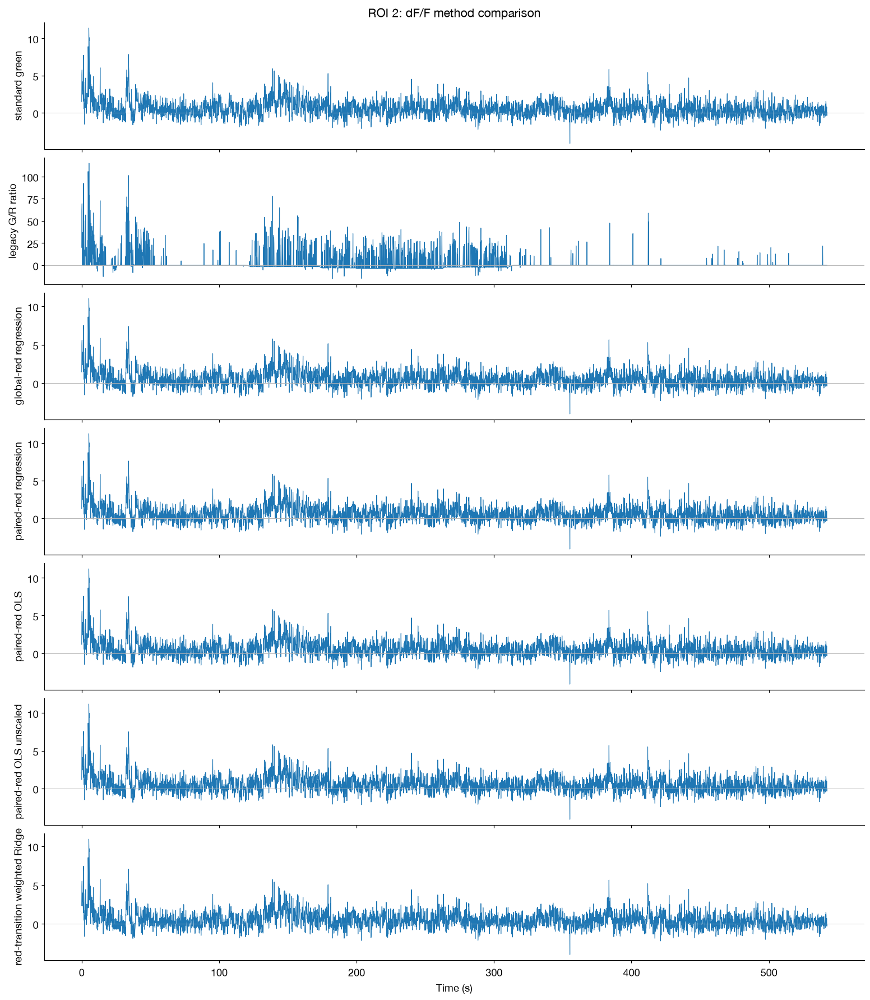

In [26]:
def finite_corr(a, b):
    keep = np.isfinite(a) & np.isfinite(b)
    return np.corrcoef(a[keep], b[keep])[0, 1] if keep.sum() > 2 else np.nan

print('Method                         level r   change r   median |dF/F| p99')
print('-' * 75)
for name, result in method_dff.items():
    signal = method_signal[name]
    mask = roi_mask if 'roi_mask' in globals() else np.ones(result.shape[0], bool)
    population = np.nanmedian(signal[mask], axis=0)
    level_r = finite_corr(population, global_red_regression) if 'global_red_regression' in globals() else np.nan
    change_r = finite_corr(np.diff(population), np.diff(global_red_regression)) if 'global_red_regression' in globals() else np.nan
    p99 = np.nanmedian(np.nanpercentile(np.abs(result), 99, axis=1))
    print(f'{name:30s} {level_r:8.3f}  {change_r:9.3f}  {p99:18.3f}')

for roi in ROI_IDS:
    if not 0 <= roi < F.shape[0]:
        continue
    fig, axes = plt.subplots(len(method_dff), 1, figsize=(14, 2.3 * len(method_dff)), sharex=True, constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, (name, result) in zip(axes, method_dff.items()):
        ax.plot(x, result[roi, selection], lw=0.75)
        ax.axhline(0, color='0.7', lw=0.6)
        ax.set_ylabel(name)
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].set_title(f'ROI {roi}: dF/F method comparison')
    axes[-1].set_xlabel(x_label)
    plt.show()

## Method comparison with 1st–99th percentile scaling

This repeats the method comparison while setting each panel's y-axis from the 1st to the 99th percentile of the displayed ROI and time window. Extreme values remain in the data; only the display limits change.

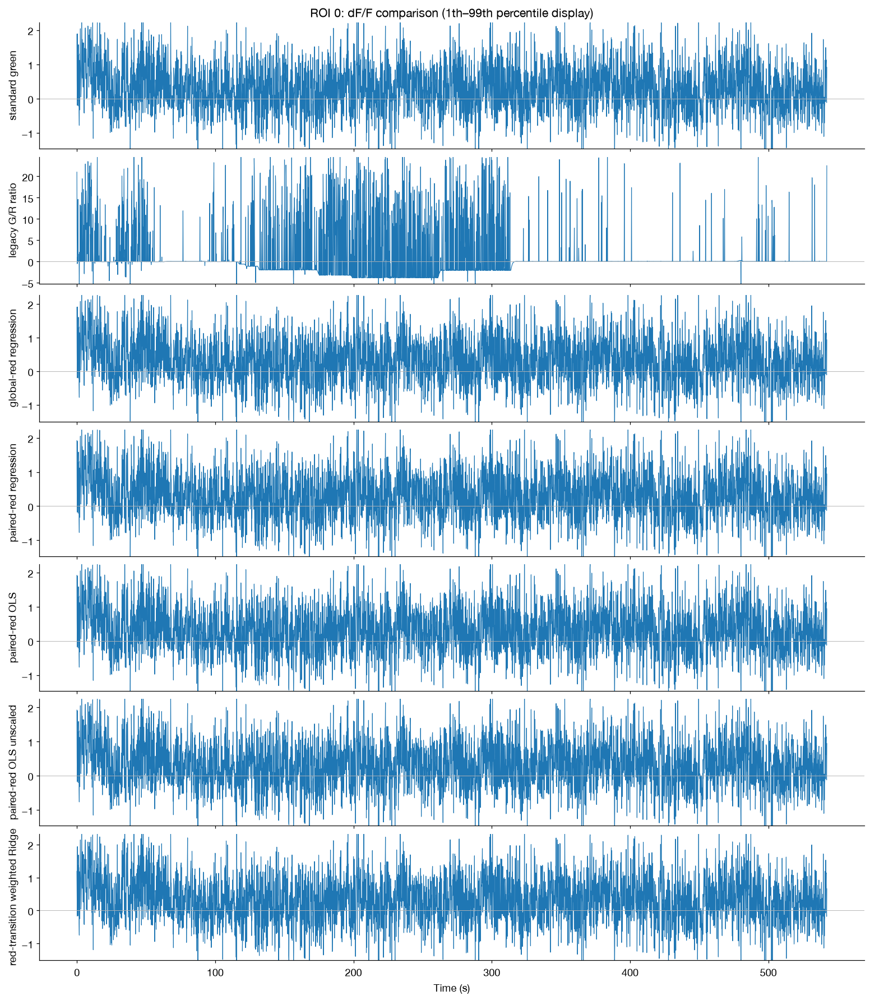

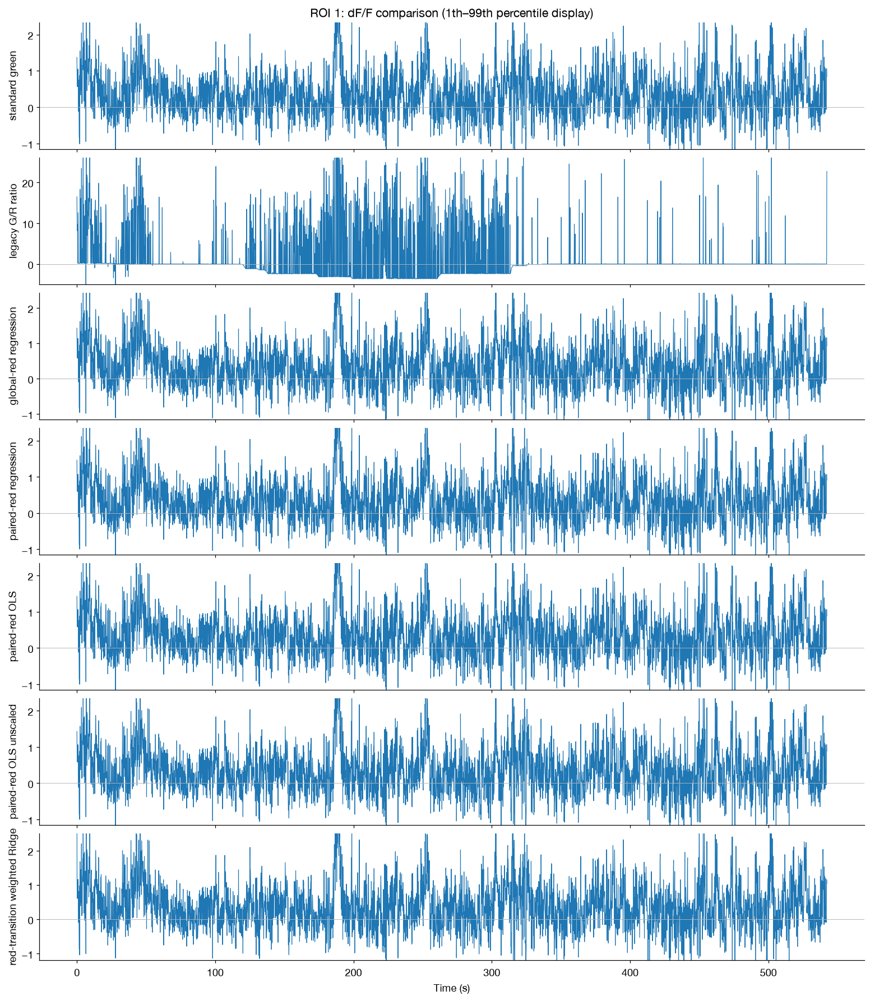

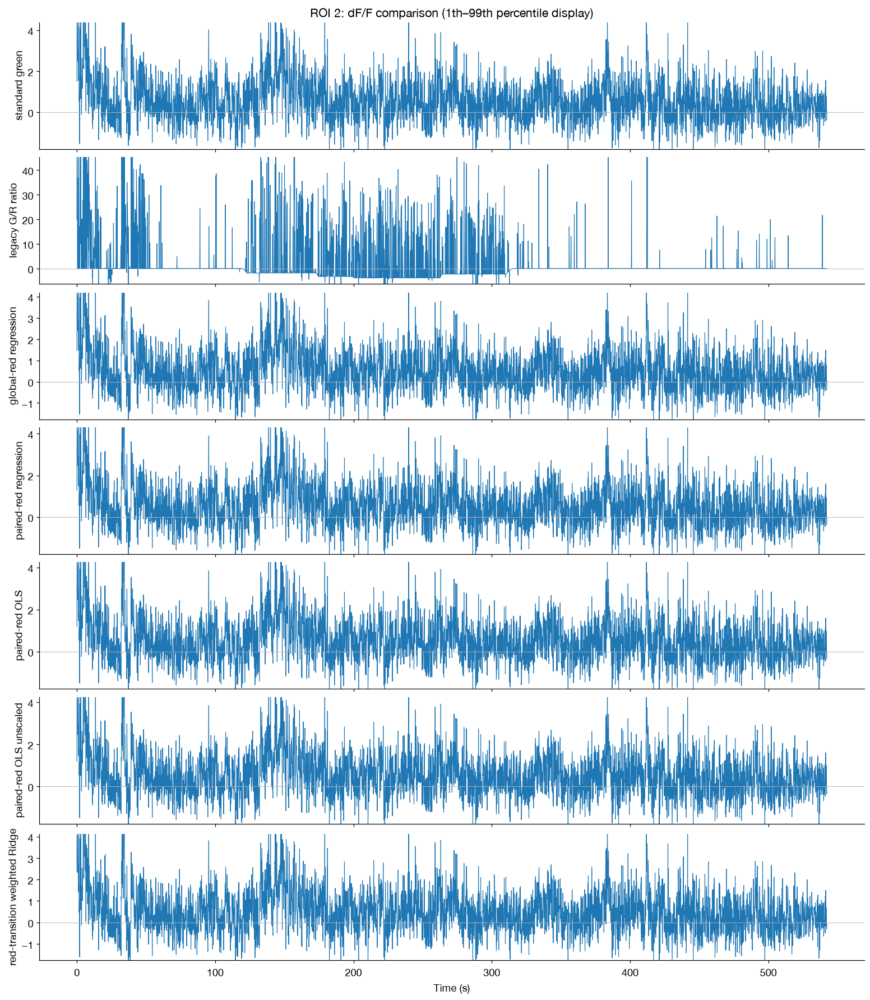

In [27]:
DISPLAY_PERCENTILES = (1, 99)

for roi in ROI_IDS:
    if not 0 <= roi < F.shape[0]:
        continue
    fig, axes = plt.subplots(
        len(method_dff), 1, figsize=(14, 2.3 * len(method_dff)),
        sharex=True, constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, (name, result) in zip(axes, method_dff.items()):
        displayed = result[roi, selection]
        ax.plot(x, displayed, lw=0.75)
        ax.axhline(0, color='0.7', lw=0.6)
        finite = displayed[np.isfinite(displayed)]
        if finite.size:
            lower, upper = np.percentile(finite, DISPLAY_PERCENTILES)
            if upper > lower:
                padding = 0.05 * (upper - lower)
                ax.set_ylim(lower - padding, upper + padding)
        ax.set_ylabel(name)
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].set_title(f'ROI {roi}: dF/F comparison ({DISPLAY_PERCENTILES[0]}th–{DISPLAY_PERCENTILES[1]}th percentile display)')
    axes[-1].set_xlabel(x_label)
    plt.show()

## Final outputs: first 20 valid ROIs for each method

These plots use the final method arrays after artifact handling and regression. Each ROI is independently rescaled using its selected percentile range and vertically offset. Amplitudes cannot be compared across ROIs because every trace has its own display scale.

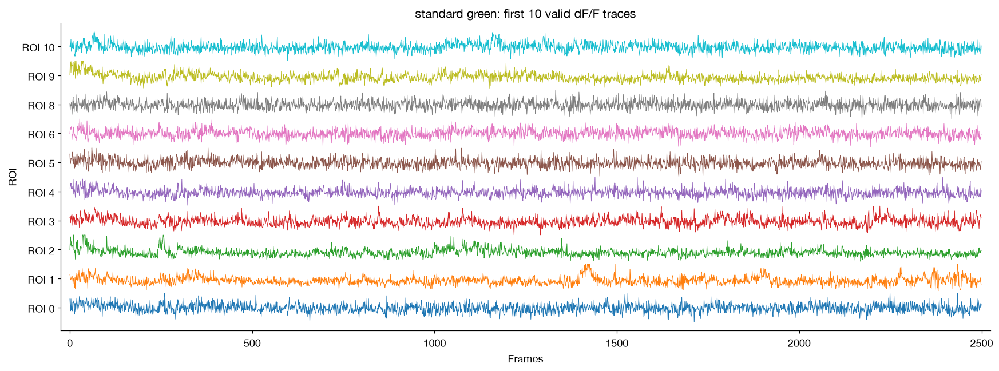

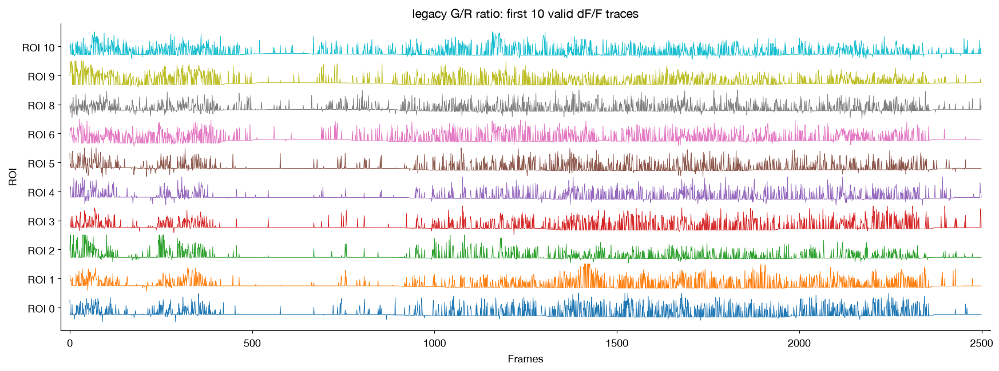

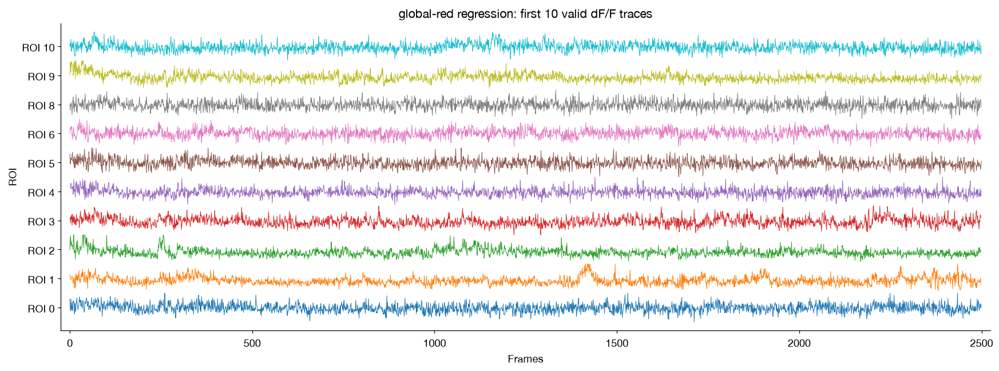

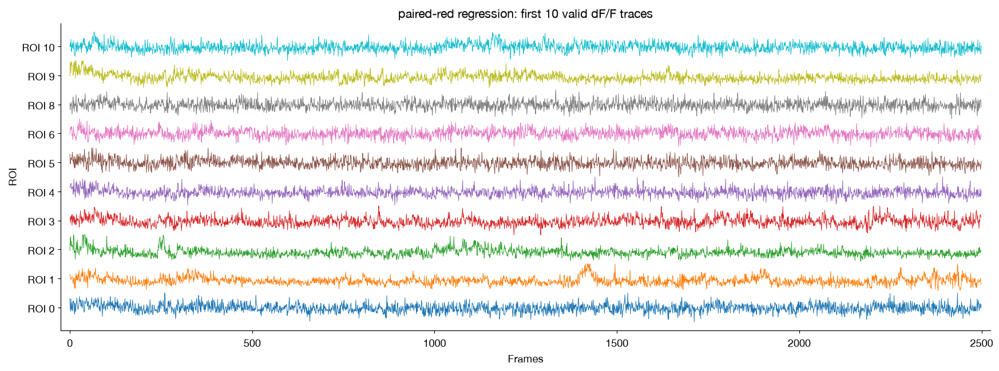

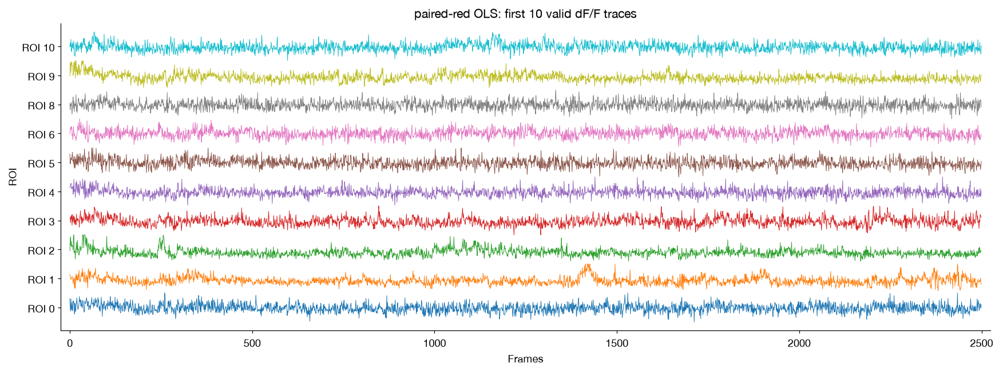

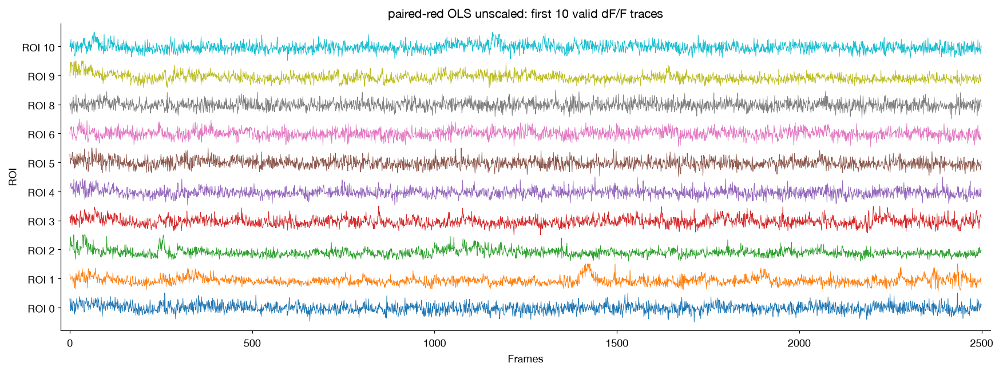

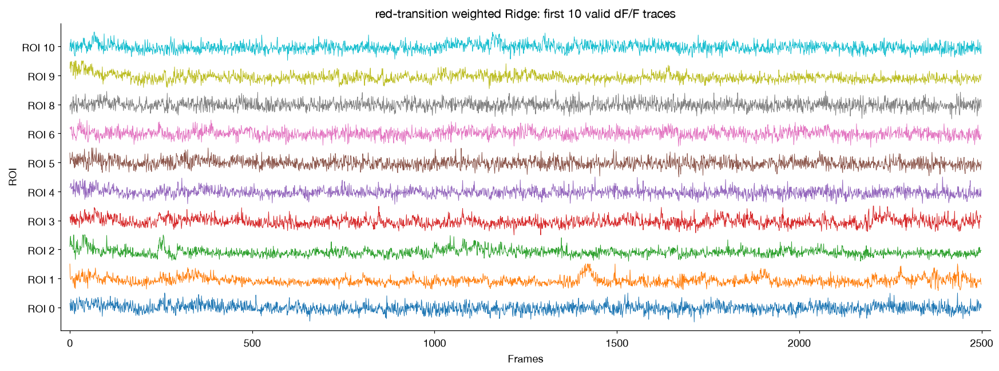

In [28]:
def plot_stacked_traces(
    traces, roi_indices, start_frame=0, end_frame=2500,
    low=1, high=95, spacing=1.5, title='Stacked traces',
):
    roi_indices = np.asarray(roi_indices, dtype=int)
    end_frame = min(int(end_frame), traces.shape[1])
    frame_slice = slice(int(start_frame), end_frame)
    frames = np.arange(traces.shape[1])[frame_slice]
    offsets = np.arange(len(roi_indices)) * spacing
    colors = plt.cm.tab10(np.arange(len(roi_indices)) % 10)
    fig, ax = plt.subplots(figsize=(16, max(6, 0.45 * len(roi_indices))))
    shown_rois, shown_offsets = [], []
    for offset, color, roi in zip(offsets, colors, roi_indices):
        trace = np.asarray(traces[roi, frame_slice], dtype=float)
        lo, hi = np.nanpercentile(trace, [low, high])
        scale = hi - lo
        if not np.isfinite(scale) or scale <= 0:
            continue
        shown = np.clip((trace - lo) / scale, -0.25, 1.25)
        ax.plot(frames, shown + offset, color=color, lw=0.65)
        shown_rois.append(roi)
        shown_offsets.append(offset)
    ax.set_yticks(np.asarray(shown_offsets) + 0.5, [f'ROI {roi}' for roi in shown_rois])
    ax.set(xlabel='Frames', ylabel='ROI', title=title)
    ax.spines[['top', 'right']].set_visible(False)
    ax.margins(x=0.01, y=0.03)
    fig.tight_layout()
    plt.show()

N_STACKED_ROIS = 10
STACKED_START_FRAME = 0
STACKED_END_FRAME = 2500
STACKED_PERCENTILES = (1, 99)

finite_standard = np.any(np.isfinite(method_dff['standard green']), axis=1)
if iscell is not None and np.any(iscell):
    valid_roi_indices = np.flatnonzero(finite_standard & iscell)
else:
    valid_roi_indices = np.flatnonzero(finite_standard)
stacked_rois = valid_roi_indices[:N_STACKED_ROIS]

for method_name, method_values in method_dff.items():
    plot_stacked_traces(
        method_values, stacked_rois,
        start_frame=STACKED_START_FRAME, end_frame=STACKED_END_FRAME,
        low=STACKED_PERCENTILES[0], high=STACKED_PERCENTILES[1],
        title=f'{method_name}: first {len(stacked_rois)} valid dF/F traces',
    )

## Final outputs: twenty most responsive ROIs for each method

For each correction method independently, ROIs are ranked from the same final arrays by their maximum finite dF/F. The top 20 valid cells are plotted with the same stacked-trace scaling used above. No additional artifact replacement occurs in this section.


standard green
ROI IDs: [2, 317, 319, 318, 316, 320, 336, 31, 227, 363, 357, 296, 337, 55, 40, 255, 352, 52, 315, 354]
Maximum dF/F: [11.388, 10.78, 9.206, 8.451, 8.357, 7.67, 7.089, 6.892, 6.562, 6.508, 6.507, 6.506, 6.504, 6.296, 6.172, 6.148, 6.137, 6.022, 6.01, 5.862]


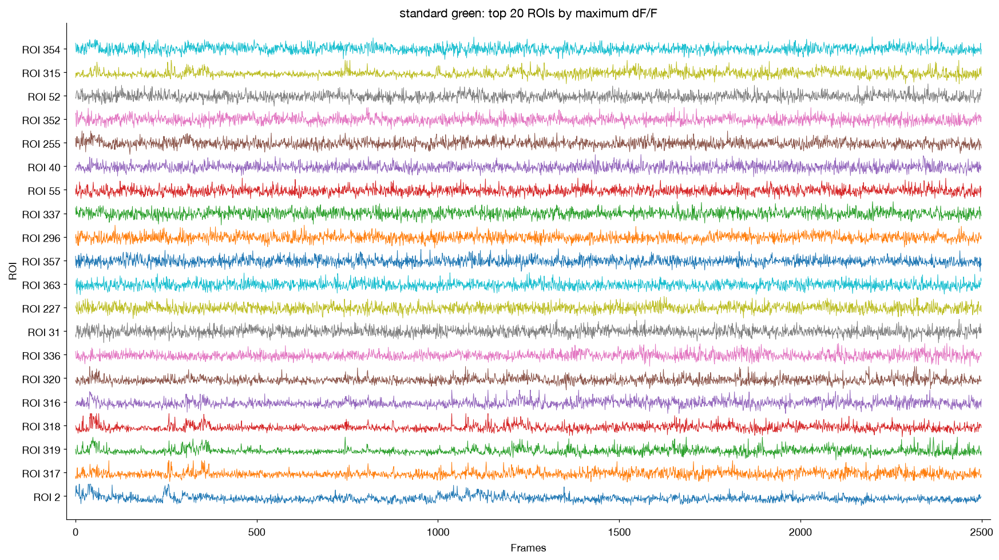


legacy G/R ratio
ROI IDs: [382, 336, 313, 362, 387, 337, 415, 287, 303, 363, 223, 52, 292, 279, 238, 359, 2, 410, 352, 380]
Maximum dF/F: [311.093, 258.295, 236.644, 145.315, 143.461, 137.966, 137.551, 135.807, 131.457, 130.059, 126.802, 121.132, 120.573, 120.14, 119.651, 116.603, 115.105, 113.061, 109.444, 106.437]


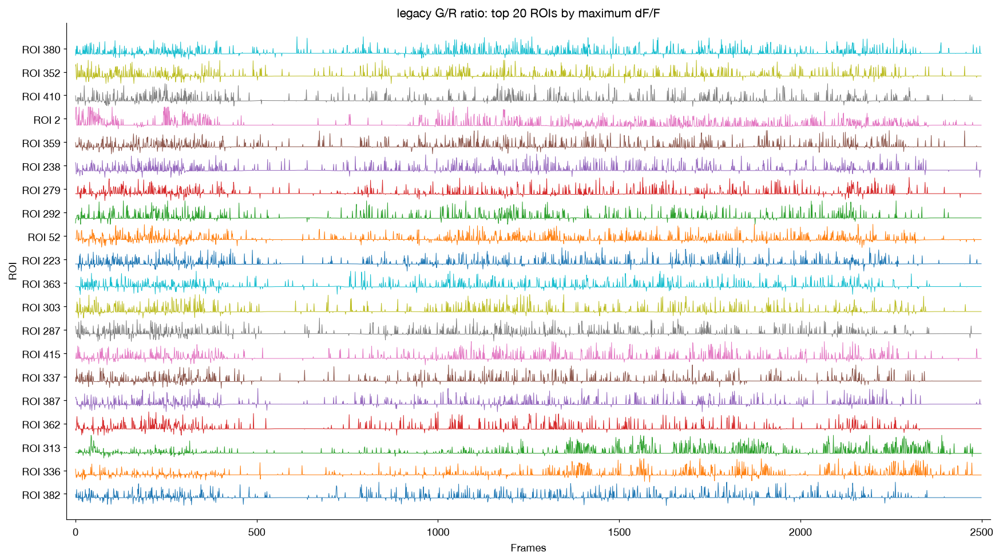


global-red regression
ROI IDs: [2, 317, 319, 318, 316, 320, 336, 31, 227, 363, 296, 357, 337, 315, 313, 55, 40, 352, 52, 255]
Maximum dF/F: [11.021, 10.958, 9.277, 8.78, 8.547, 7.754, 7.566, 6.89, 6.543, 6.476, 6.467, 6.463, 6.423, 6.38, 6.325, 6.299, 6.188, 6.125, 6.018, 6.01]


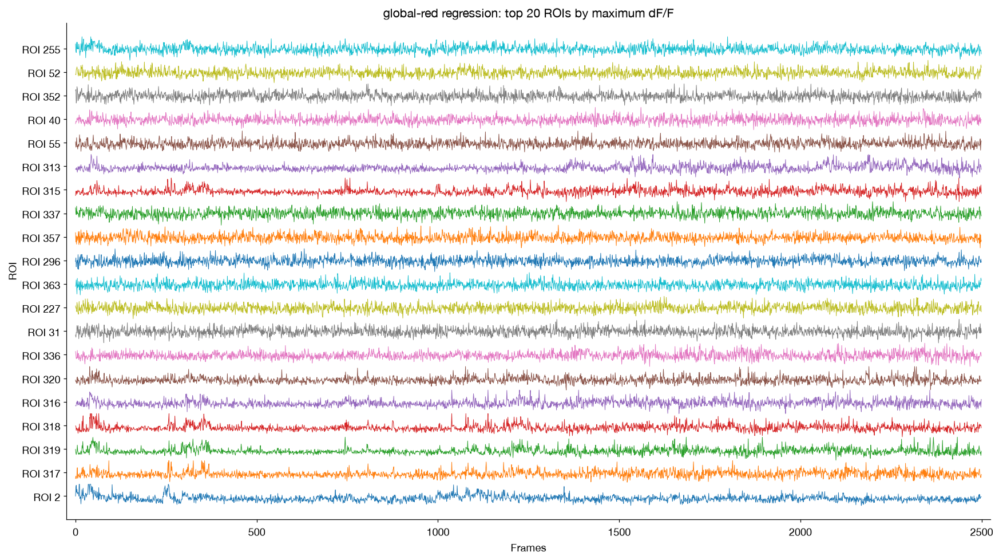


paired-red regression
ROI IDs: [2, 317, 319, 318, 316, 320, 336, 31, 357, 227, 337, 296, 363, 55, 40, 255, 352, 315, 52, 354]
Maximum dF/F: [11.267, 10.746, 9.189, 8.287, 8.205, 7.725, 7.421, 6.955, 6.554, 6.554, 6.515, 6.502, 6.485, 6.295, 6.162, 6.154, 6.027, 6.009, 5.922, 5.849]


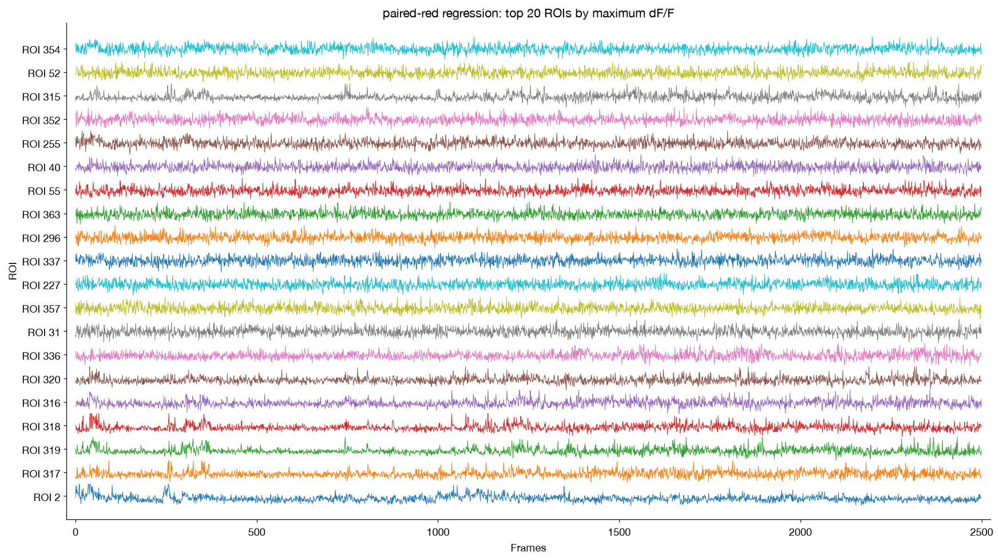


paired-red OLS
ROI IDs: [2, 317, 319, 318, 316, 320, 336, 31, 227, 357, 337, 296, 363, 55, 40, 255, 315, 352, 52, 354]
Maximum dF/F: [11.192, 10.739, 9.196, 8.306, 8.232, 7.678, 7.393, 6.957, 6.554, 6.546, 6.525, 6.498, 6.481, 6.295, 6.161, 6.151, 6.025, 6.015, 5.921, 5.848]


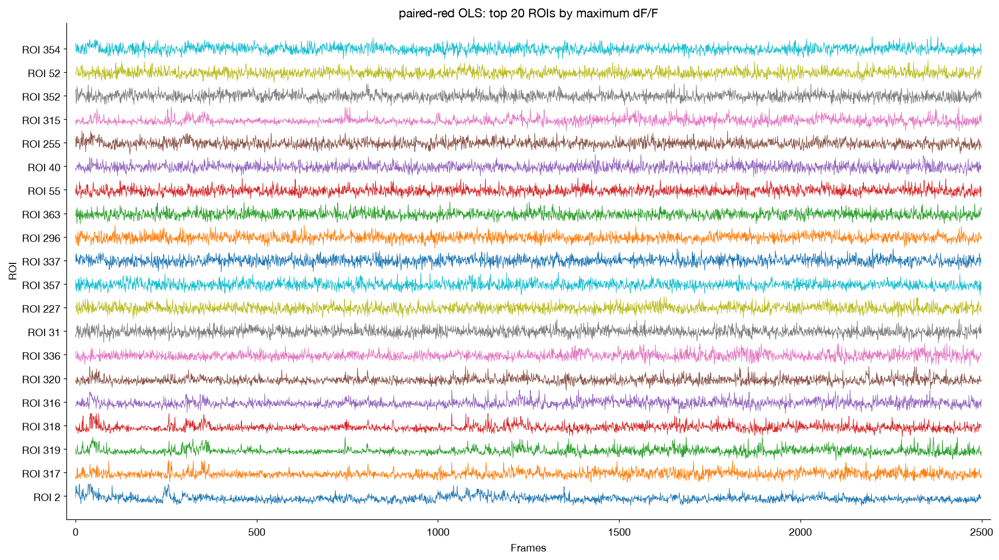


paired-red OLS unscaled
ROI IDs: [2, 317, 319, 318, 316, 320, 336, 31, 227, 357, 337, 296, 363, 55, 40, 255, 315, 352, 52, 354]
Maximum dF/F: [11.192, 10.739, 9.196, 8.306, 8.232, 7.678, 7.393, 6.957, 6.554, 6.546, 6.525, 6.498, 6.481, 6.295, 6.161, 6.151, 6.025, 6.015, 5.921, 5.848]


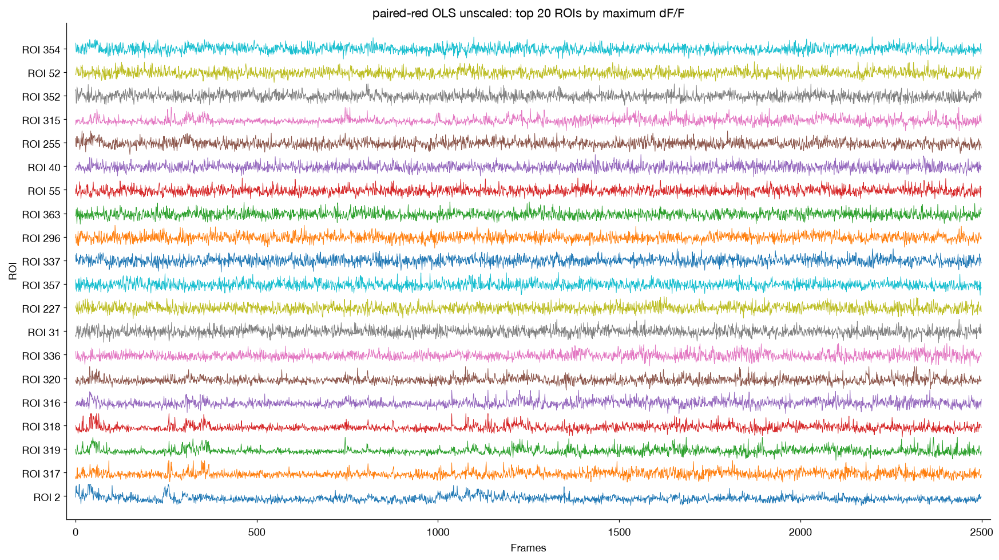


red-transition weighted Ridge
ROI IDs: [317, 2, 319, 318, 316, 320, 336, 31, 313, 315, 227, 357, 337, 363, 296, 55, 40, 52, 222, 352]
Maximum dF/F: [11.086, 10.917, 9.302, 8.879, 8.719, 7.976, 7.647, 6.772, 6.652, 6.561, 6.512, 6.433, 6.42, 6.373, 6.213, 6.187, 6.134, 6.095, 6.033, 5.91]


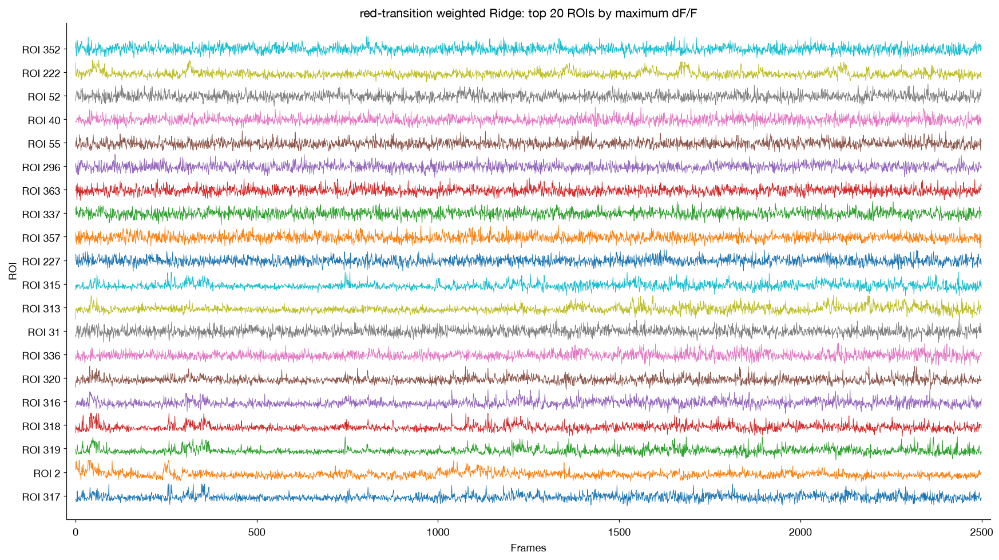

In [29]:
N_MOST_RESPONSIVE_ROIS = 20
most_responsive_by_method = {}

for method_name, method_values in method_dff.items():
    method_values = np.asarray(method_values)
    finite_rois = np.any(np.isfinite(method_values), axis=1)
    if iscell is not None and np.any(iscell):
        candidate_rois = np.flatnonzero(finite_rois & iscell)
    else:
        candidate_rois = np.flatnonzero(finite_rois)
    peak_dff = np.full(method_values.shape[0], -np.inf, dtype=float)
    if candidate_rois.size:
        peak_dff[candidate_rois] = np.nanmax(method_values[candidate_rois], axis=1)
    ranking = candidate_rois[np.argsort(peak_dff[candidate_rois])[::-1]]
    selected_rois = ranking[:N_MOST_RESPONSIVE_ROIS]
    most_responsive_by_method[method_name] = selected_rois

    print(f'\n{method_name}')
    print('ROI IDs:', selected_rois.tolist())
    print('Maximum dF/F:', np.round(peak_dff[selected_rois], 3).tolist())
    plot_stacked_traces(
        method_values, selected_rois,
        start_frame=STACKED_START_FRAME, end_frame=STACKED_END_FRAME,
        low=STACKED_PERCENTILES[0], high=STACKED_PERCENTILES[1],
        title=f'{method_name}: top {len(selected_rois)} ROIs by maximum dF/F',
    )

## Diagnostic ranking of red-channel correction methods

The ranking combines four diagnostics after applying the shared artifact mask: (1) absolute residual correlation between population fluorescence and global red, (2) absolute correlation of their frame-to-frame changes, (3) the median per-ROI 99th percentile of absolute dF/F, and (4) preservation of non-artifact green fluorescence structure relative to standard green. Lower values are better for the first three metrics; higher preservation is better. Each metric contributes equally through its rank. This is a screening tool, not proof that the highest-ranked method preserves biological signals. Always inspect the traces and event-aligned responses.

In [30]:
from scipy.stats import rankdata

red_method_names = [name for name in method_dff if name != 'standard green']
retained_frames = ~artifact_frames
standard_signal = np.asarray(method_signal['standard green'], dtype=float)
ranking_metrics = []

for method_name in red_method_names:
    signal = np.asarray(method_signal[method_name], dtype=float)
    final_dff = method_dff[method_name]
    population_signal = np.nanmedian(signal[artifact_roi_indices], axis=0)
    level_r = finite_corr(
        population_signal[retained_frames], global_red_regression[retained_frames])
    change_keep = retained_frames[1:] & retained_frames[:-1]
    change_r = finite_corr(
        np.diff(population_signal)[change_keep],
        np.diff(global_red_regression)[change_keep])
    per_roi_p99 = np.nanpercentile(
        np.abs(final_dff[artifact_roi_indices]), 99, axis=1)
    median_p99 = float(np.nanmedian(per_roi_p99))

    preservation = []
    for roi in artifact_roi_indices:
        keep = (retained_frames & np.isfinite(signal[roi])
                & np.isfinite(standard_signal[roi]))
        if keep.sum() > 2:
            preservation.append(finite_corr(signal[roi, keep], standard_signal[roi, keep]))
    median_preservation = float(np.nanmedian(preservation)) if preservation else np.nan
    ranking_metrics.append({
        'method': method_name,
        'abs_level_r': float(abs(level_r)),
        'abs_change_r': float(abs(change_r)),
        'median_abs_dff_p99': median_p99,
        'green_preservation_r': median_preservation,
    })

metric_arrays = {
    key: np.array([row[key] for row in ranking_metrics], dtype=float)
    for key in ['abs_level_r', 'abs_change_r', 'median_abs_dff_p99', 'green_preservation_r']
}
component_ranks = np.column_stack([
    rankdata(np.nan_to_num(metric_arrays['abs_level_r'], nan=np.inf)),
    rankdata(np.nan_to_num(metric_arrays['abs_change_r'], nan=np.inf)),
    rankdata(np.nan_to_num(metric_arrays['median_abs_dff_p99'], nan=np.inf)),
    rankdata(np.nan_to_num(-metric_arrays['green_preservation_r'], nan=np.inf)),
])
composite_scores = np.mean(component_ranks, axis=1)
ranking_order = np.argsort(composite_scores)
diagnostic_method_ranking = []

print('Rank  Method                          |level r|  |change r|  median |dF/F| p99  green retention r  score')
print('-' * 112)
for final_rank, index in enumerate(ranking_order, start=1):
    row = ranking_metrics[index]
    output_row = {**row, 'composite_rank_score': float(composite_scores[index]),
                  'rank': int(final_rank)}
    diagnostic_method_ranking.append(output_row)
    print(f"{final_rank:4d}  {row['method']:31s} {row['abs_level_r']:9.3f}  "
          f"{row['abs_change_r']:10.3f}  {row['median_abs_dff_p99']:18.3f}  "
          f"{row['green_preservation_r']:17.3f}  {composite_scores[index]:5.2f}")

print('\nLower composite score ranks better. Near-identical methods should be treated as tied.')

Rank  Method                          |level r|  |change r|  median |dF/F| p99  green retention r  score
----------------------------------------------------------------------------------------------------------------
   1  red-transition weighted Ridge       0.022       0.009               2.171              0.996   2.25
   2  paired-red regression               0.092       0.054               2.183              0.997   2.75
   3  global-red regression               0.000       0.113               2.197              0.999   3.00
   4  paired-red OLS unscaled             0.093       0.054               2.185              0.997   3.12
   5  paired-red OLS                      0.093       0.054               2.185              0.997   3.88
   6  legacy G/R ratio                    0.302       0.260              24.359              0.204   6.00

Lower composite score ranks better. Near-identical methods should be treated as tied.


## Optionally save the comparison arrays

In [31]:
if SAVE_RESULTS:
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    np.save(RESULTS_DIR / 'F_corrected.npy', F)
    np.save(RESULTS_DIR / 'F0.npy', F0)
    np.save(RESULTS_DIR / 'dff_comparison.npy', dff)
    method_slugs = {
        'standard green': 'standard_green',
        'legacy G/R ratio': 'legacy_g_over_r_ratio',
        'global-red regression': 'global_red_huber',
        'paired-red regression': 'paired_red_huber',
        'paired-red OLS': 'paired_red_ols',
        'paired-red OLS unscaled': 'paired_red_ols_unscaled',
        'red-transition weighted Ridge': 'red_transition_weighted_ridge',
        'red + LED regression': 'red_plus_led_huber',
    }
    manifest = {
        'source_plane_dir': str(PLANE_DIR),
        'normalization': '(F-F0)/max(mean(F0),1e-3); SciPy comparison baseline',
        'n_rois': int(next(iter(method_dff.values())).shape[0]),
        'n_frames': int(next(iter(method_dff.values())).shape[1]),
        'valid_frames_path': None if VALID_FRAMES_PATH is None else str(VALID_FRAMES_PATH),
        'suite2p_parameters': {
            key: (ops[key].item() if isinstance(ops[key], np.generic) else ops[key])
            for key in deconv_defaults},
        'artifact_detection': {
            'mask_source': ARTIFACT_MASK_SOURCE,
            'detected_before_regression': True,
            'excluded_from_regression_fits': True,
            'derivative_z_threshold': ARTIFACT_DERIVATIVE_Z,
            'minimum_fraction_cells': ARTIFACT_MIN_FRACTION_CELLS,
            'padding_frames': ARTIFACT_PADDING_FRAMES,
            'replacement': ARTIFACT_REPLACEMENT,
            'final_outputs_already_artifact_handled': True,
            'mask_file': 'artifact_frames.npy',
        },
        'diagnostic_method_ranking': diagnostic_method_ranking,
        'methods': {},
    }
    np.save(RESULTS_DIR / 'artifact_frames.npy', artifact_frames)
    np.save(RESULTS_DIR / 'artifact_fraction_cells.npy', artifact_fraction_cells)
    for name, values in method_signal.items():
        slug = method_slugs[name]
        signal_file = f'signal_{slug}.npy'
        dff_file = f'dff_{slug}.npy'
        np.save(RESULTS_DIR / signal_file, np.asarray(values, dtype=np.float32))
        np.save(RESULTS_DIR / dff_file, np.asarray(method_dff[name], dtype=np.float32))
        manifest['methods'][slug] = {
            'display_name': name, 'signal_file': signal_file,
            'dff_file': dff_file,
            'artifact_removed_dff_file': dff_file}
    with (RESULTS_DIR / 'dff_methods.json').open('w') as handle:
        json.dump(manifest, handle, indent=2)
    print('Saved methods:', sorted(manifest['methods']))
    print('Manifest:', RESULTS_DIR / 'dff_methods.json')

## All sessions/runs: F, F0 and dF/F overview

Runs independently using each run's ops and all frames. The single-run valid-frame selector is not applied here. Both available channels are shown. Missing inputs/errors are reported per run; summary rows are retained in `batch_summary`. Full trace arrays are released after each run. `SAVE_BATCH_FIGURES` writes figures and a JSON summary locally. No red regression is performed in this overview; use the detailed sections above for a selected run.

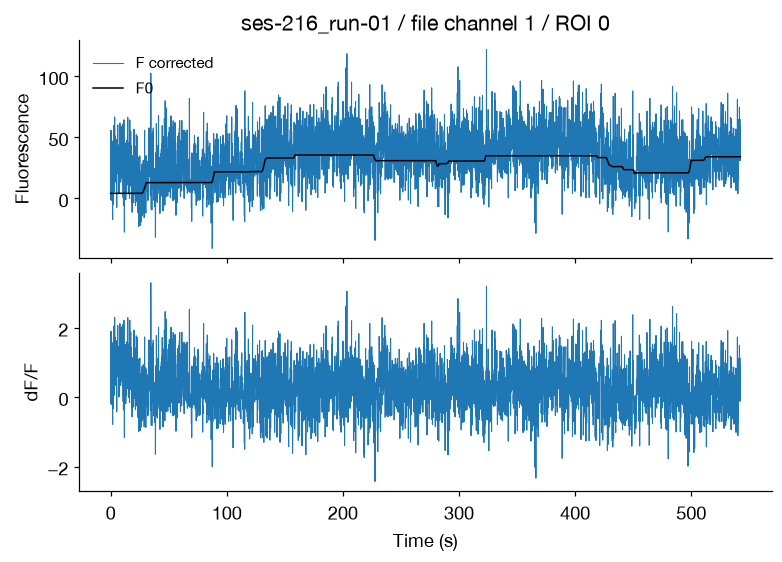

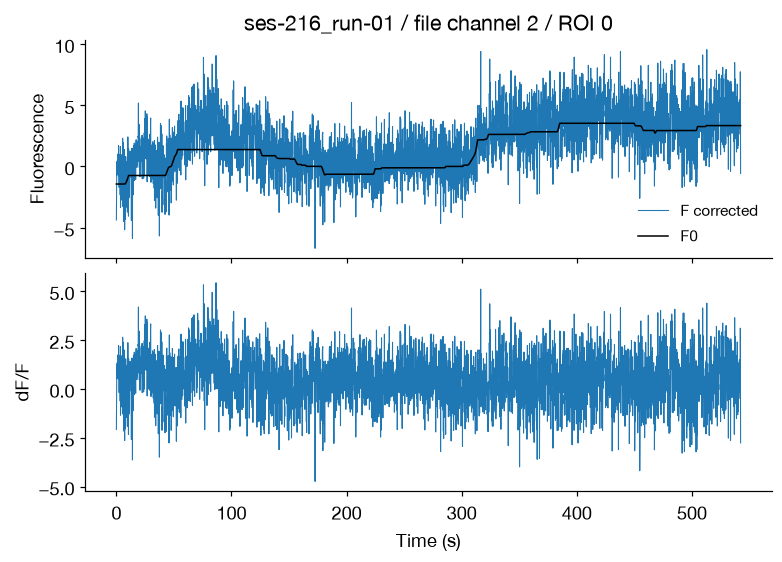

216 / run-01: [{'recording': 'ses-216_run-01', 'channel': 1, 'roi': 0, 'frames': 4079, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 27.181983947753906, 'abs_dff_p99': 2.0713775157928467, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-216_run-01', 'channel': 2, 'roi': 0, 'frames': 4079, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 1.4139760732650757, 'abs_dff_p99': 3.5651772022247314, 'status': 'ok', 'defaulted_settings': []}]


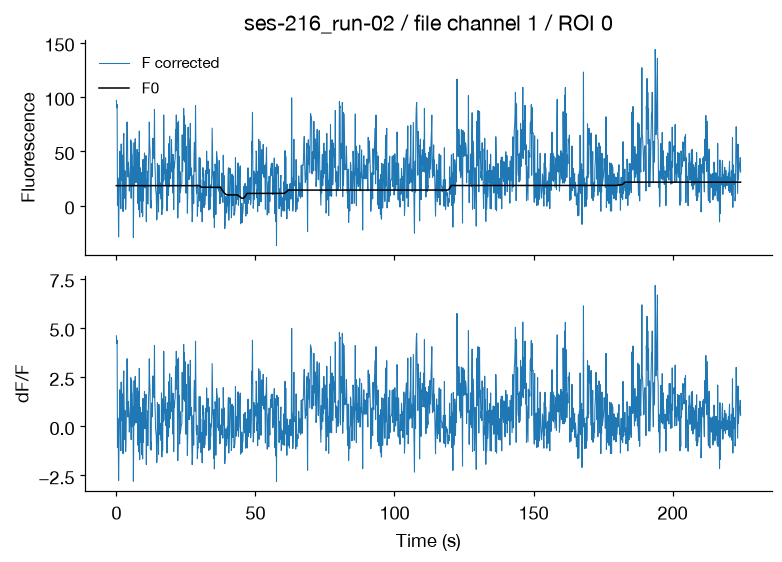

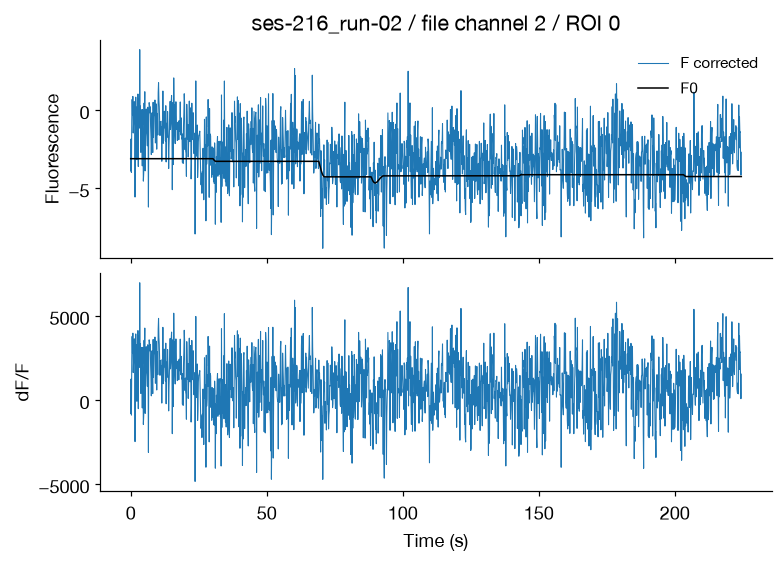

216 / run-02: [{'recording': 'ses-216_run-02', 'channel': 1, 'roi': 0, 'frames': 1689, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 17.08116340637207, 'abs_dff_p99': 4.727643013000488, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-216_run-02', 'channel': 2, 'roi': 0, 'frames': 1689, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': -3.8739144802093506, 'abs_dff_p99': 4839.61865234375, 'status': 'CHECK F0', 'defaulted_settings': []}]


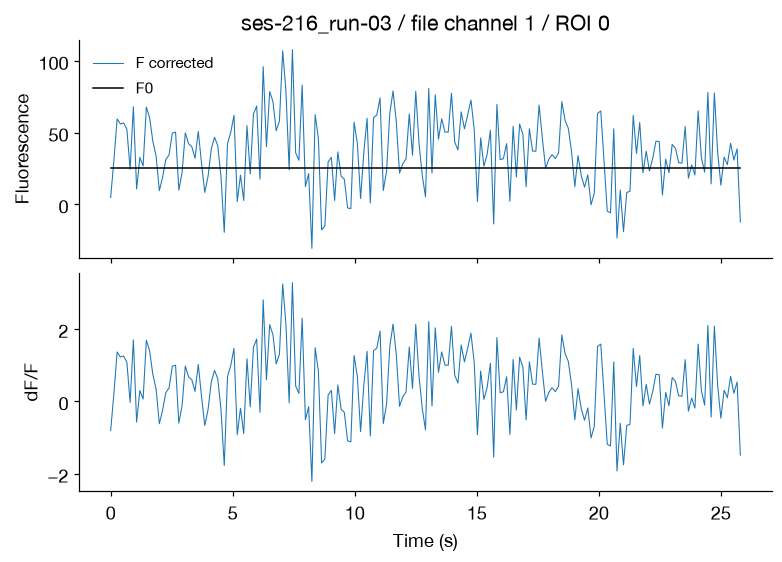

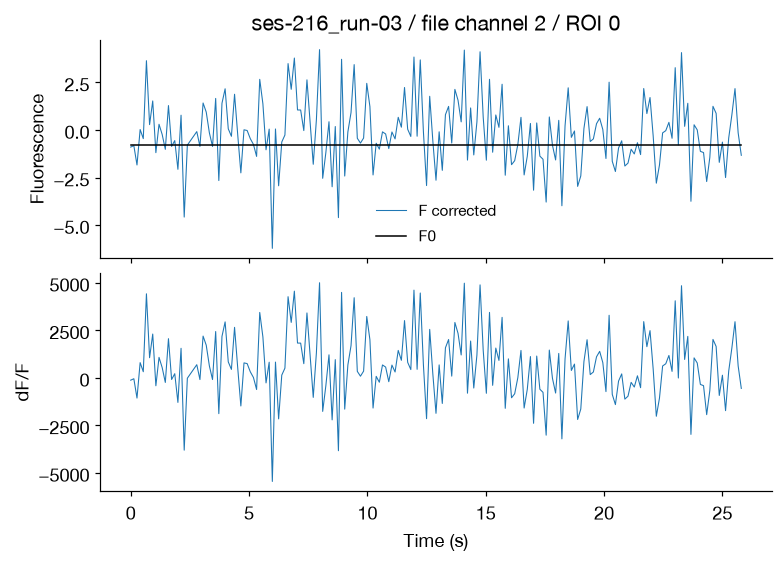

216 / run-03: [{'recording': 'ses-216_run-03', 'channel': 1, 'roi': 0, 'frames': 195, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 25.23239517211914, 'abs_dff_p99': 2.8327243328094482, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-216_run-03', 'channel': 2, 'roi': 0, 'frames': 195, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': -0.7750363945960999, 'abs_dff_p99': 4977.68798828125, 'status': 'CHECK F0', 'defaulted_settings': []}]


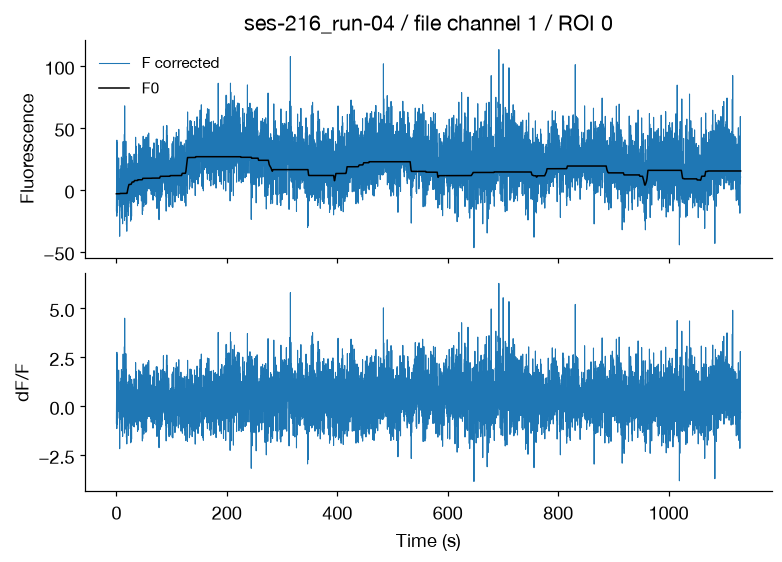

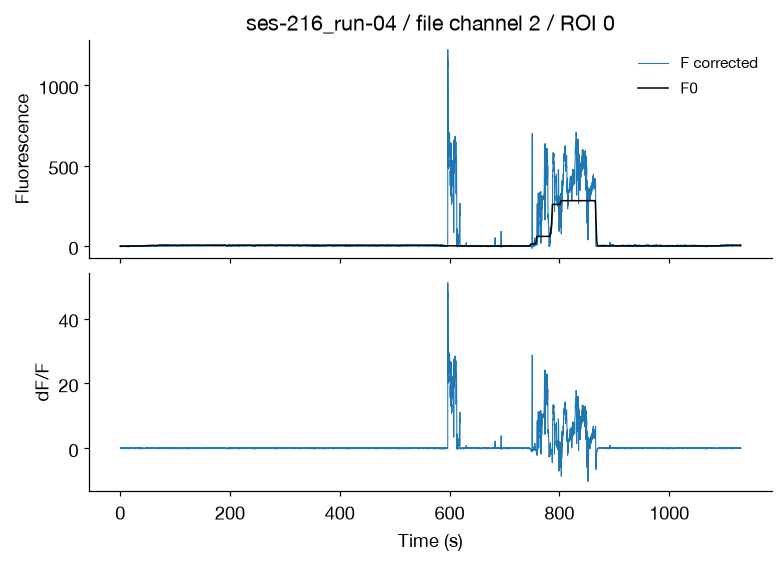

216 / run-04: [{'recording': 'ses-216_run-04', 'channel': 1, 'roi': 0, 'frames': 8503, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 15.762712478637695, 'abs_dff_p99': 3.067392349243164, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-216_run-04', 'channel': 2, 'roi': 0, 'frames': 8503, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 23.914709091186523, 'abs_dff_p99': 20.13425636291504, 'status': 'ok', 'defaulted_settings': []}]


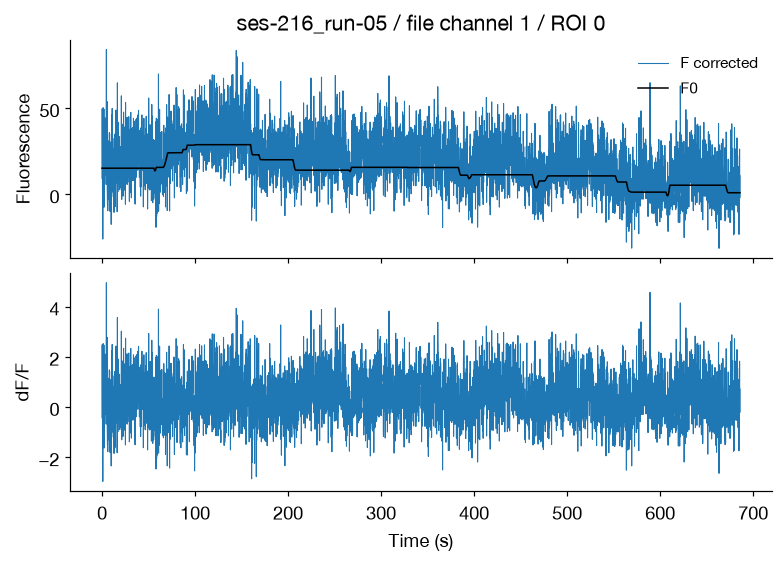

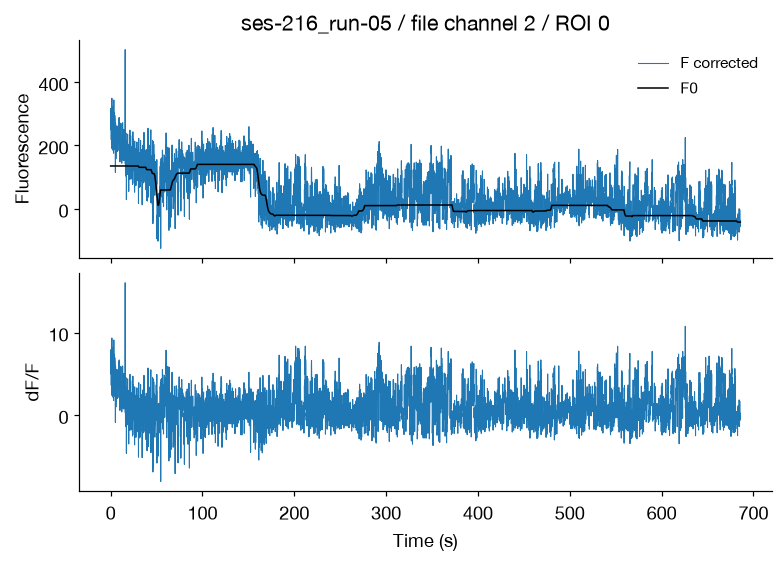

216 / run-05: [{'recording': 'ses-216_run-05', 'channel': 1, 'roi': 0, 'frames': 5158, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 13.91027545928955, 'abs_dff_p99': 2.8002703189849854, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-216_run-05', 'channel': 2, 'roi': 0, 'frames': 5158, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 22.91522216796875, 'abs_dff_p99': 6.944544792175293, 'status': 'ok', 'defaulted_settings': []}]


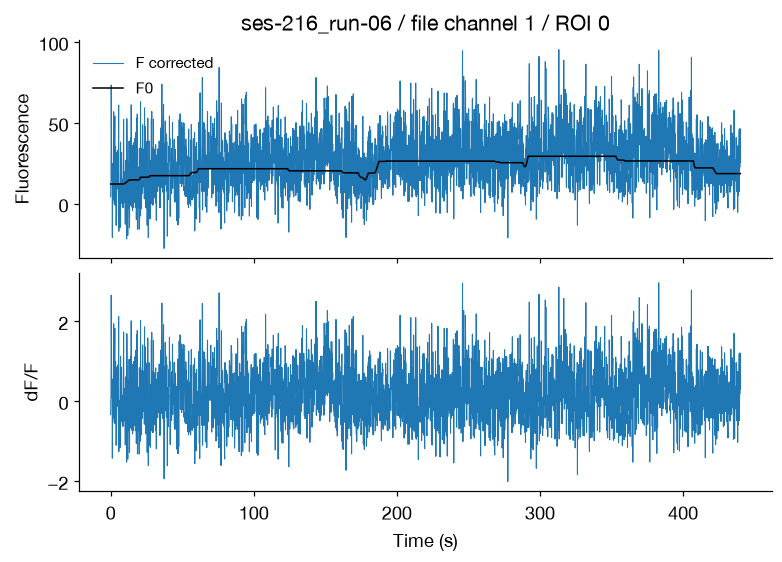

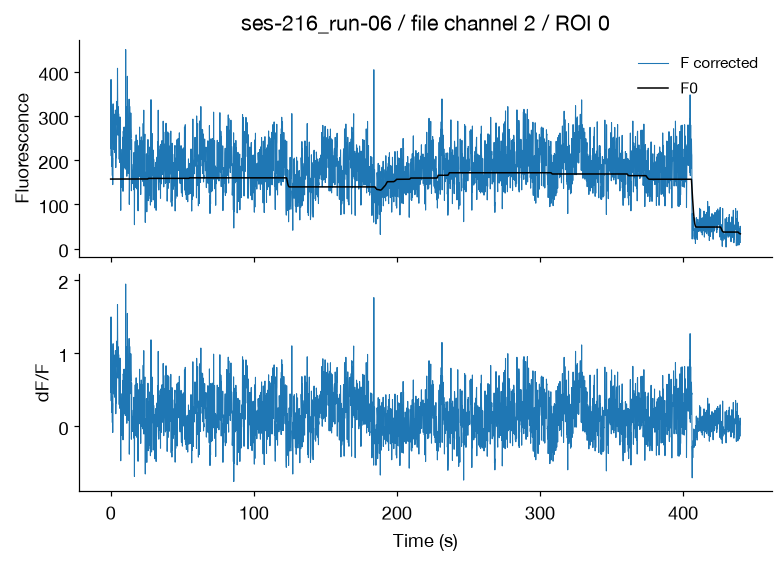

216 / run-06: [{'recording': 'ses-216_run-06', 'channel': 1, 'roi': 0, 'frames': 3310, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 23.136581420898438, 'abs_dff_p99': 2.017972230911255, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-216_run-06', 'channel': 2, 'roi': 0, 'frames': 3310, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 150.61572265625, 'abs_dff_p99': 0.9537644982337952, 'status': 'ok', 'defaulted_settings': []}]


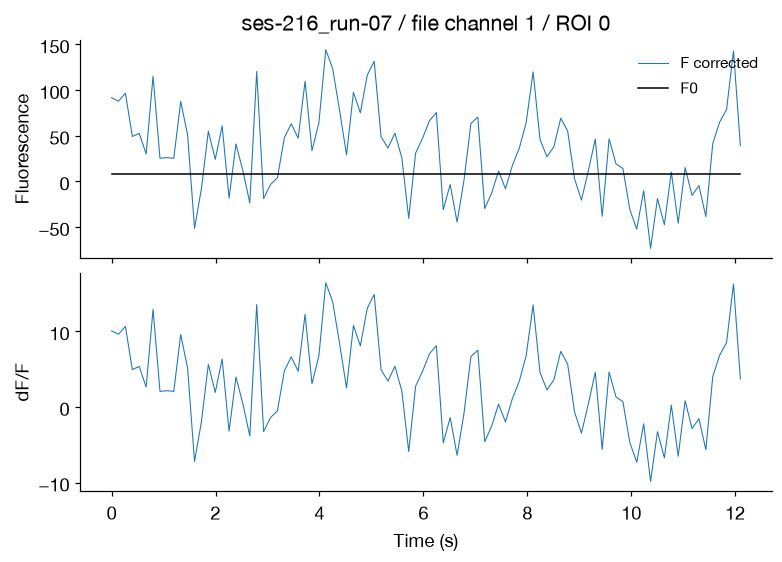

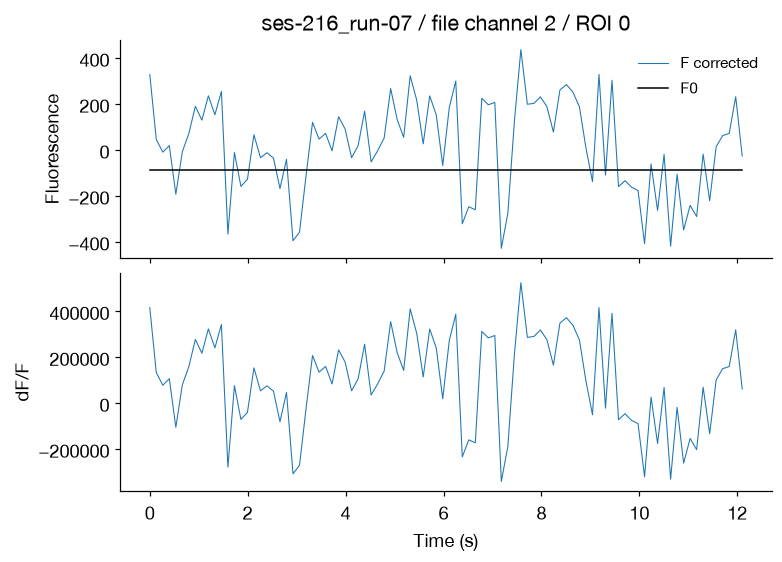

216 / run-07: [{'recording': 'ses-216_run-07', 'channel': 1, 'roi': 0, 'frames': 92, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 8.276816368103027, 'abs_dff_p99': 16.284957885742188, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-216_run-07', 'channel': 2, 'roi': 0, 'frames': 92, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': -87.48625946044922, 'abs_dff_p99': 425037.5625, 'status': 'CHECK F0', 'defaulted_settings': []}]


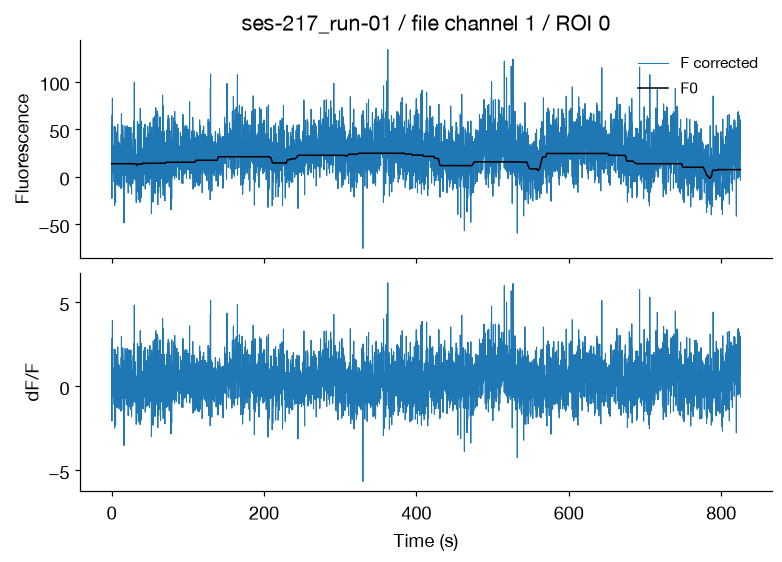

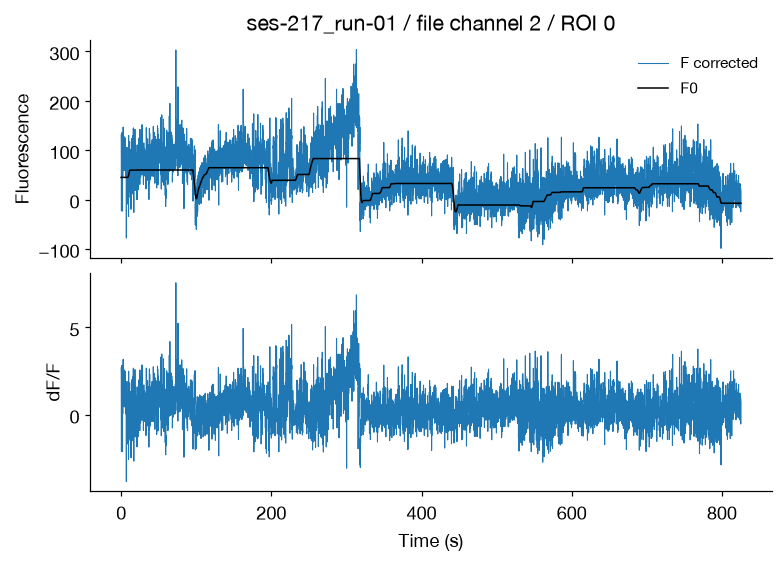

217 / run-01: [{'recording': 'ses-217_run-01', 'channel': 1, 'roi': 0, 'frames': 6207, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 17.69959259033203, 'abs_dff_p99': 3.328402280807495, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-217_run-01', 'channel': 2, 'roi': 0, 'frames': 6207, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 32.12215805053711, 'abs_dff_p99': 3.60922908782959, 'status': 'ok', 'defaulted_settings': []}]


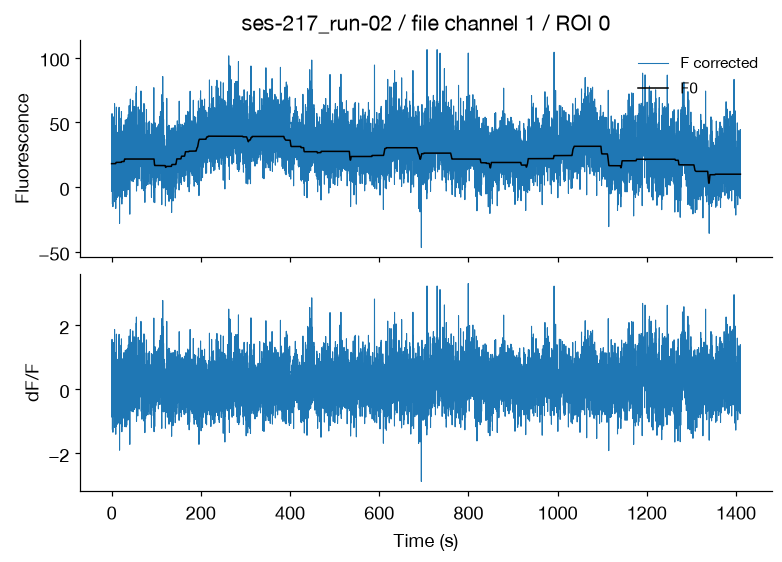

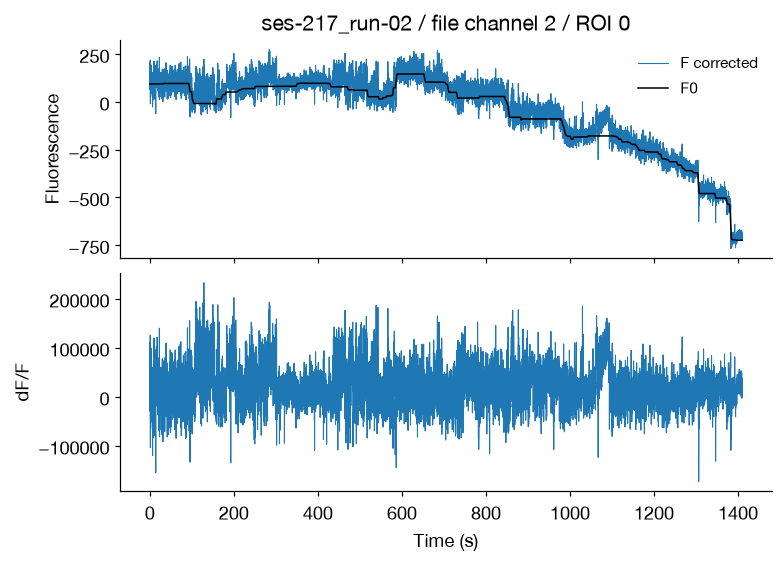

217 / run-02: [{'recording': 'ses-217_run-02', 'channel': 1, 'roi': 0, 'frames': 10604, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 24.74477767944336, 'abs_dff_p99': 1.8031761646270752, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-217_run-02', 'channel': 2, 'roi': 0, 'frames': 10604, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': -64.01256561279297, 'abs_dff_p99': 139591.109375, 'status': 'CHECK F0', 'defaulted_settings': []}]


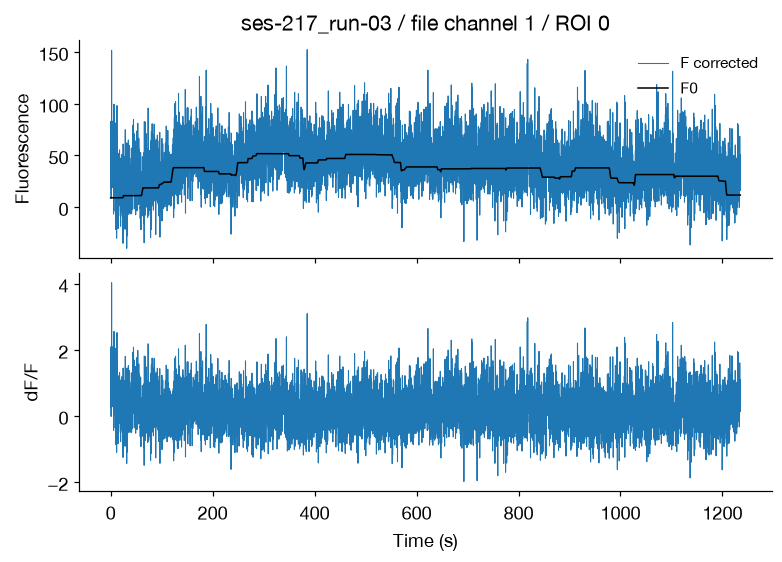

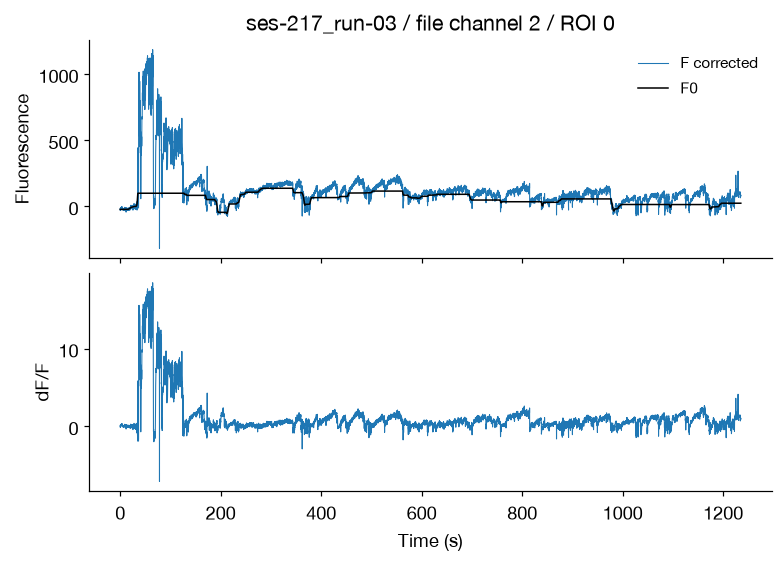

217 / run-03: [{'recording': 'ses-217_run-03', 'channel': 1, 'roi': 0, 'frames': 9289, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 35.43241882324219, 'abs_dff_p99': 1.7869648933410645, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-217_run-03', 'channel': 2, 'roi': 0, 'frames': 9289, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 58.76482391357422, 'abs_dff_p99': 14.286474227905273, 'status': 'ok', 'defaulted_settings': []}]


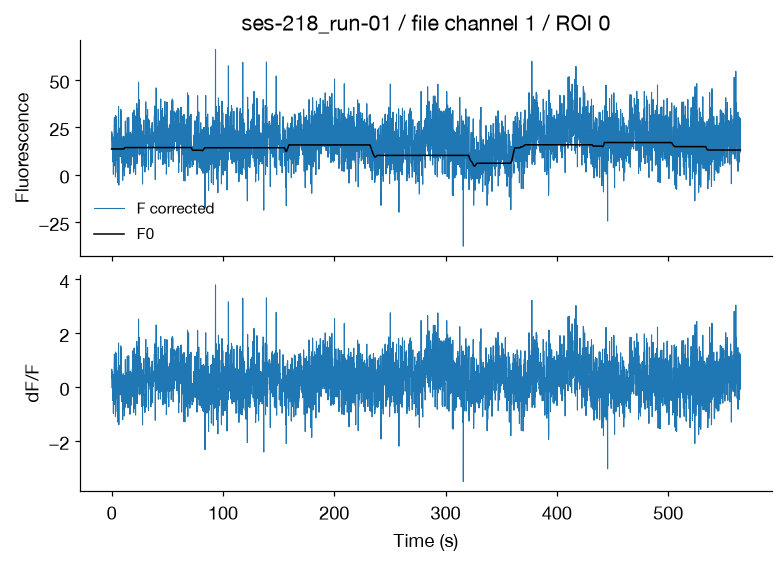

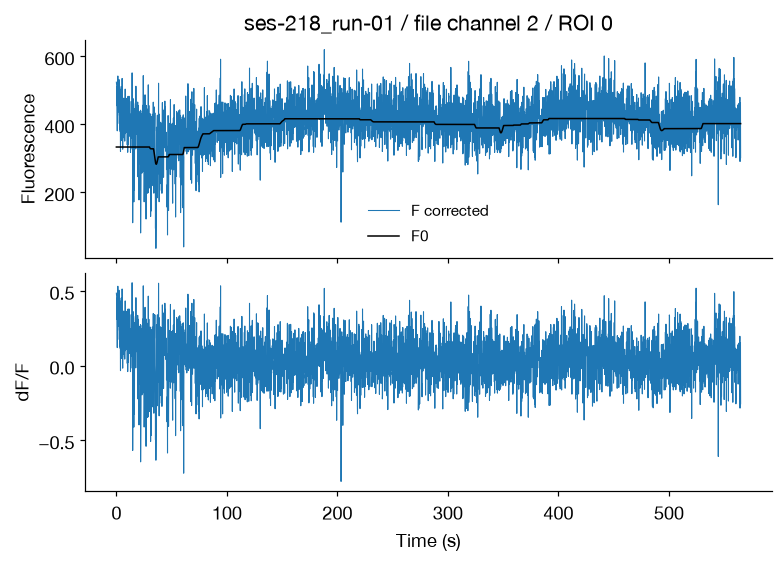

218 / run-01: [{'recording': 'ses-218_run-01', 'channel': 1, 'roi': 0, 'frames': 4249, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 13.657517433166504, 'abs_dff_p99': 2.121342182159424, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-218_run-01', 'channel': 2, 'roi': 0, 'frames': 4249, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 393.201904296875, 'abs_dff_p99': 0.4381139874458313, 'status': 'ok', 'defaulted_settings': []}]


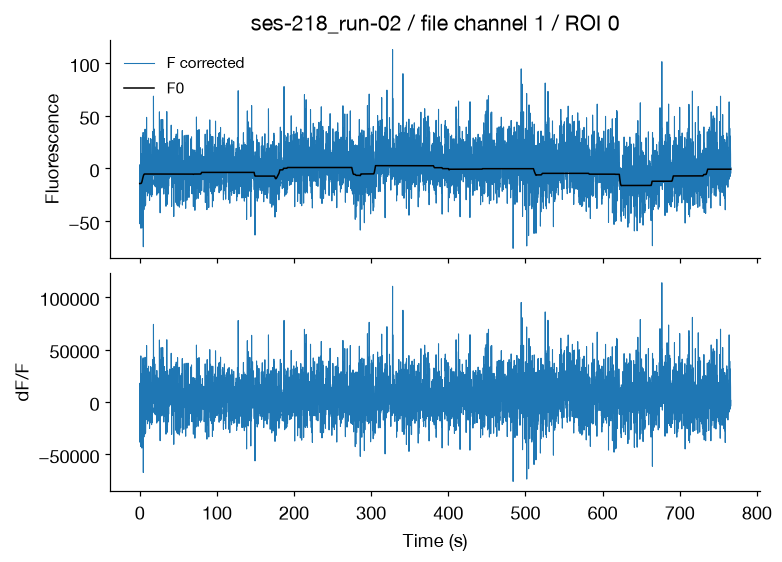

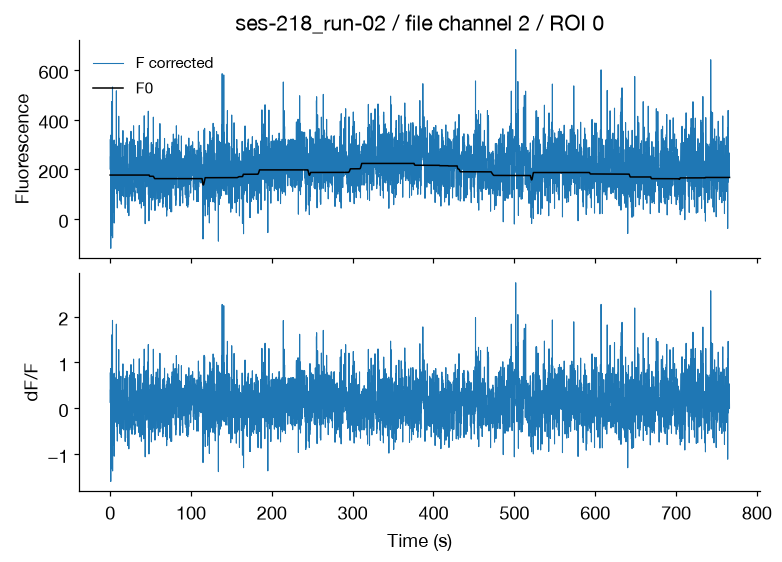

218 / run-02: [{'recording': 'ses-218_run-02', 'channel': 1, 'roi': 0, 'frames': 5763, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': -3.591336965560913, 'abs_dff_p99': 56531.20703125, 'status': 'CHECK F0', 'defaulted_settings': []}, {'recording': 'ses-218_run-02', 'channel': 2, 'roi': 0, 'frames': 5763, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 184.87454223632812, 'abs_dff_p99': 1.3416430950164795, 'status': 'ok', 'defaulted_settings': []}]


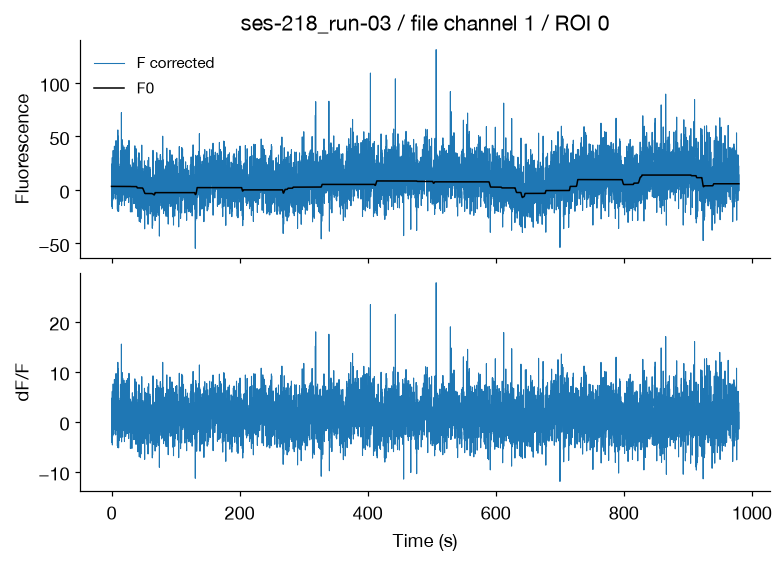

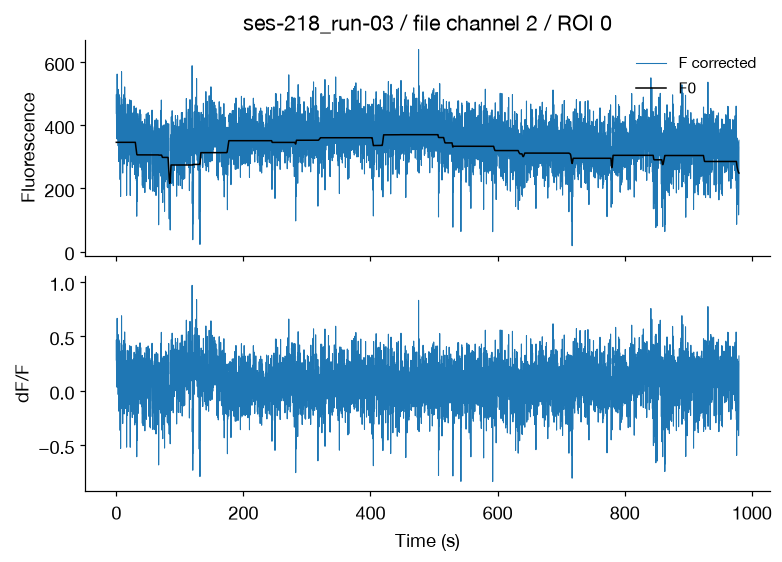

218 / run-03: [{'recording': 'ses-218_run-03', 'channel': 1, 'roi': 0, 'frames': 7369, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 4.448324680328369, 'abs_dff_p99': 10.383355140686035, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-218_run-03', 'channel': 2, 'roi': 0, 'frames': 7369, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 324.44830322265625, 'abs_dff_p99': 0.5461092591285706, 'status': 'ok', 'defaulted_settings': []}]


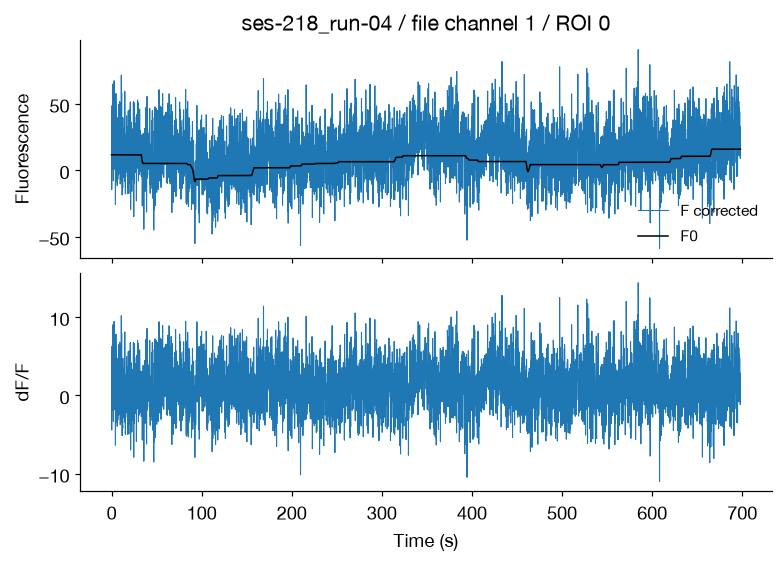

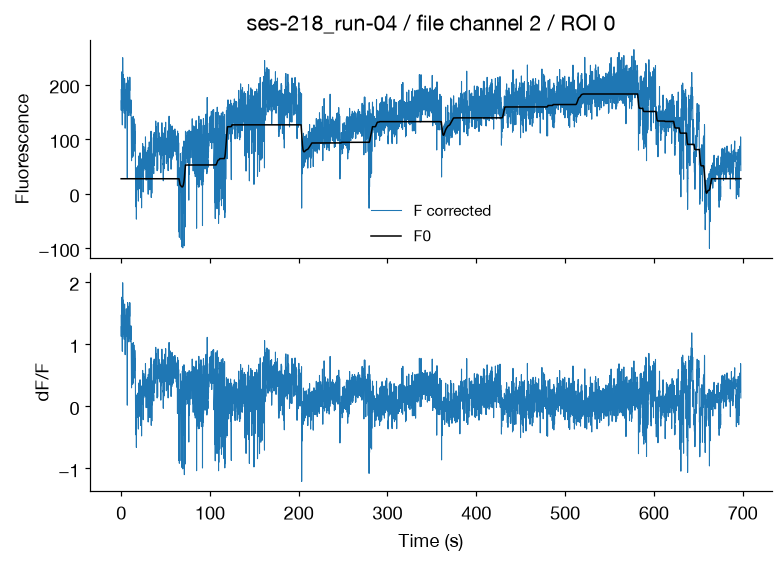

218 / run-04: [{'recording': 'ses-218_run-04', 'channel': 1, 'roi': 0, 'frames': 5250, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 5.893235683441162, 'abs_dff_p99': 9.00930118560791, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-218_run-04', 'channel': 2, 'roi': 0, 'frames': 5250, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 111.79900360107422, 'abs_dff_p99': 1.2331041097640991, 'status': 'ok', 'defaulted_settings': []}]


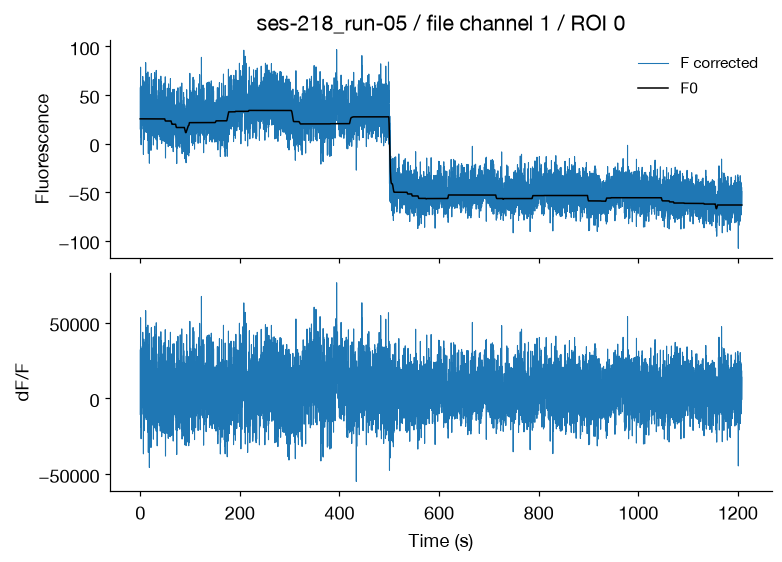

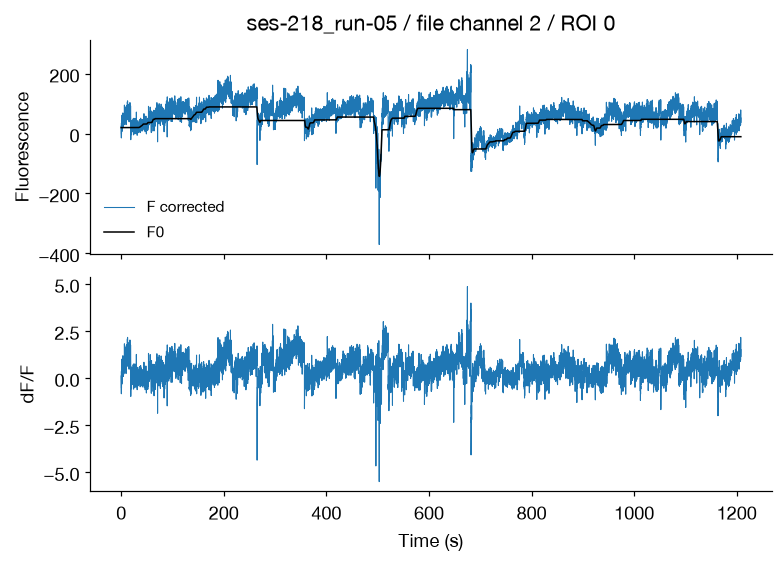

218 / run-05: [{'recording': 'ses-218_run-05', 'channel': 1, 'roi': 0, 'frames': 9085, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': -22.392576217651367, 'abs_dff_p99': 41560.6953125, 'status': 'CHECK F0', 'defaulted_settings': []}, {'recording': 'ses-218_run-05', 'channel': 2, 'roi': 0, 'frames': 9085, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 41.34144973754883, 'abs_dff_p99': 2.0857954025268555, 'status': 'ok', 'defaulted_settings': []}]


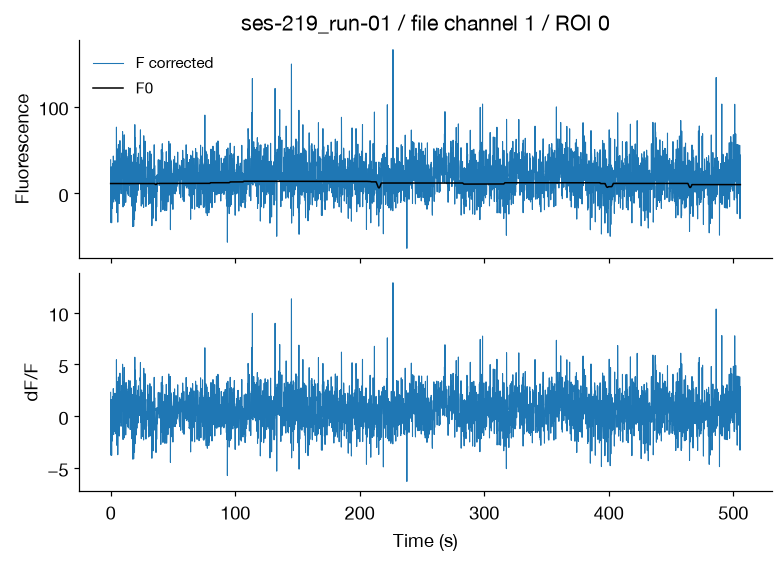

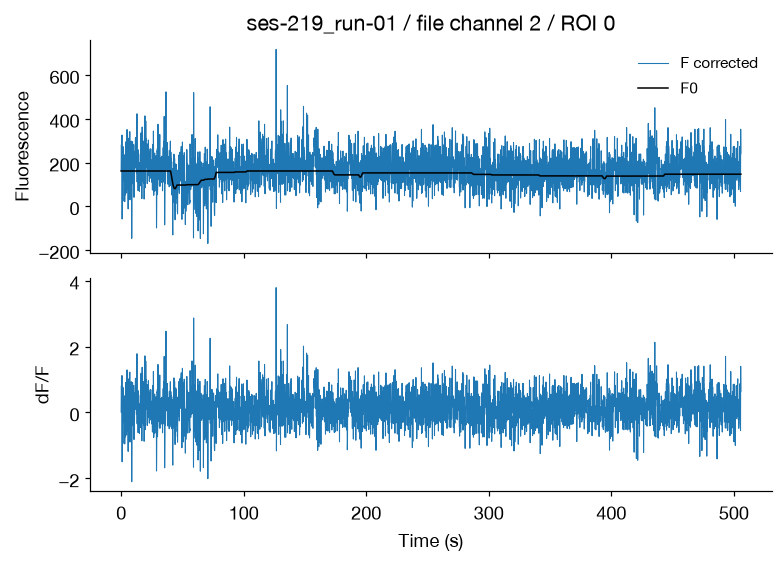

219 / run-01: [{'recording': 'ses-219_run-01', 'channel': 1, 'roi': 0, 'frames': 3804, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 11.921405792236328, 'abs_dff_p99': 5.469196319580078, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-219_run-01', 'channel': 2, 'roi': 0, 'frames': 3804, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 146.7074737548828, 'abs_dff_p99': 1.4472161531448364, 'status': 'ok', 'defaulted_settings': []}]


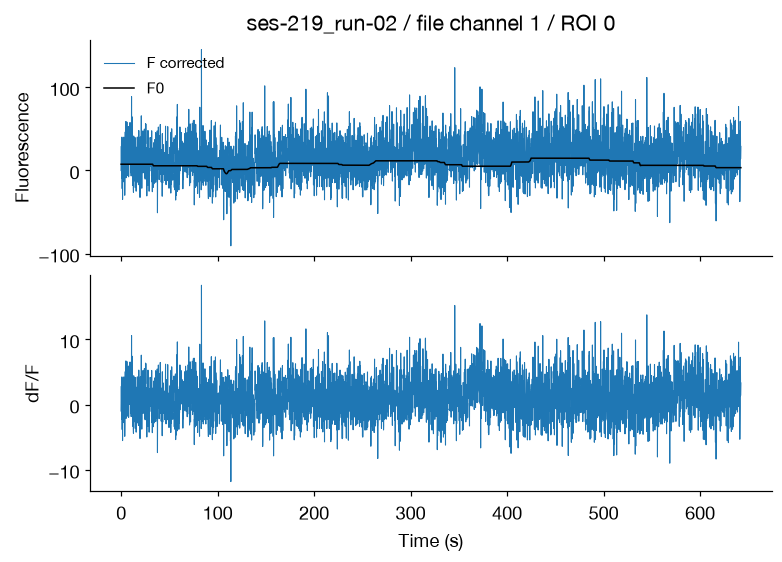

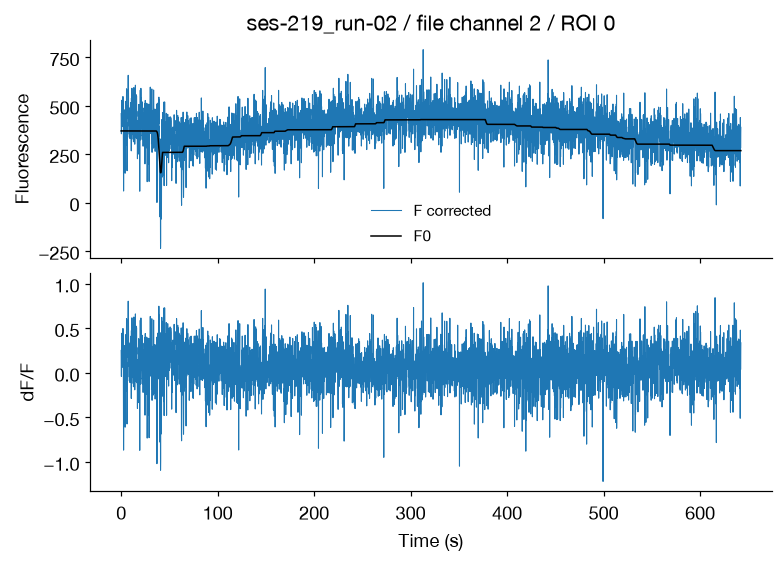

219 / run-02: [{'recording': 'ses-219_run-02', 'channel': 1, 'roi': 0, 'frames': 4831, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 7.661590576171875, 'abs_dff_p99': 8.812854766845703, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-219_run-02', 'channel': 2, 'roi': 0, 'frames': 4831, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 357.94244384765625, 'abs_dff_p99': 0.6686196327209473, 'status': 'ok', 'defaulted_settings': []}]


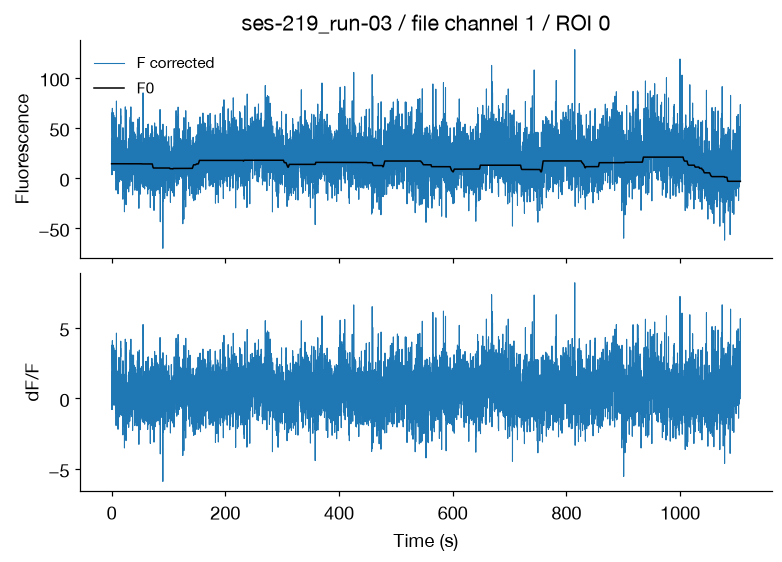

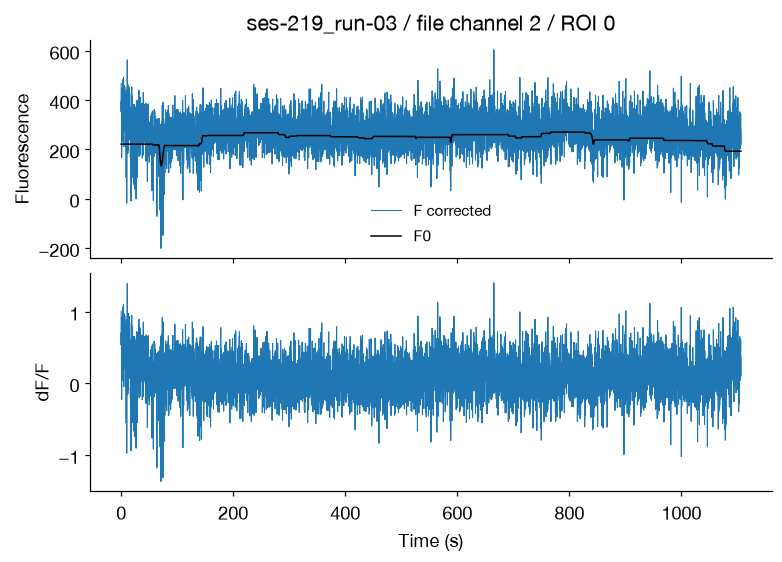

219 / run-03: [{'recording': 'ses-219_run-03', 'channel': 1, 'roi': 0, 'frames': 8319, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 13.55776309967041, 'abs_dff_p99': 4.372227668762207, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-219_run-03', 'channel': 2, 'roi': 0, 'frames': 8319, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 245.609130859375, 'abs_dff_p99': 0.7993685007095337, 'status': 'ok', 'defaulted_settings': []}]


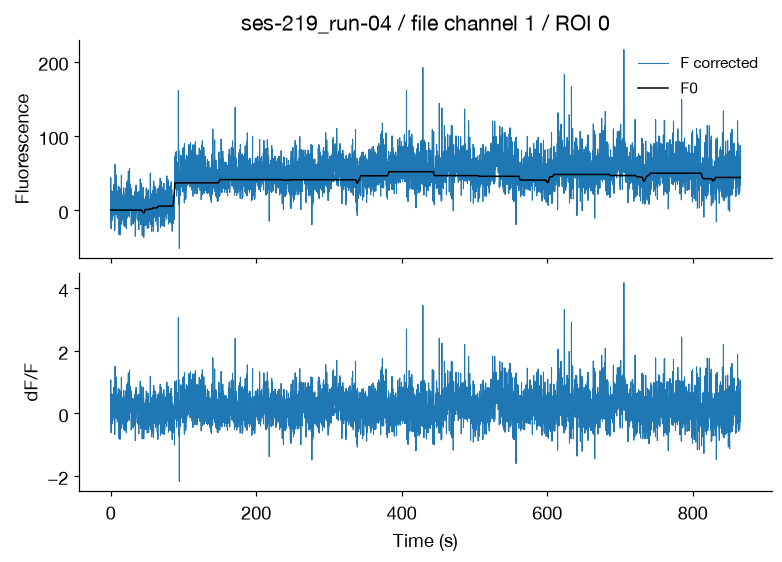

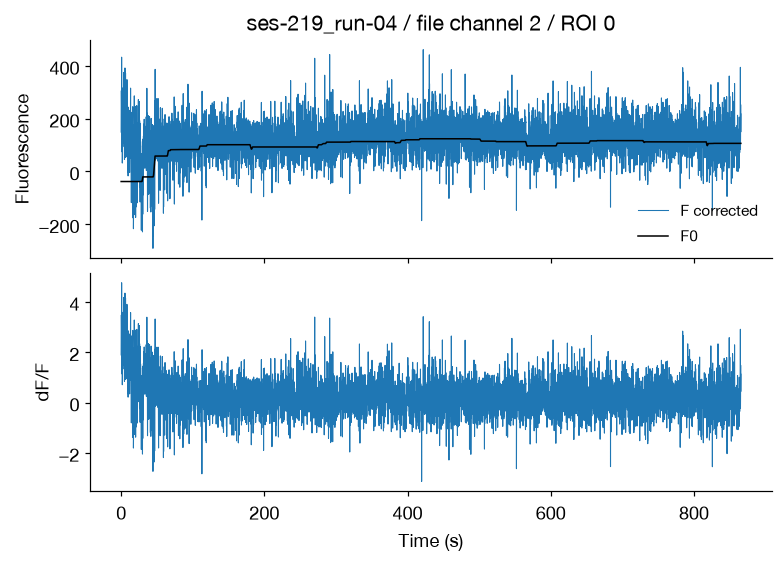

219 / run-04: [{'recording': 'ses-219_run-04', 'channel': 1, 'roi': 0, 'frames': 6510, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 40.57522964477539, 'abs_dff_p99': 1.4571105241775513, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-219_run-04', 'channel': 2, 'roi': 0, 'frames': 6510, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 99.02745819091797, 'abs_dff_p99': 2.5467021465301514, 'status': 'ok', 'defaulted_settings': []}]


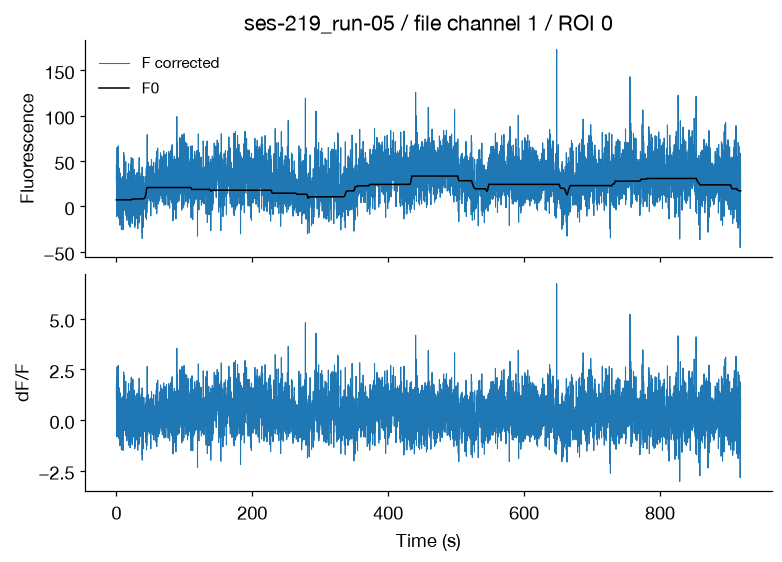

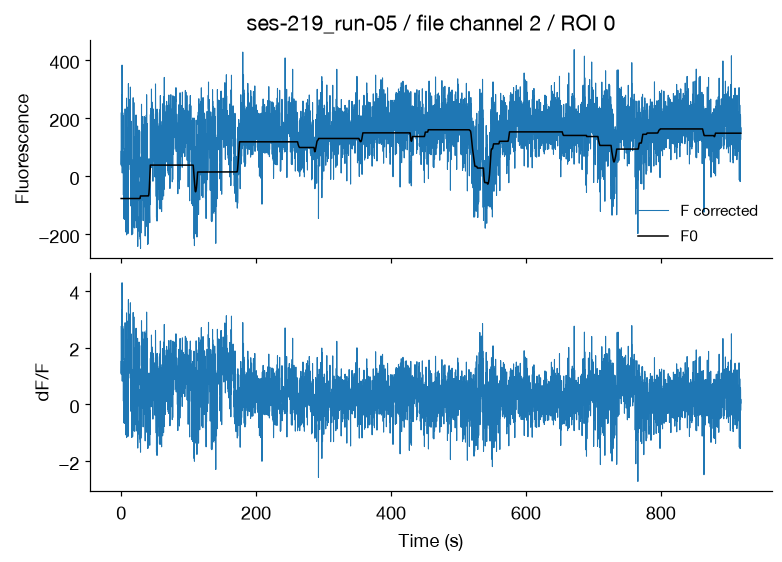

219 / run-05: [{'recording': 'ses-219_run-05', 'channel': 1, 'roi': 0, 'frames': 6910, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 22.048988342285156, 'abs_dff_p99': 2.590827465057373, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-219_run-05', 'channel': 2, 'roi': 0, 'frames': 6910, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 107.27092742919922, 'abs_dff_p99': 2.395782947540283, 'status': 'ok', 'defaulted_settings': []}]


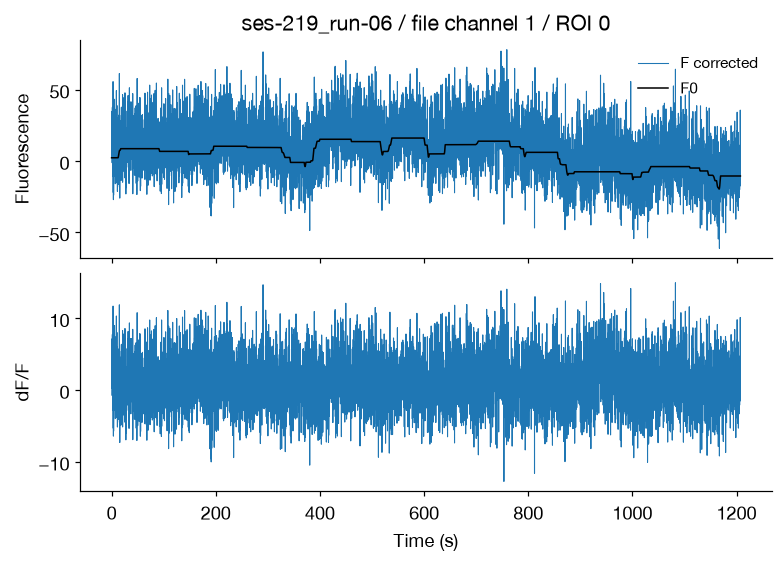

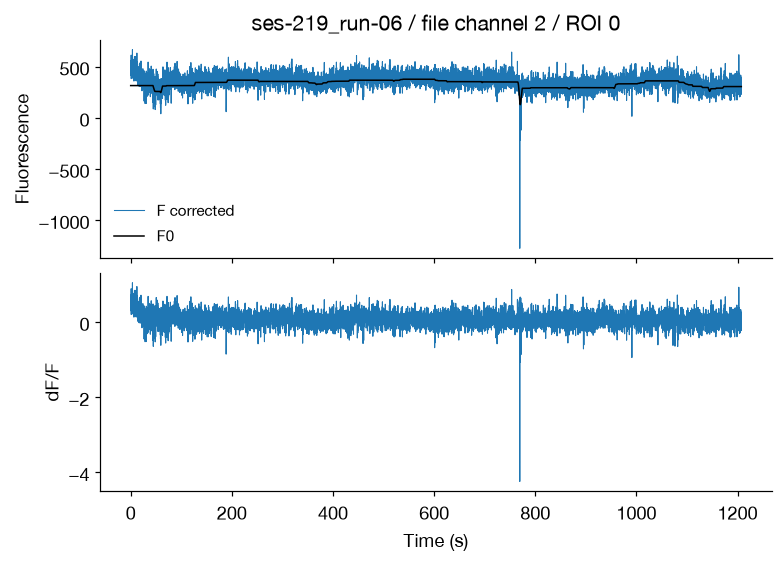

219 / run-06: [{'recording': 'ses-219_run-06', 'channel': 1, 'roi': 0, 'frames': 9081, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 4.5597639083862305, 'abs_dff_p99': 9.927735328674316, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-219_run-06', 'channel': 2, 'roi': 0, 'frames': 9081, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 335.2296447753906, 'abs_dff_p99': 0.5753324627876282, 'status': 'ok', 'defaulted_settings': []}]


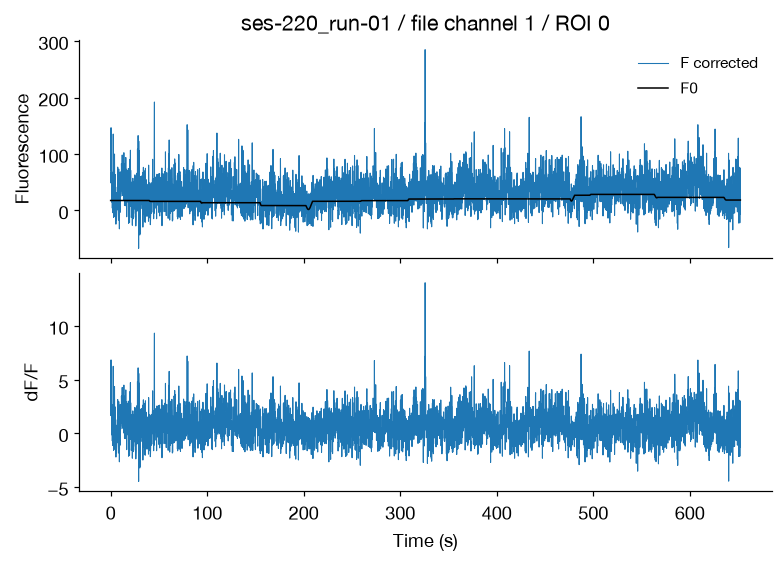

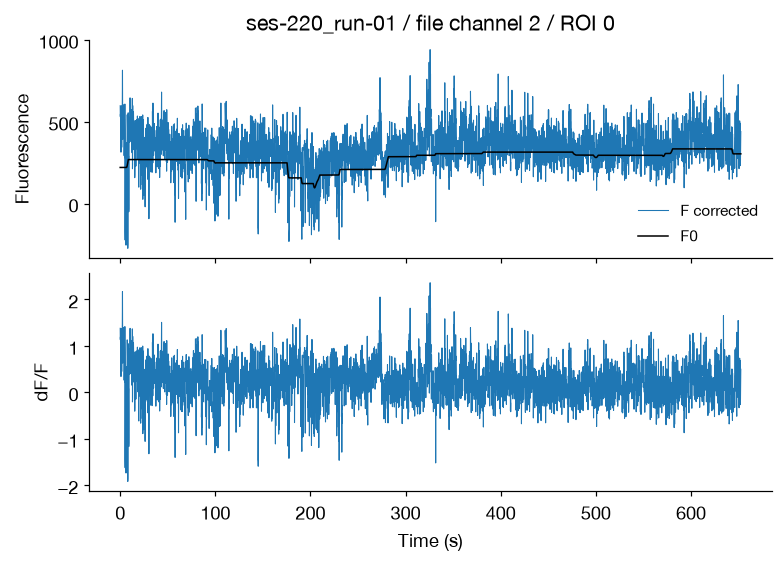

220 / run-01: [{'recording': 'ses-220_run-01', 'channel': 1, 'roi': 0, 'frames': 4907, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 18.881805419921875, 'abs_dff_p99': 4.515326499938965, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-220_run-01', 'channel': 2, 'roi': 0, 'frames': 4907, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 273.3491516113281, 'abs_dff_p99': 1.347612738609314, 'status': 'ok', 'defaulted_settings': []}]


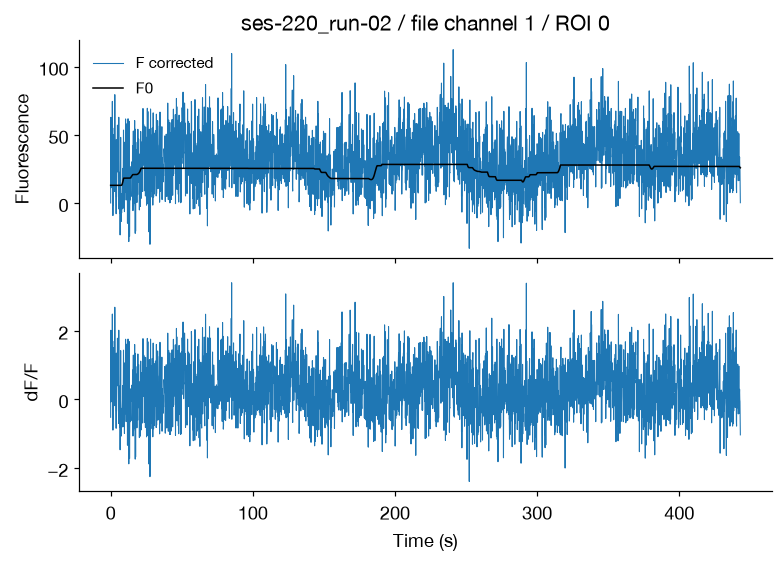

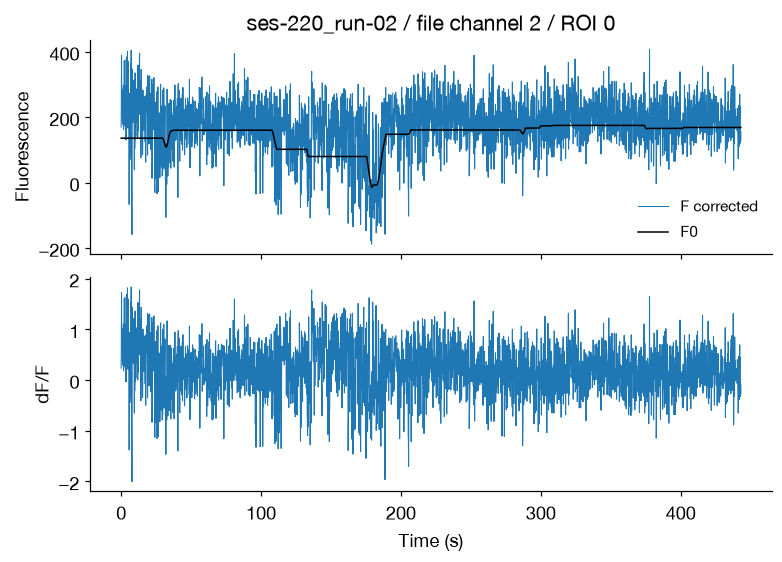

220 / run-02: [{'recording': 'ses-220_run-02', 'channel': 1, 'roi': 0, 'frames': 3332, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 24.769405364990234, 'abs_dff_p99': 2.311318874359131, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-220_run-02', 'channel': 2, 'roi': 0, 'frames': 3332, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 146.7228240966797, 'abs_dff_p99': 1.4338488578796387, 'status': 'ok', 'defaulted_settings': []}]


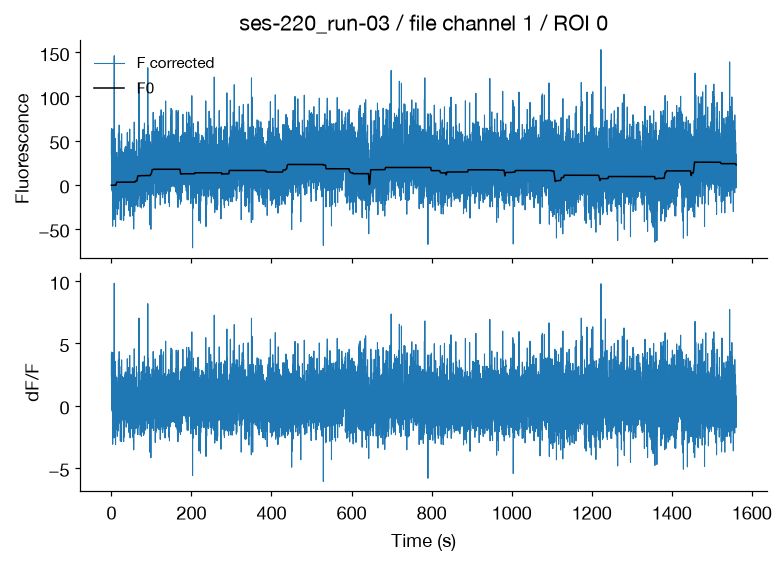

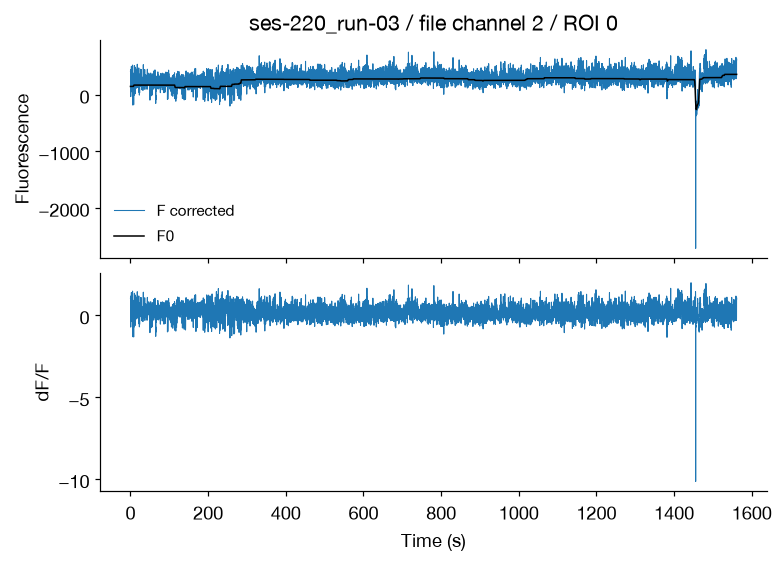

220 / run-03: [{'recording': 'ses-220_run-03', 'channel': 1, 'roi': 0, 'frames': 11739, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 14.958245277404785, 'abs_dff_p99': 4.695035934448242, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-220_run-03', 'channel': 2, 'roi': 0, 'frames': 11739, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 254.04788208007812, 'abs_dff_p99': 1.1549255847930908, 'status': 'ok', 'defaulted_settings': []}]


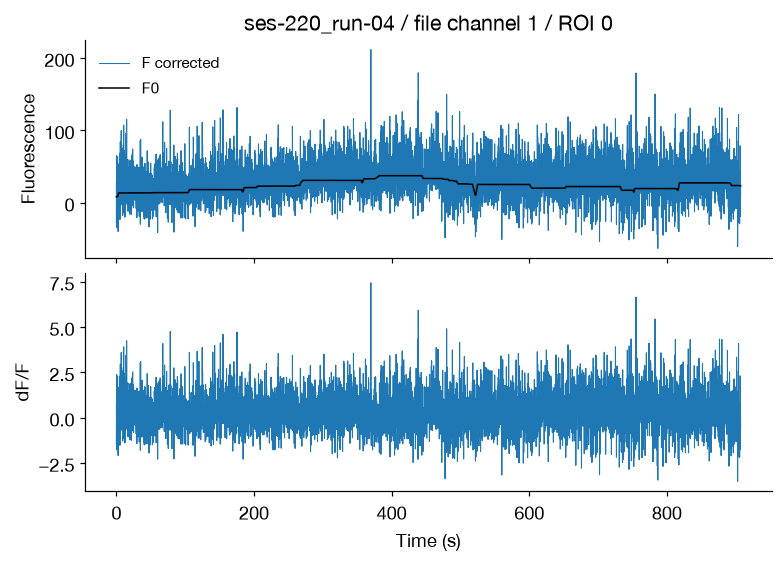

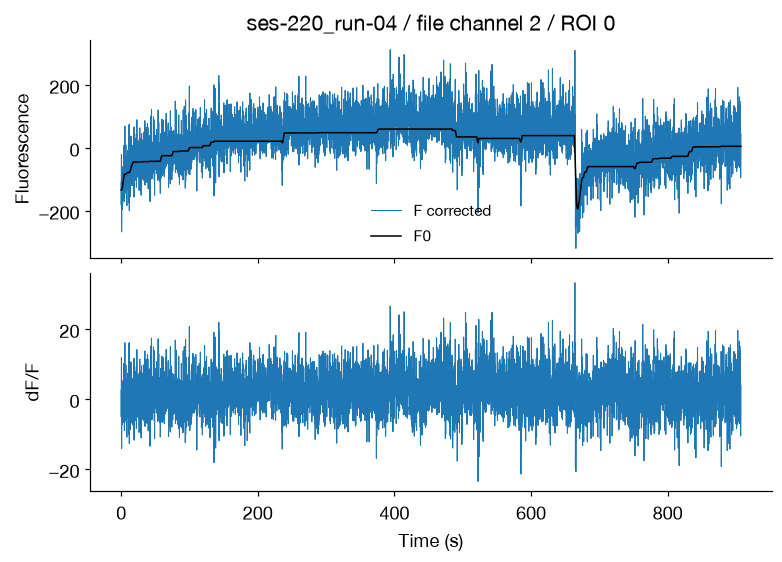

220 / run-04: [{'recording': 'ses-220_run-04', 'channel': 1, 'roi': 0, 'frames': 6823, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 24.005046844482422, 'abs_dff_p99': 3.272320032119751, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-220_run-04', 'channel': 2, 'roi': 0, 'frames': 6823, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 9.500865936279297, 'abs_dff_p99': 17.09813117980957, 'status': 'ok', 'defaulted_settings': []}]


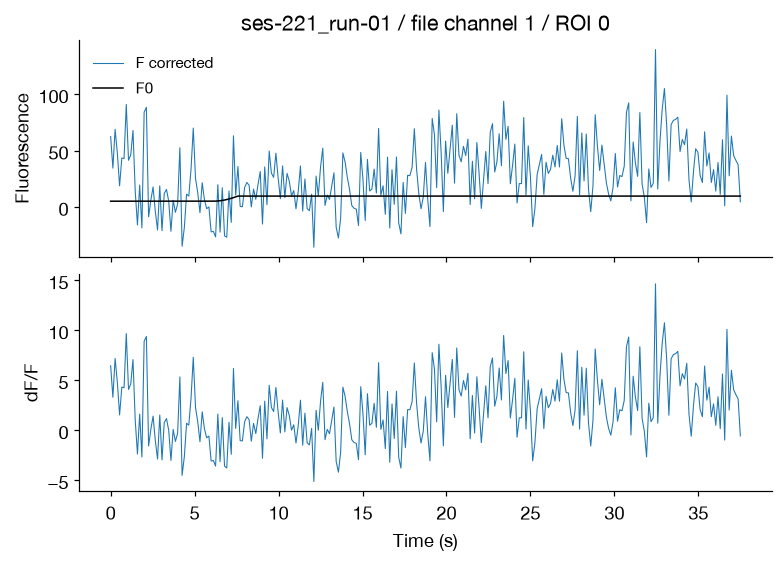

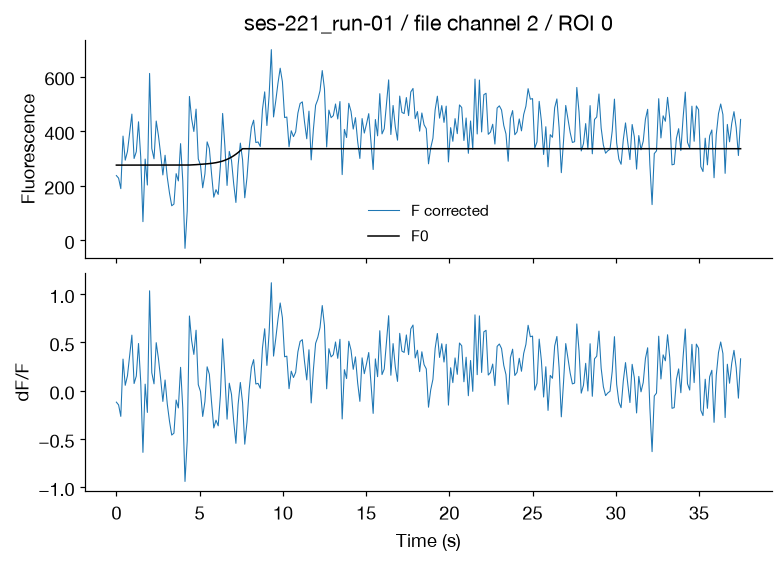

221 / run-01: [{'recording': 'ses-221_run-01', 'channel': 1, 'roi': 0, 'frames': 283, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 8.867192268371582, 'abs_dff_p99': 9.75954532623291, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-221_run-01', 'channel': 2, 'roi': 0, 'frames': 283, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 324.5803527832031, 'abs_dff_p99': 0.9147904515266418, 'status': 'ok', 'defaulted_settings': []}]


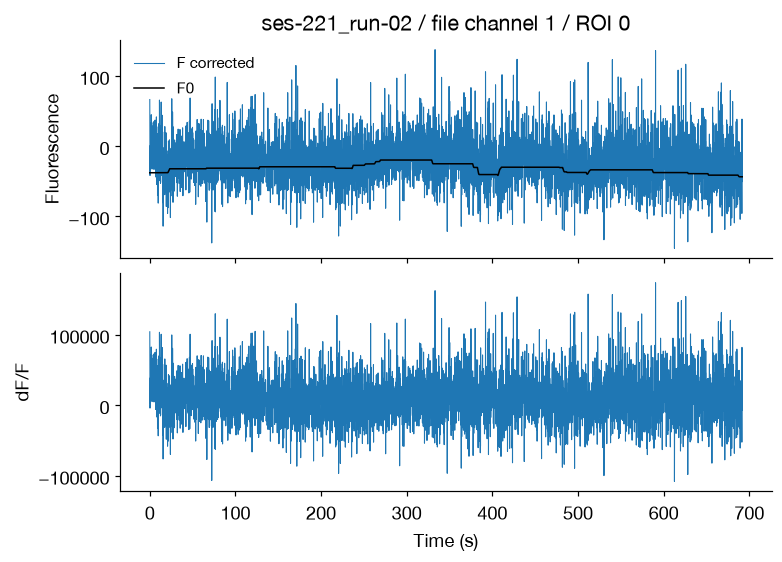

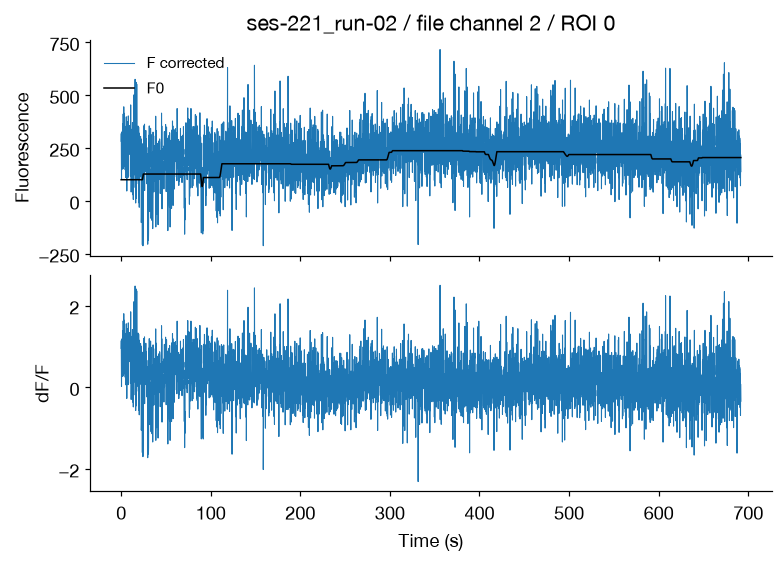

221 / run-02: [{'recording': 'ses-221_run-02', 'channel': 1, 'roi': 0, 'frames': 5203, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': -31.436737060546875, 'abs_dff_p99': 102040.0859375, 'status': 'CHECK F0', 'defaulted_settings': []}, {'recording': 'ses-221_run-02', 'channel': 2, 'roi': 0, 'frames': 5203, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 191.4724578857422, 'abs_dff_p99': 1.616931438446045, 'status': 'ok', 'defaulted_settings': []}]


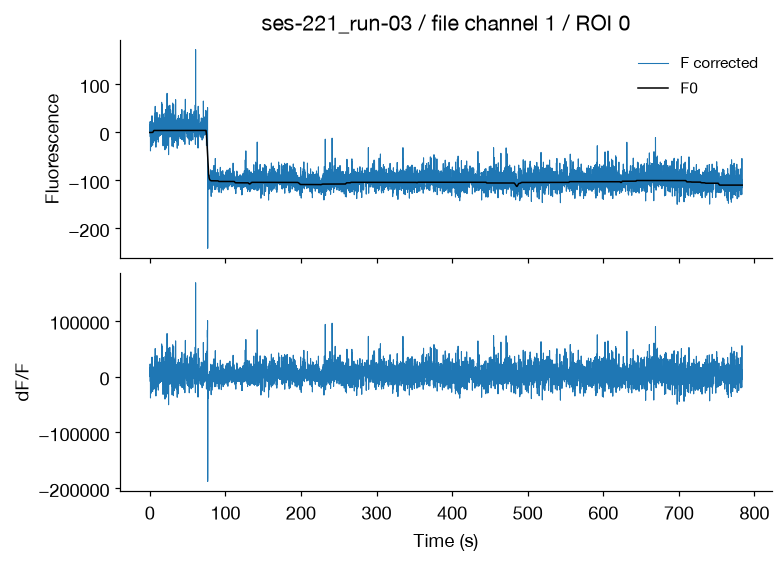

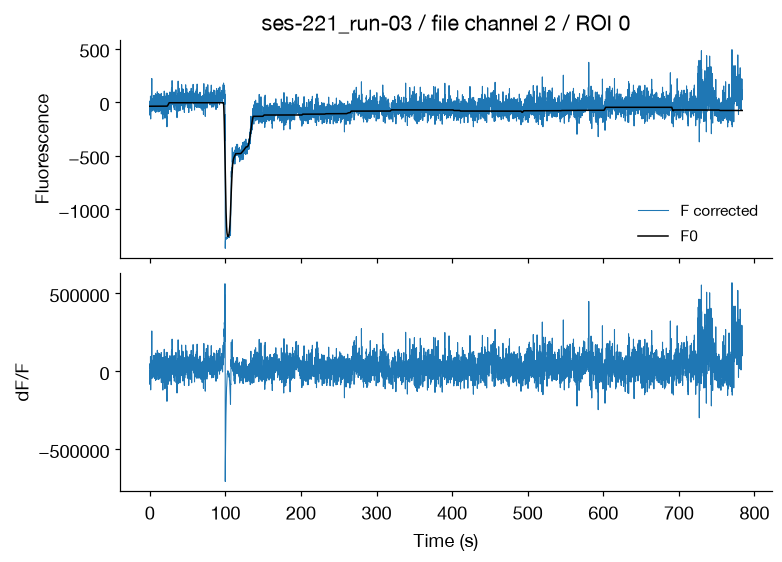

221 / run-03: [{'recording': 'ses-221_run-03', 'channel': 1, 'roi': 0, 'frames': 5896, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': -93.98543548583984, 'abs_dff_p99': 49914.76171875, 'status': 'CHECK F0', 'defaulted_settings': []}, {'recording': 'ses-221_run-03', 'channel': 2, 'roi': 0, 'frames': 5896, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': -96.93766021728516, 'abs_dff_p99': 301771.59375, 'status': 'CHECK F0', 'defaulted_settings': []}]


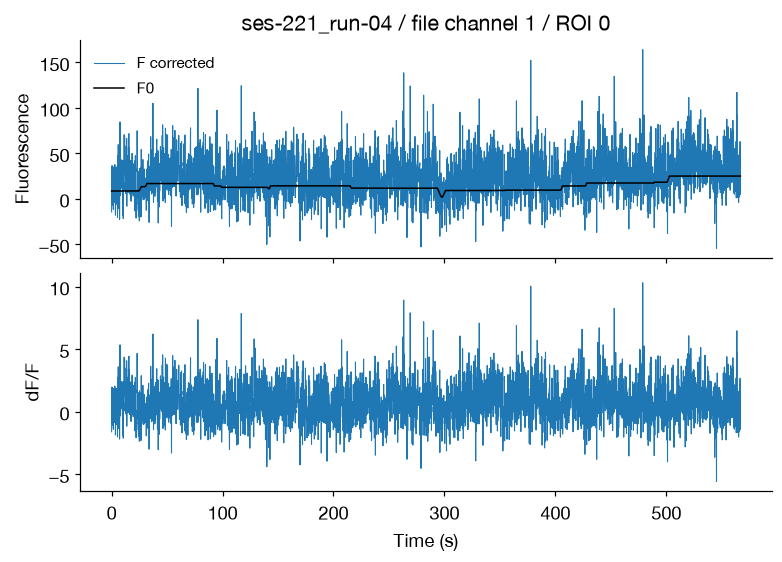

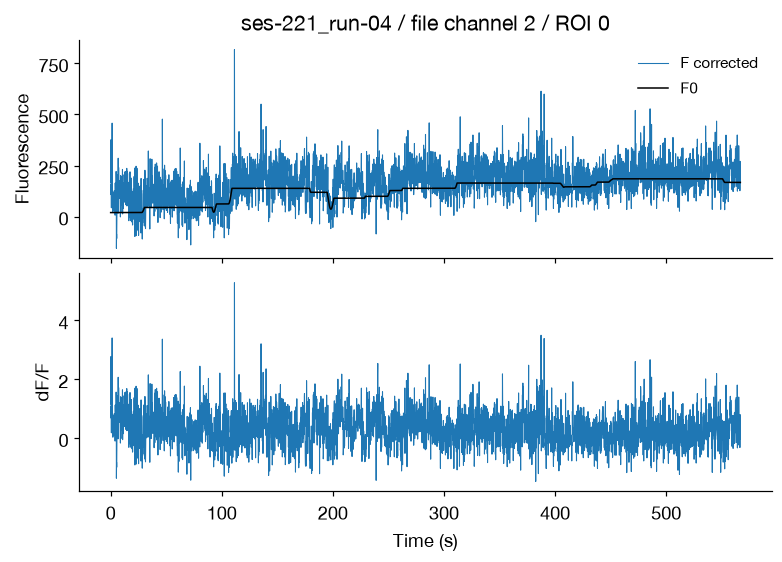

221 / run-04: [{'recording': 'ses-221_run-04', 'channel': 1, 'roi': 0, 'frames': 4263, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 14.247663497924805, 'abs_dff_p99': 4.715848445892334, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-221_run-04', 'channel': 2, 'roi': 0, 'frames': 4263, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 128.64044189453125, 'abs_dff_p99': 1.8492610454559326, 'status': 'ok', 'defaulted_settings': []}]


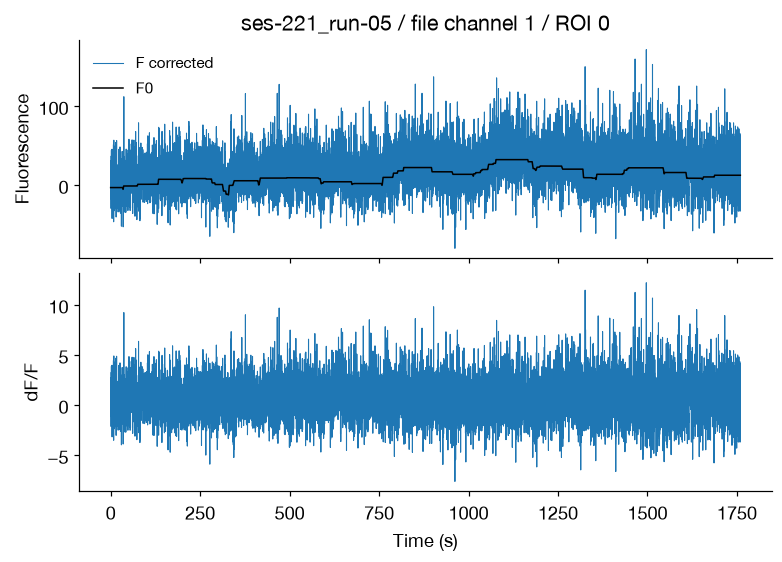

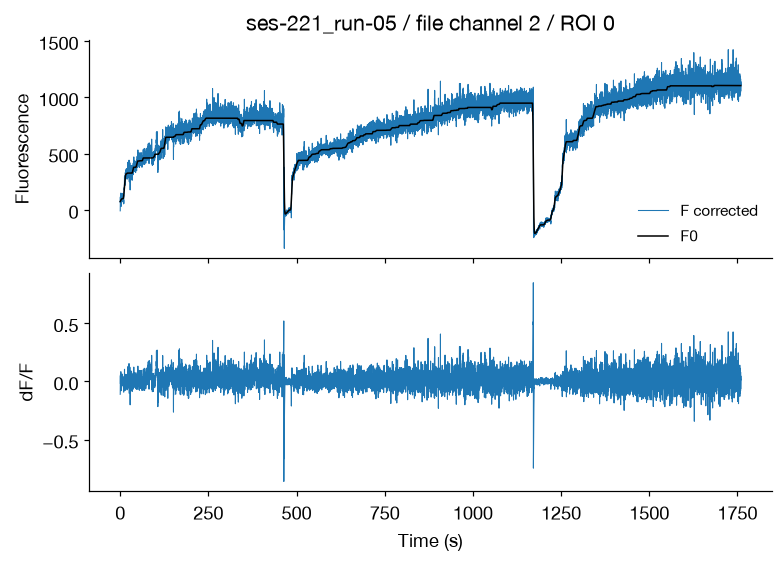

221 / run-05: [{'recording': 'ses-221_run-05', 'channel': 1, 'roi': 0, 'frames': 13233, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 12.284486770629883, 'abs_dff_p99': 5.787529468536377, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-221_run-05', 'channel': 2, 'roi': 0, 'frames': 13233, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 746.833984375, 'abs_dff_p99': 0.2245521992444992, 'status': 'ok', 'defaulted_settings': []}]


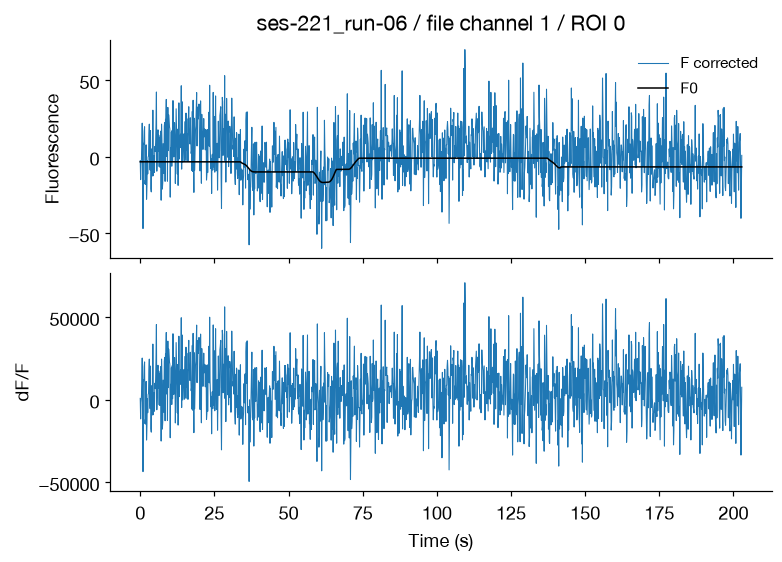

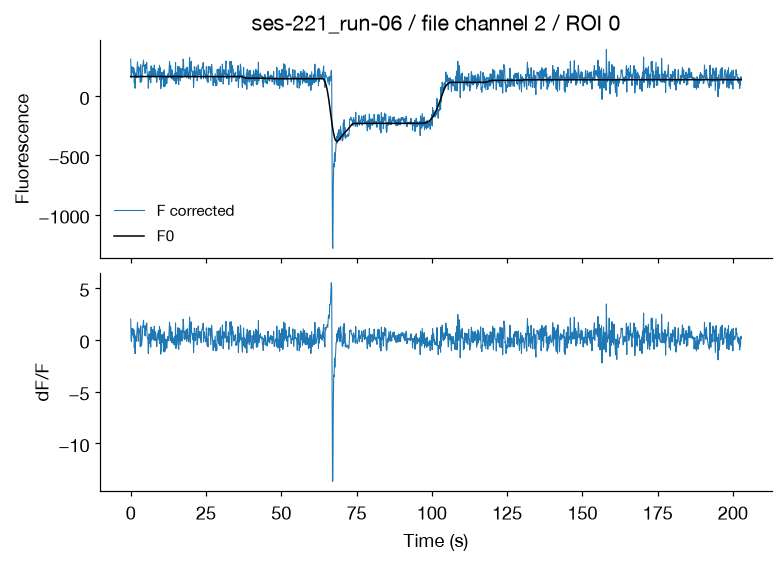

221 / run-06: [{'recording': 'ses-221_run-06', 'channel': 1, 'roi': 0, 'frames': 1526, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': -4.8304290771484375, 'abs_dff_p99': 49866.5703125, 'status': 'CHECK F0', 'defaulted_settings': []}, {'recording': 'ses-221_run-06', 'channel': 2, 'roi': 0, 'frames': 1526, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 73.69792175292969, 'abs_dff_p99': 2.4529032707214355, 'status': 'ok', 'defaulted_settings': []}]


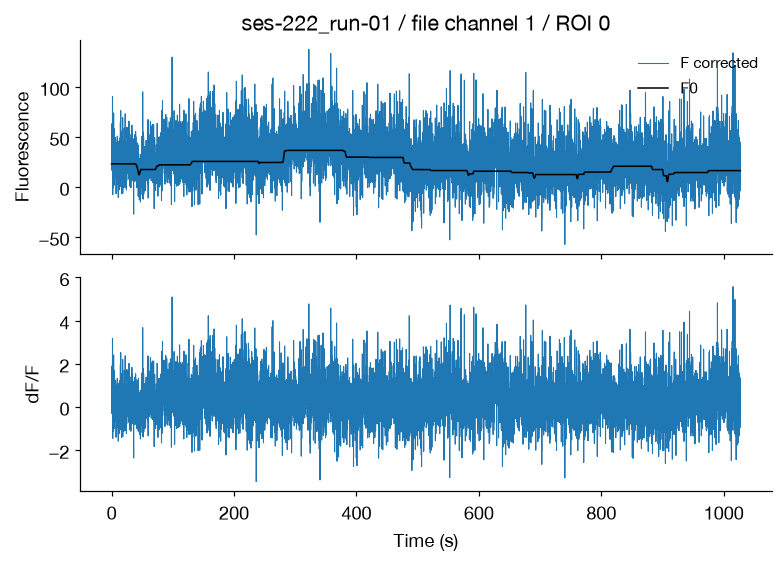

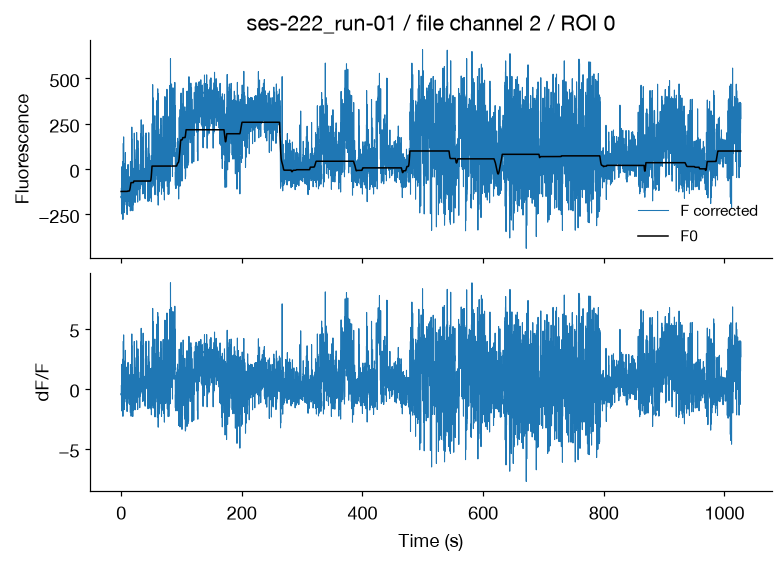

222 / run-01: [{'recording': 'ses-222_run-01', 'channel': 1, 'roi': 0, 'frames': 7726, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 21.17013931274414, 'abs_dff_p99': 3.0897793769836426, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-222_run-01', 'channel': 2, 'roi': 0, 'frames': 7726, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 67.23063659667969, 'abs_dff_p99': 6.3378987312316895, 'status': 'ok', 'defaulted_settings': []}]


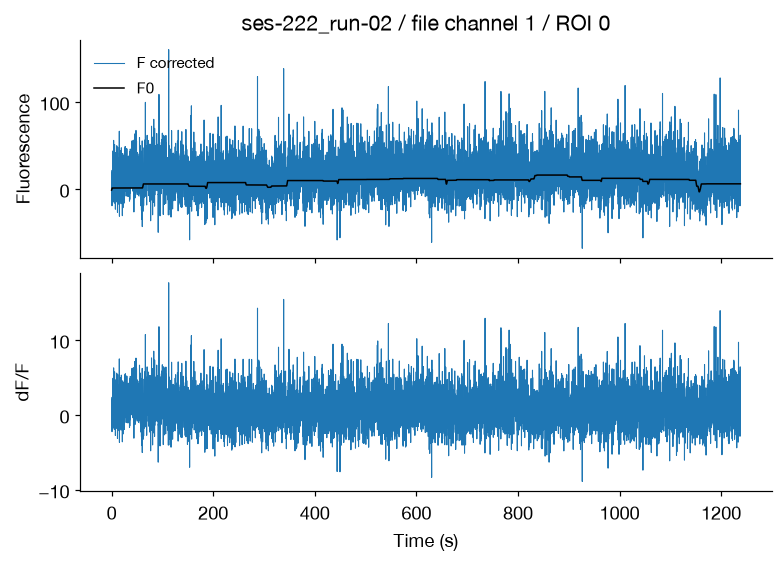

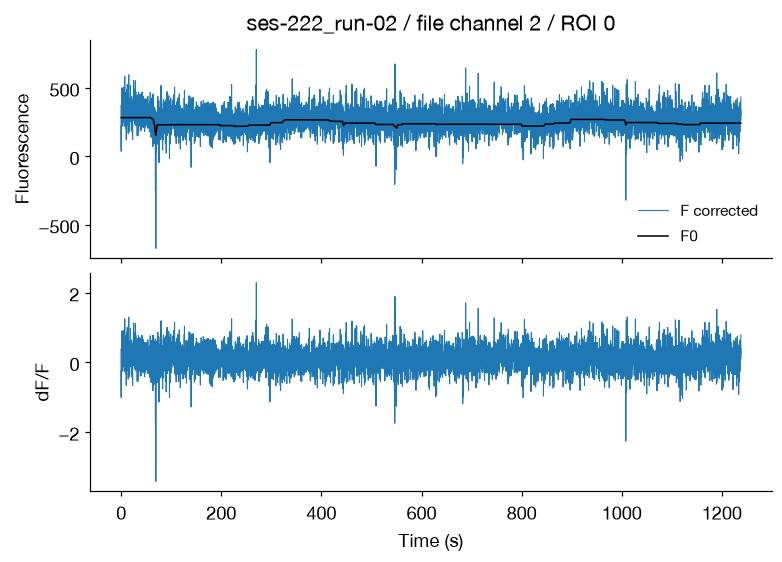

222 / run-02: [{'recording': 'ses-222_run-02', 'channel': 1, 'roi': 0, 'frames': 9310, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 8.746183395385742, 'abs_dff_p99': 7.295437812805176, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-222_run-02', 'channel': 2, 'roi': 0, 'frames': 9310, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 242.0663299560547, 'abs_dff_p99': 0.9234465956687927, 'status': 'ok', 'defaulted_settings': []}]


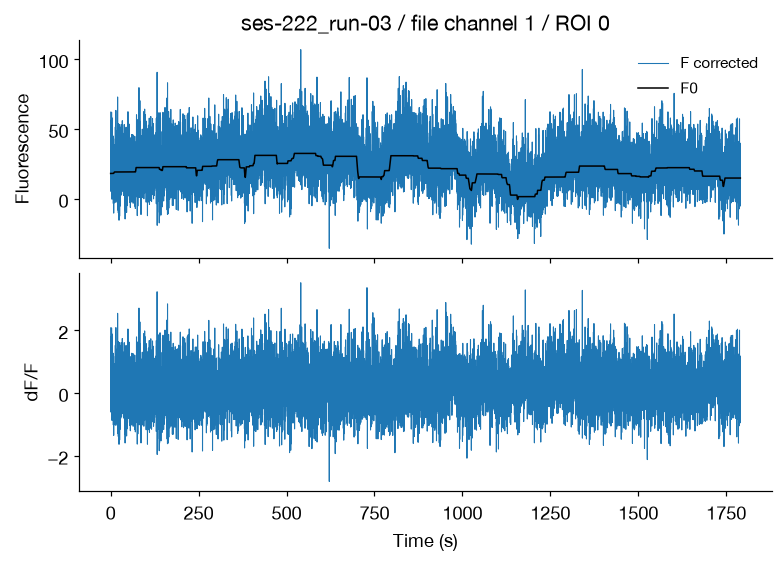

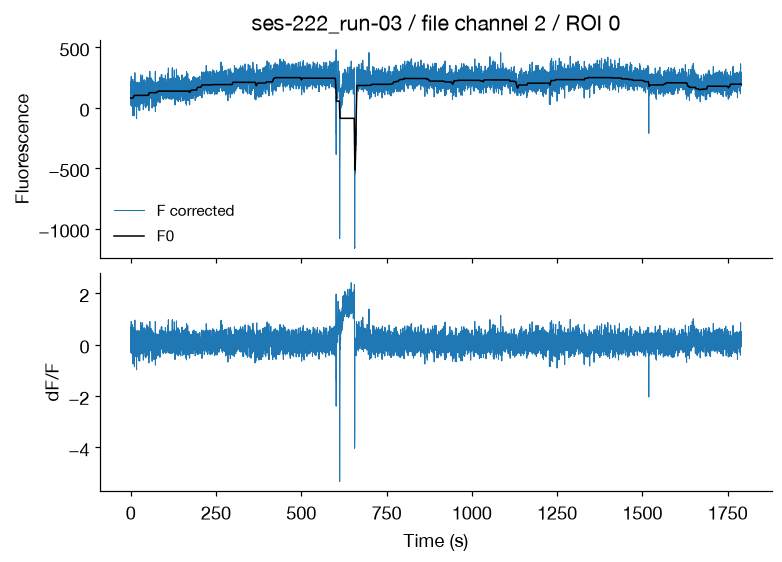

222 / run-03: [{'recording': 'ses-222_run-03', 'channel': 1, 'roi': 0, 'frames': 13463, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 21.14310073852539, 'abs_dff_p99': 1.9542094469070435, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-222_run-03', 'channel': 2, 'roi': 0, 'frames': 13463, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 196.8372802734375, 'abs_dff_p99': 1.636596441268921, 'status': 'ok', 'defaulted_settings': []}]


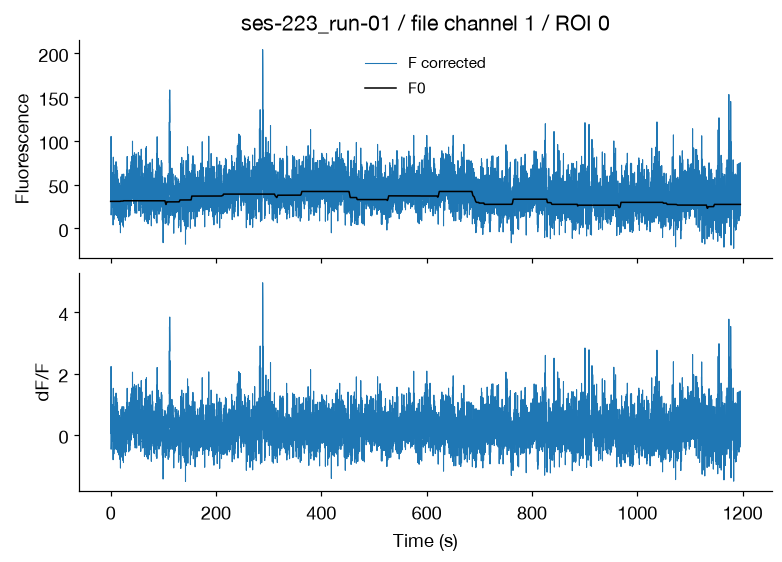

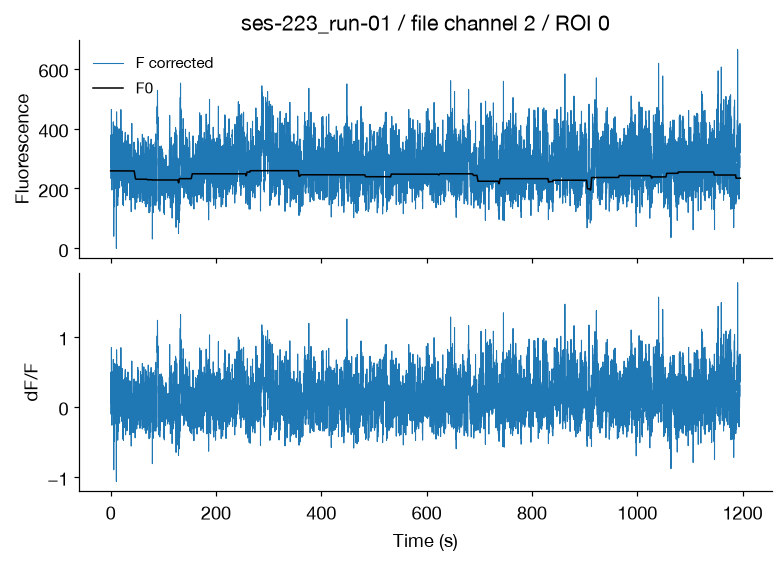

223 / run-01: [{'recording': 'ses-223_run-01', 'channel': 1, 'roi': 0, 'frames': 8994, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 33.249786376953125, 'abs_dff_p99': 1.7418742179870605, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-223_run-01', 'channel': 2, 'roi': 0, 'frames': 8994, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 242.83055114746094, 'abs_dff_p99': 0.9348464608192444, 'status': 'ok', 'defaulted_settings': []}]


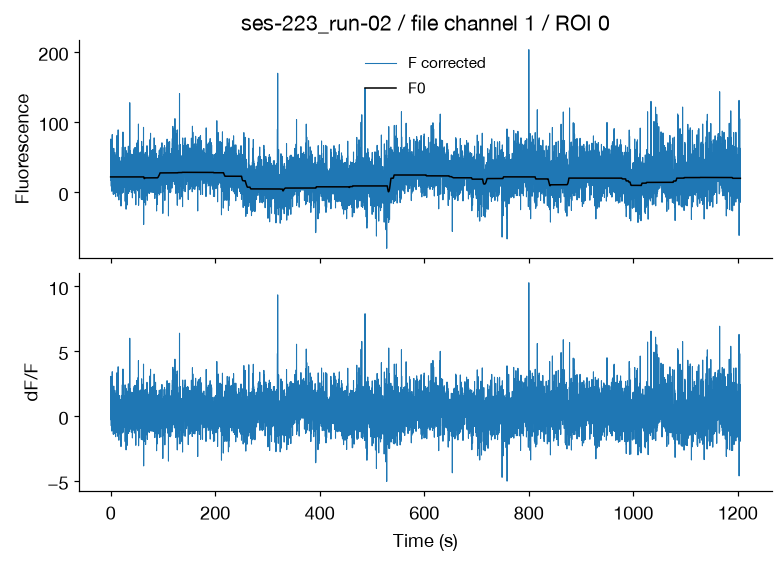

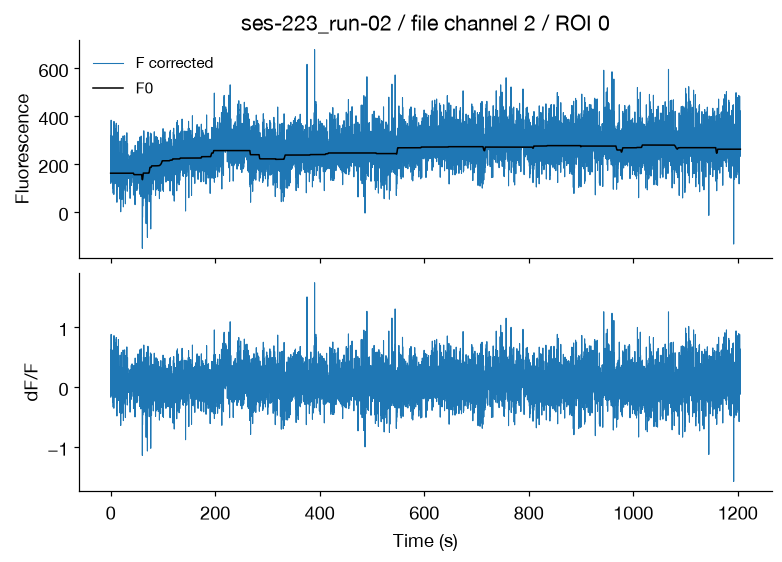

223 / run-02: [{'recording': 'ses-223_run-02', 'channel': 1, 'roi': 0, 'frames': 9063, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 17.63838005065918, 'abs_dff_p99': 3.727681875228882, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-223_run-02', 'channel': 2, 'roi': 0, 'frames': 9063, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 251.09999084472656, 'abs_dff_p99': 0.7857045531272888, 'status': 'ok', 'defaulted_settings': []}]


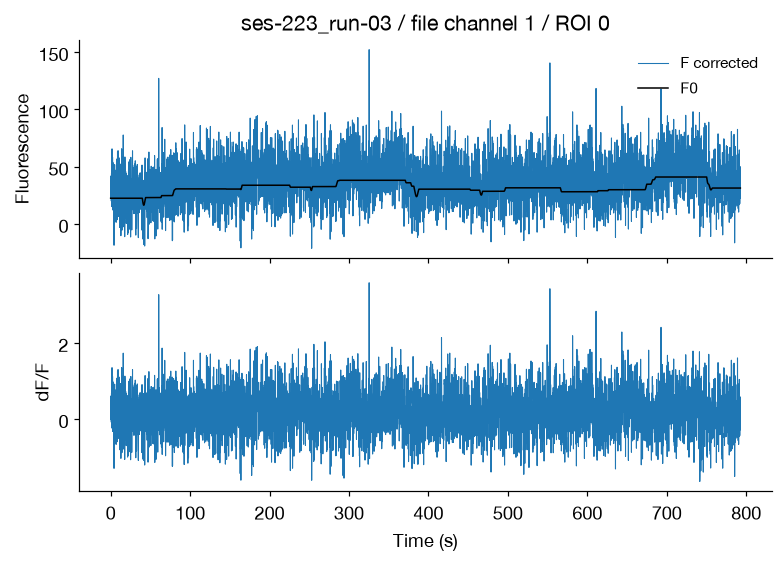

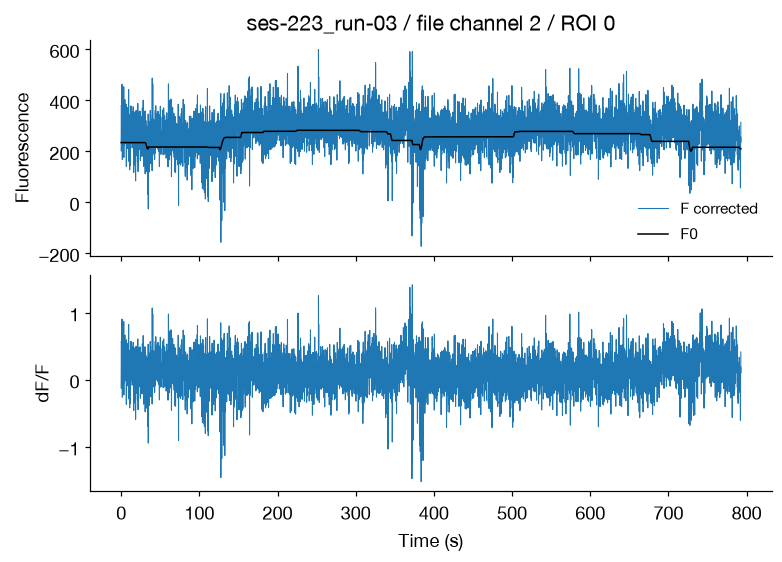

223 / run-03: [{'recording': 'ses-223_run-03', 'channel': 1, 'roi': 0, 'frames': 5962, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 31.826562881469727, 'abs_dff_p99': 1.6066333055496216, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-223_run-03', 'channel': 2, 'roi': 0, 'frames': 5962, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 253.263671875, 'abs_dff_p99': 0.8125708103179932, 'status': 'ok', 'defaulted_settings': []}]


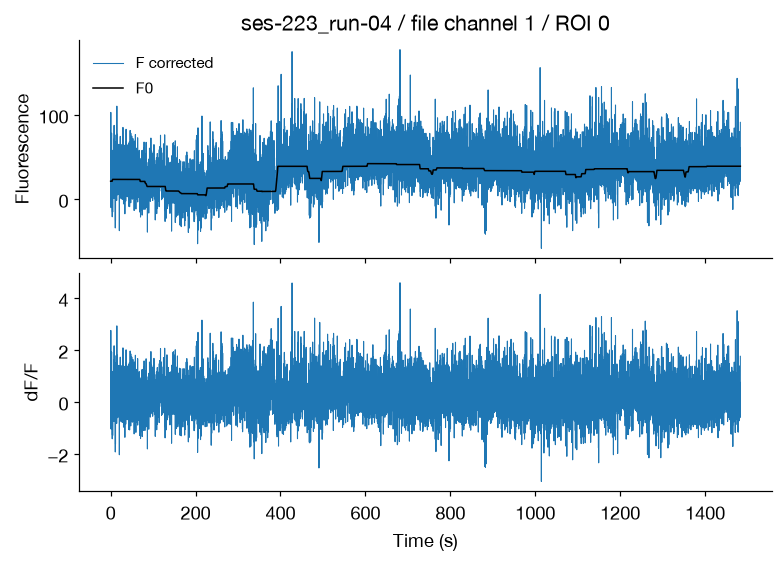

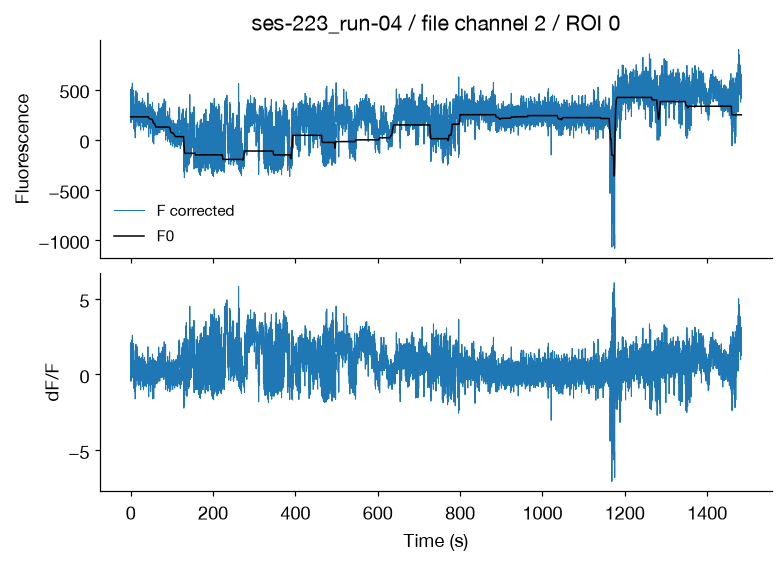

223 / run-04: [{'recording': 'ses-223_run-04', 'channel': 1, 'roi': 0, 'frames': 11153, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 29.749568939208984, 'abs_dff_p99': 2.2231180667877197, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-223_run-04', 'channel': 2, 'roi': 0, 'frames': 11153, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 129.71307373046875, 'abs_dff_p99': 3.5776562690734863, 'status': 'ok', 'defaulted_settings': []}]


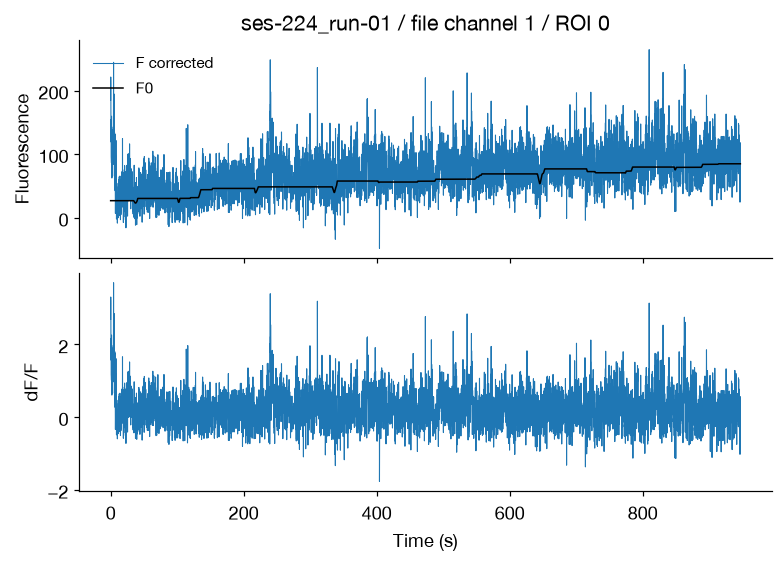

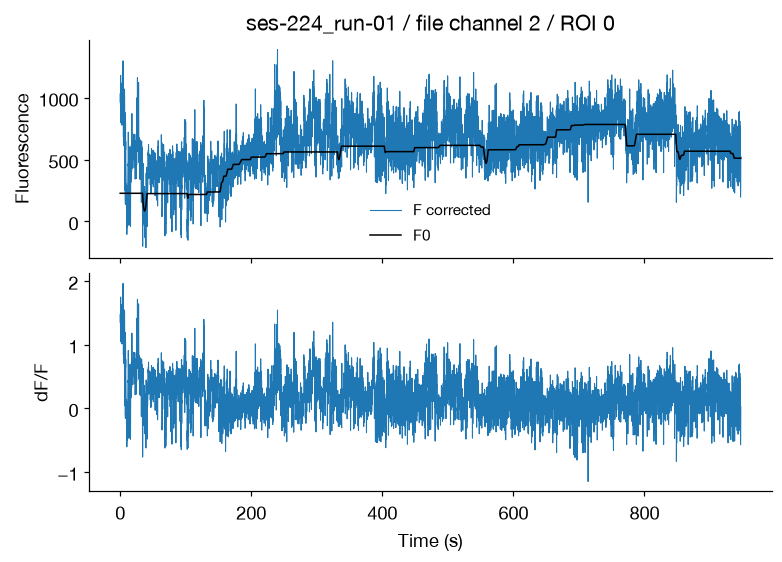

224 / run-01: [{'recording': 'ses-224_run-01', 'channel': 1, 'roi': 0, 'frames': 7122, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 58.8828010559082, 'abs_dff_p99': 1.6397359371185303, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-224_run-01', 'channel': 2, 'roi': 0, 'frames': 7122, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 546.4677124023438, 'abs_dff_p99': 1.053685188293457, 'status': 'ok', 'defaulted_settings': []}]


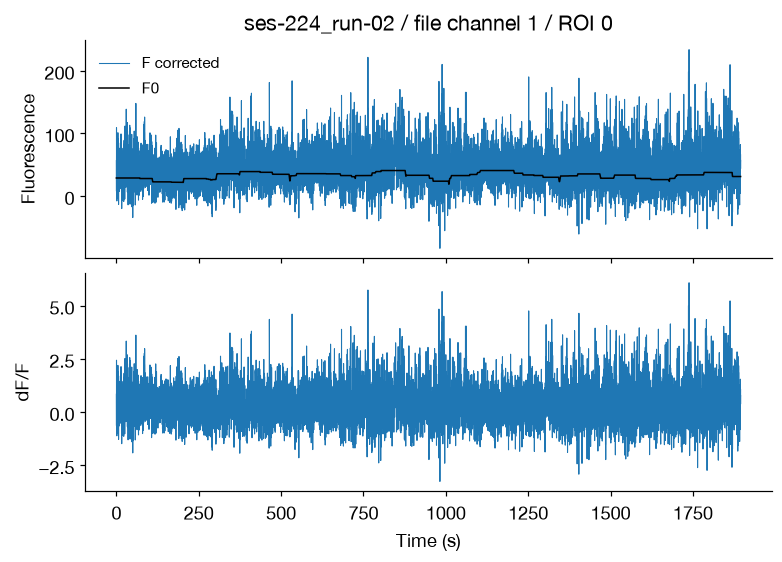

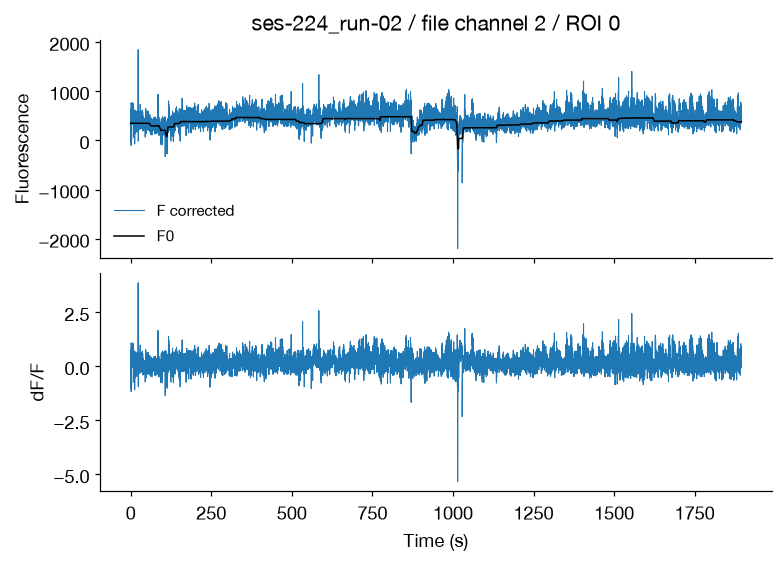

224 / run-02: [{'recording': 'ses-224_run-02', 'channel': 1, 'roi': 0, 'frames': 14250, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 32.89618682861328, 'abs_dff_p99': 2.8242743015289307, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-224_run-02', 'channel': 2, 'roi': 0, 'frames': 14250, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 386.9051208496094, 'abs_dff_p99': 1.1373716592788696, 'status': 'ok', 'defaulted_settings': []}]


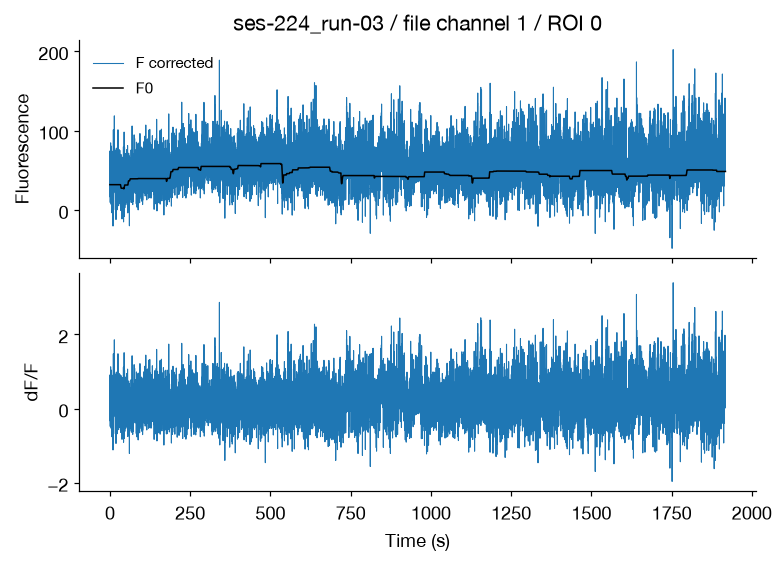

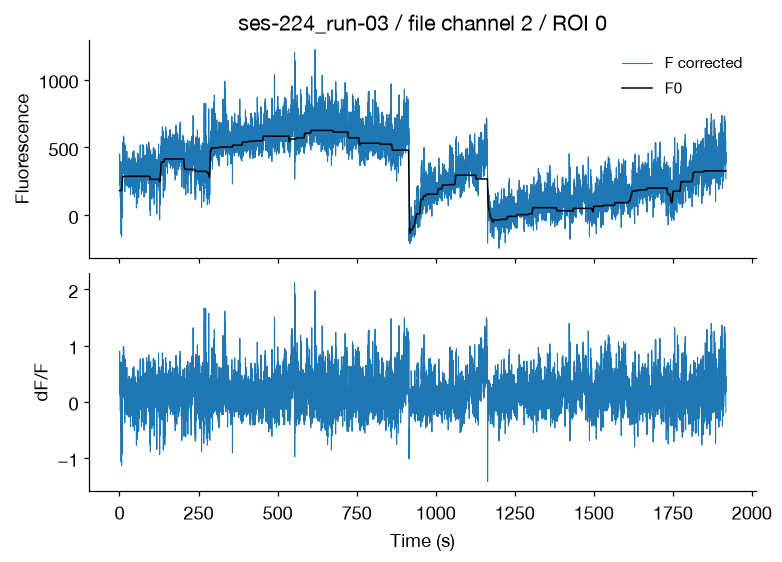

224 / run-03: [{'recording': 'ses-224_run-03', 'channel': 1, 'roi': 0, 'frames': 14423, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 46.7367057800293, 'abs_dff_p99': 1.6715147495269775, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-224_run-03', 'channel': 2, 'roi': 0, 'frames': 14423, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 301.52105712890625, 'abs_dff_p99': 1.0164598226547241, 'status': 'ok', 'defaulted_settings': []}]


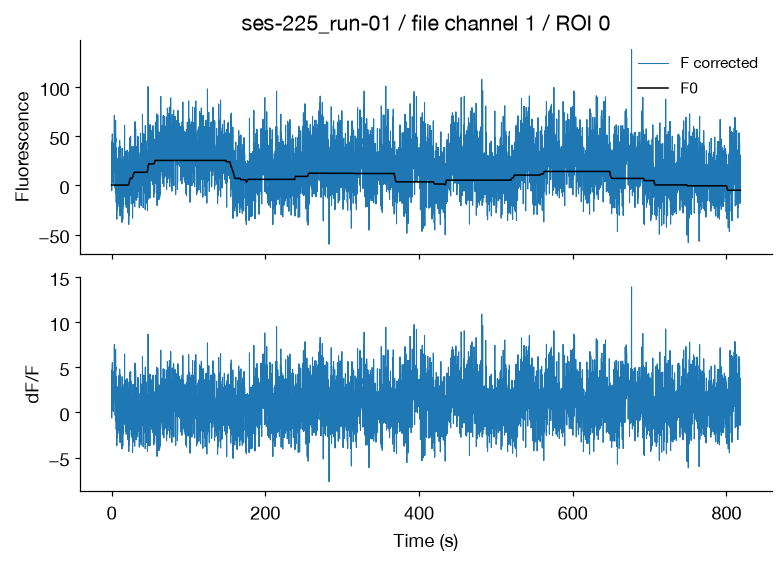

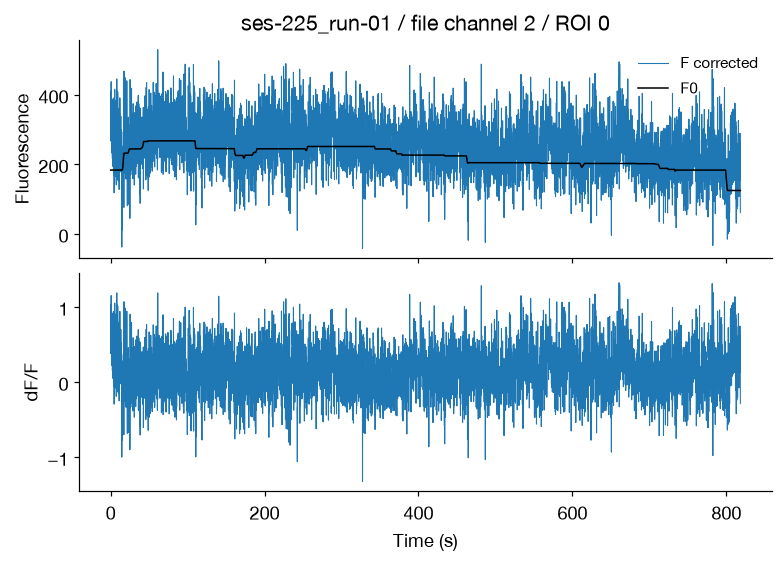

225 / run-01: [{'recording': 'ses-225_run-01', 'channel': 1, 'roi': 0, 'frames': 6154, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 9.423030853271484, 'abs_dff_p99': 7.262608528137207, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-225_run-01', 'channel': 2, 'roi': 0, 'frames': 6154, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 221.0379180908203, 'abs_dff_p99': 0.9709288477897644, 'status': 'ok', 'defaulted_settings': []}]


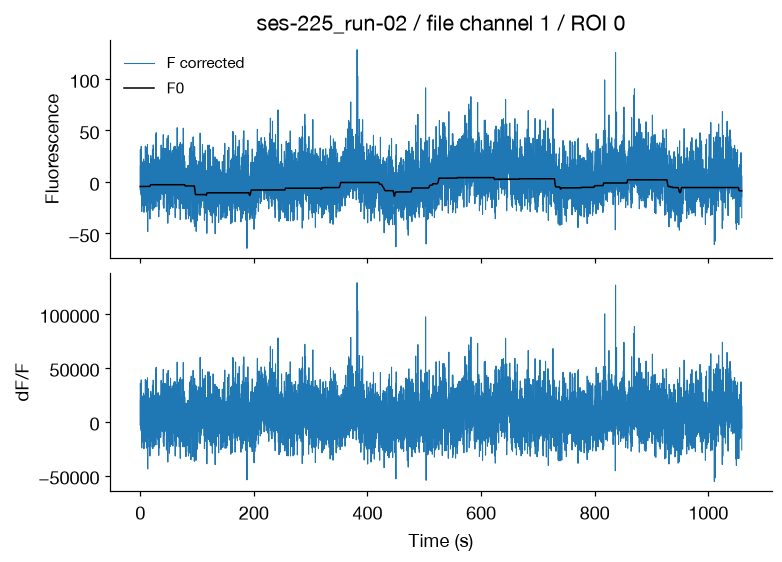

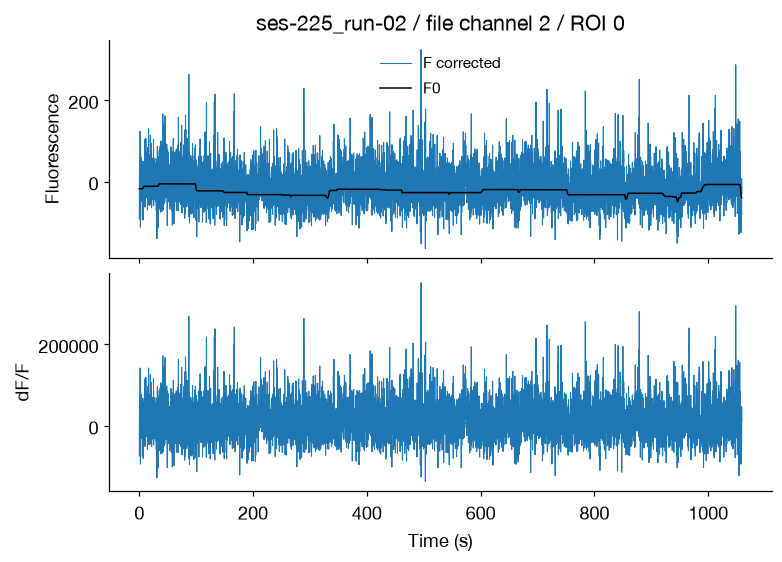

225 / run-02: [{'recording': 'ses-225_run-02', 'channel': 1, 'roi': 0, 'frames': 7965, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': -3.3112802505493164, 'abs_dff_p99': 53081.41796875, 'status': 'CHECK F0', 'defaulted_settings': []}, {'recording': 'ses-225_run-02', 'channel': 2, 'roi': 0, 'frames': 7965, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': -23.915348052978516, 'abs_dff_p99': 143892.484375, 'status': 'CHECK F0', 'defaulted_settings': []}]


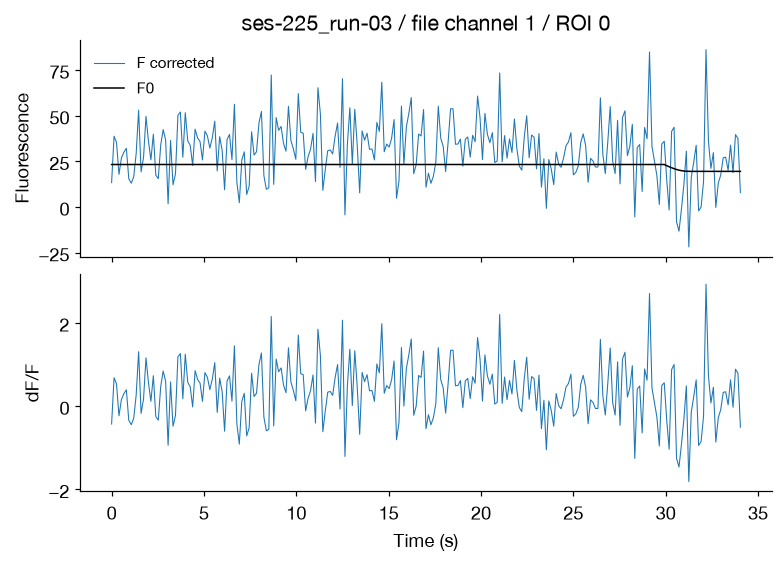

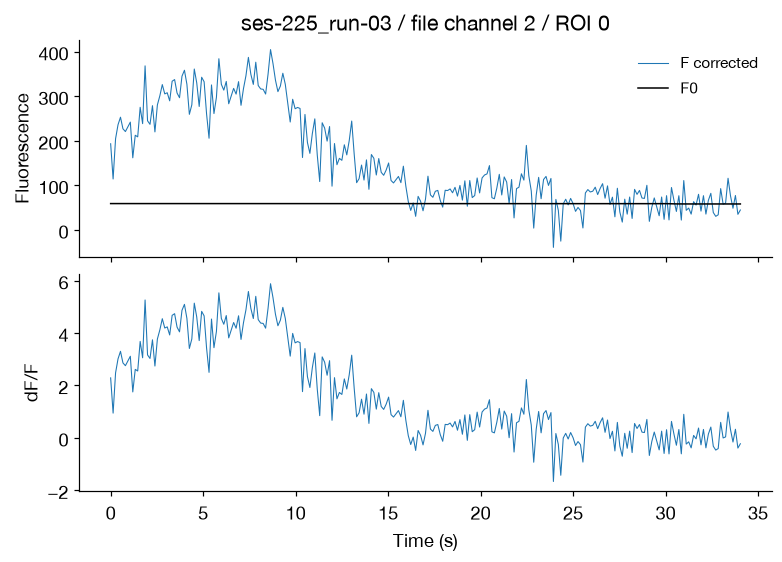

225 / run-03: [{'recording': 'ses-225_run-03', 'channel': 1, 'roi': 0, 'frames': 257, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 22.78582763671875, 'abs_dff_p99': 2.1722042560577393, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-225_run-03', 'channel': 2, 'roi': 0, 'frames': 257, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 58.78458786010742, 'abs_dff_p99': 5.454699516296387, 'status': 'ok', 'defaulted_settings': []}]


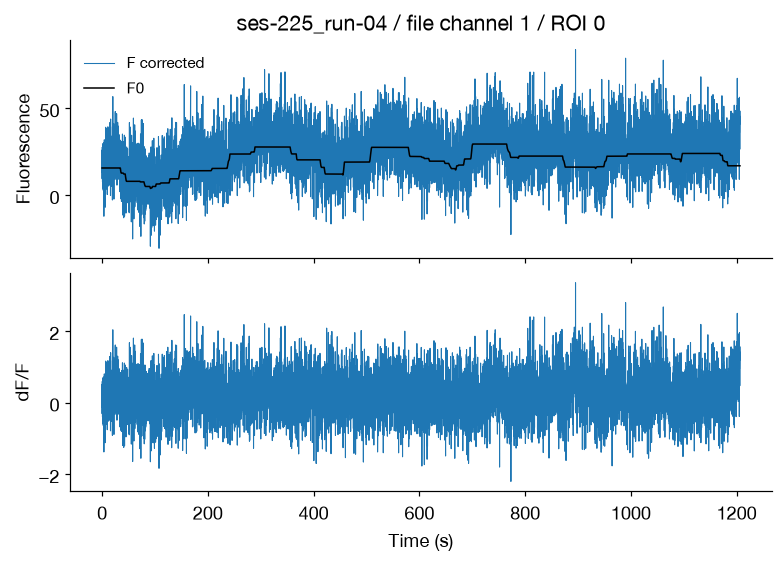

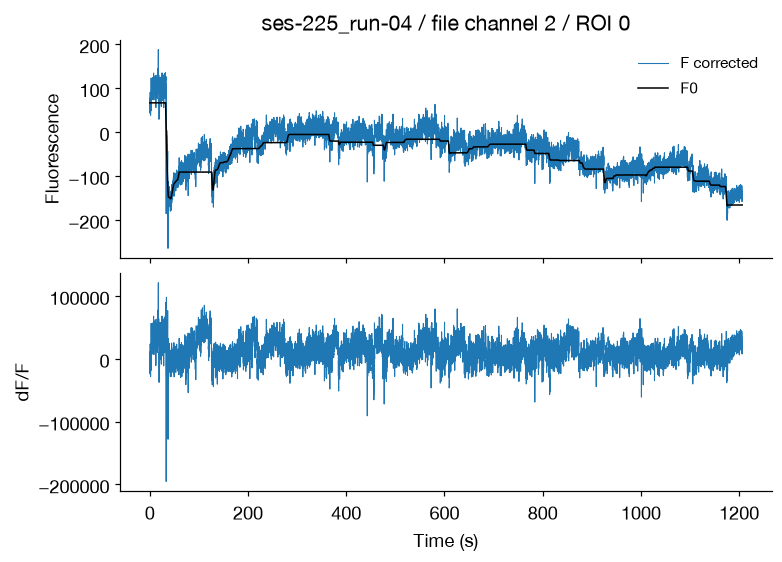

225 / run-04: [{'recording': 'ses-225_run-04', 'channel': 1, 'roi': 0, 'frames': 9072, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 20.168893814086914, 'abs_dff_p99': 1.7617868185043335, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-225_run-04', 'channel': 2, 'roi': 0, 'frames': 9072, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': -53.565399169921875, 'abs_dff_p99': 59175.95703125, 'status': 'CHECK F0', 'defaulted_settings': []}]


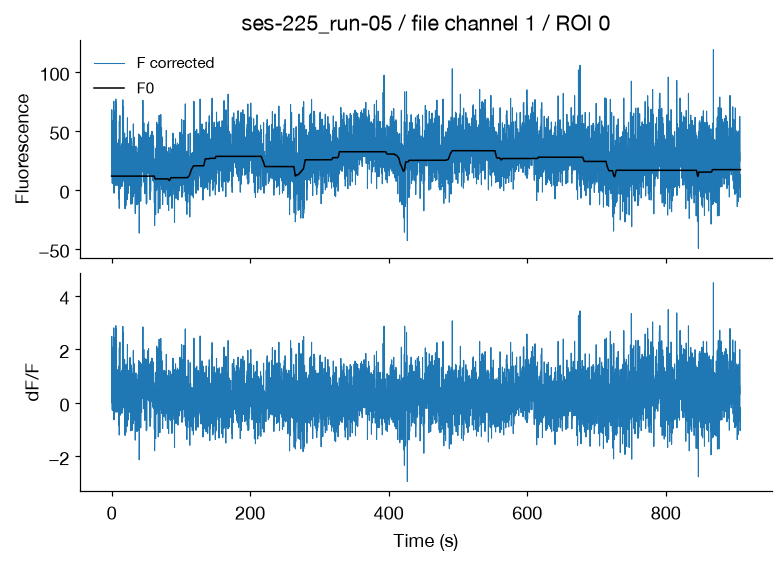

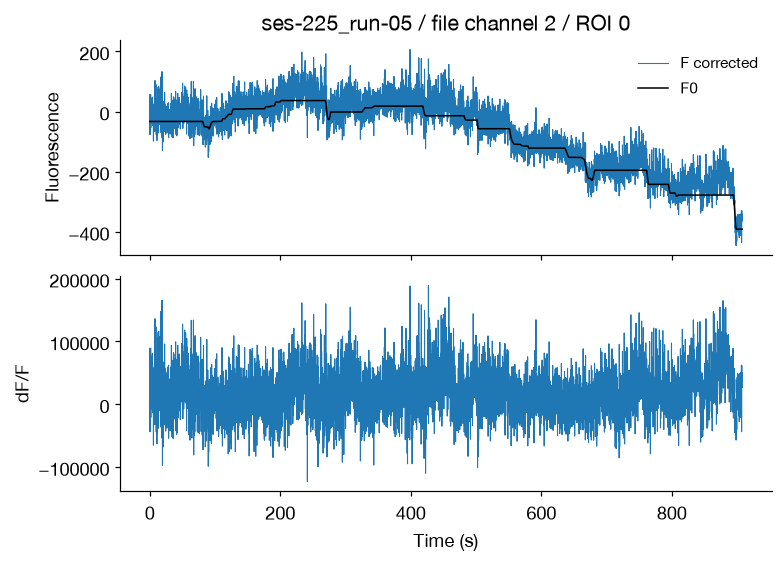

225 / run-05: [{'recording': 'ses-225_run-05', 'channel': 1, 'roi': 0, 'frames': 6828, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 22.6872615814209, 'abs_dff_p99': 2.2489712238311768, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-225_run-05', 'channel': 2, 'roi': 0, 'frames': 6828, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': -85.225341796875, 'abs_dff_p99': 117873.4140625, 'status': 'CHECK F0', 'defaulted_settings': []}]


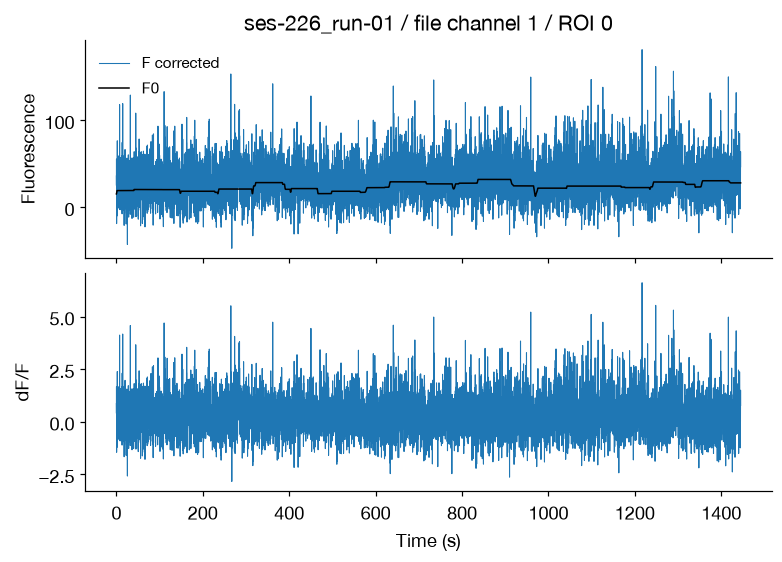

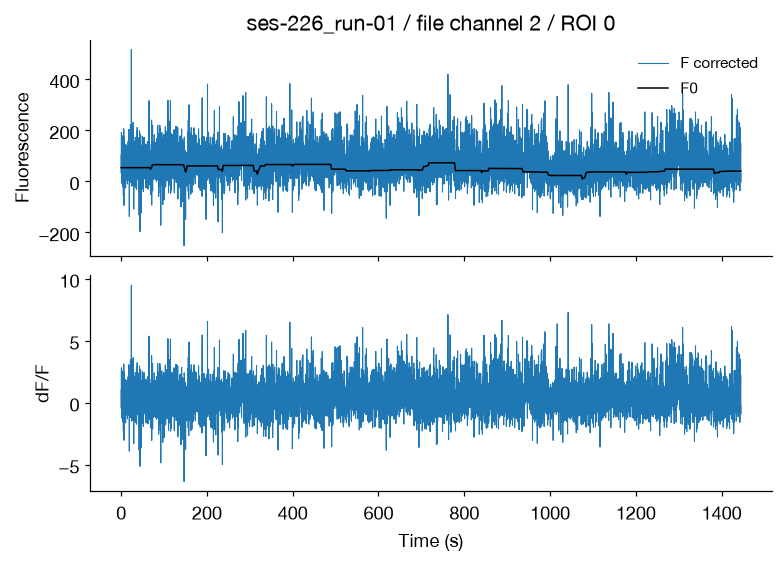

226 / run-01: [{'recording': 'ses-226_run-01', 'channel': 1, 'roi': 0, 'frames': 10866, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 24.002241134643555, 'abs_dff_p99': 2.80489444732666, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-226_run-01', 'channel': 2, 'roi': 0, 'frames': 10866, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 48.85374069213867, 'abs_dff_p99': 4.057436466217041, 'status': 'ok', 'defaulted_settings': []}]


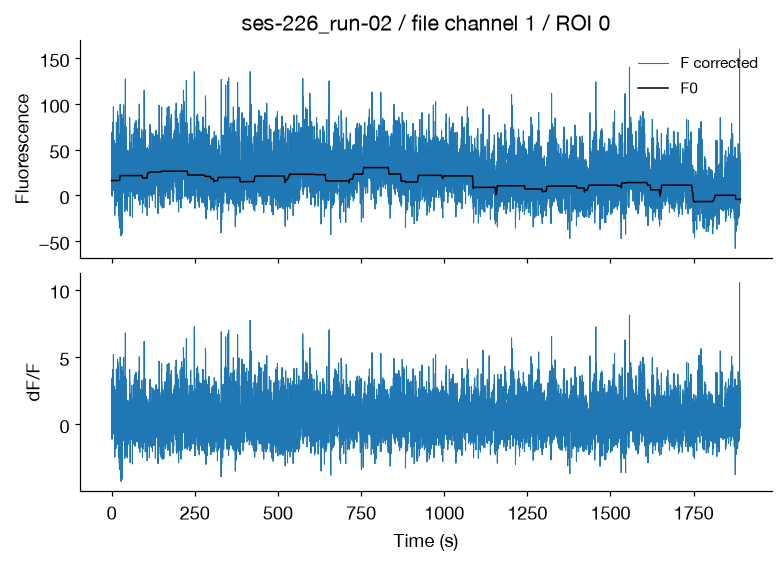

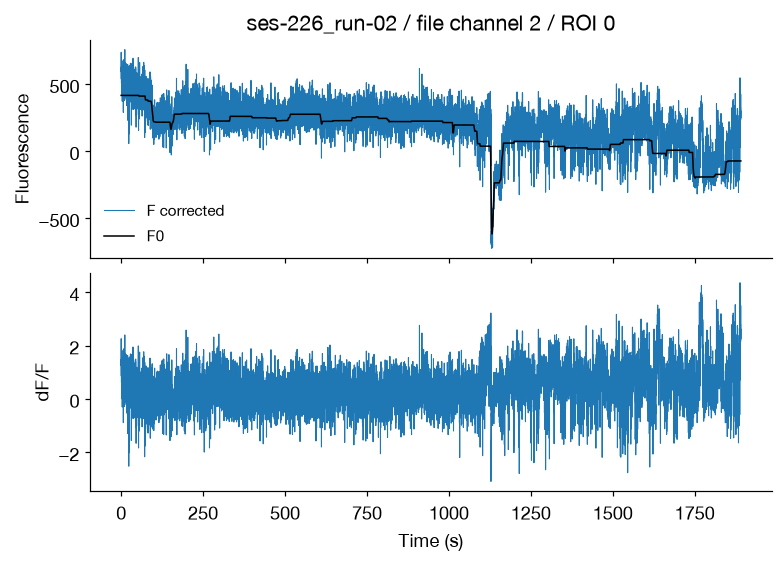

226 / run-02: [{'recording': 'ses-226_run-02', 'channel': 1, 'roi': 0, 'frames': 14220, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 15.562581062316895, 'abs_dff_p99': 4.174234867095947, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-226_run-02', 'channel': 2, 'roi': 0, 'frames': 14220, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 142.4111328125, 'abs_dff_p99': 2.547853469848633, 'status': 'ok', 'defaulted_settings': []}]


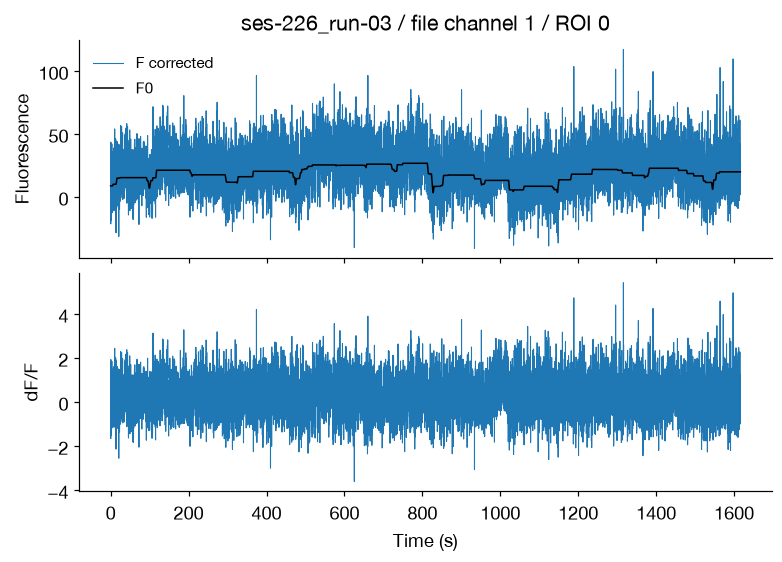

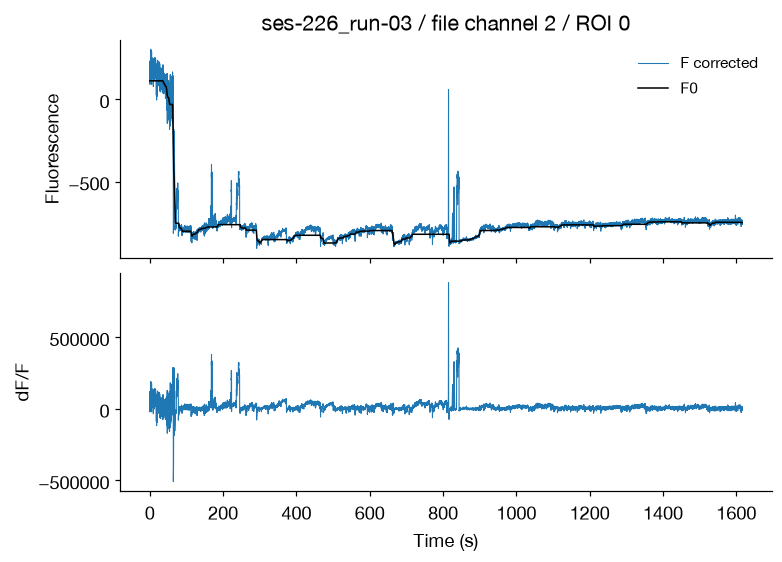

226 / run-03: [{'recording': 'ses-226_run-03', 'channel': 1, 'roi': 0, 'frames': 12154, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 18.118127822875977, 'abs_dff_p99': 2.4934241771698, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-226_run-03', 'channel': 2, 'roi': 0, 'frames': 12154, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': -759.775390625, 'abs_dff_p99': 221715.765625, 'status': 'CHECK F0', 'defaulted_settings': []}]


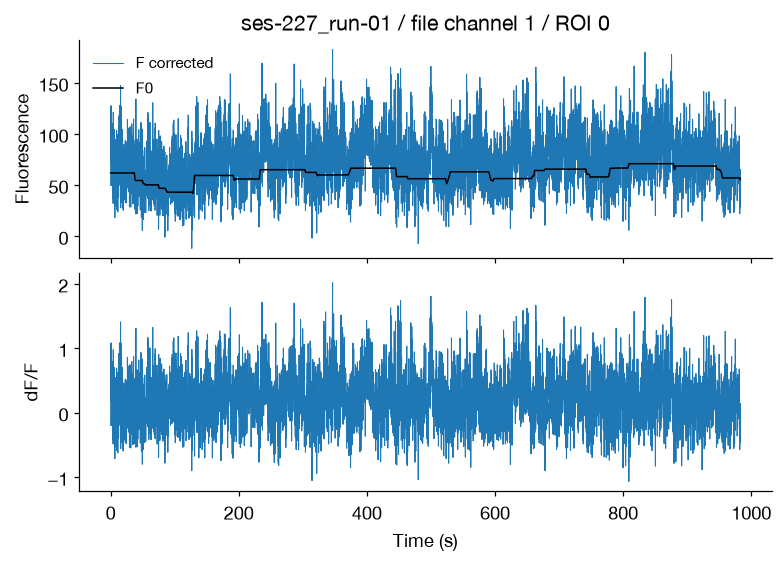

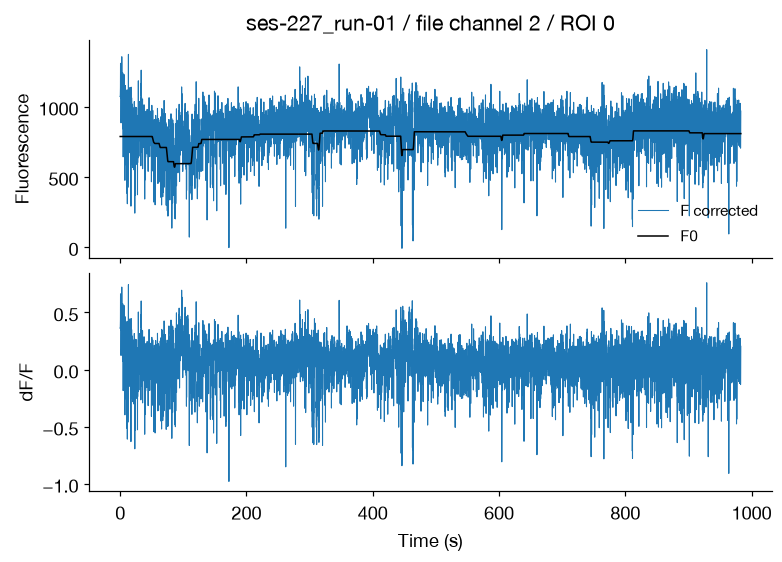

227 / run-01: [{'recording': 'ses-227_run-01', 'channel': 1, 'roi': 0, 'frames': 7393, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 60.93201446533203, 'abs_dff_p99': 1.2662516832351685, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-227_run-01', 'channel': 2, 'roi': 0, 'frames': 7393, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 786.667236328125, 'abs_dff_p99': 0.5456241965293884, 'status': 'ok', 'defaulted_settings': []}]


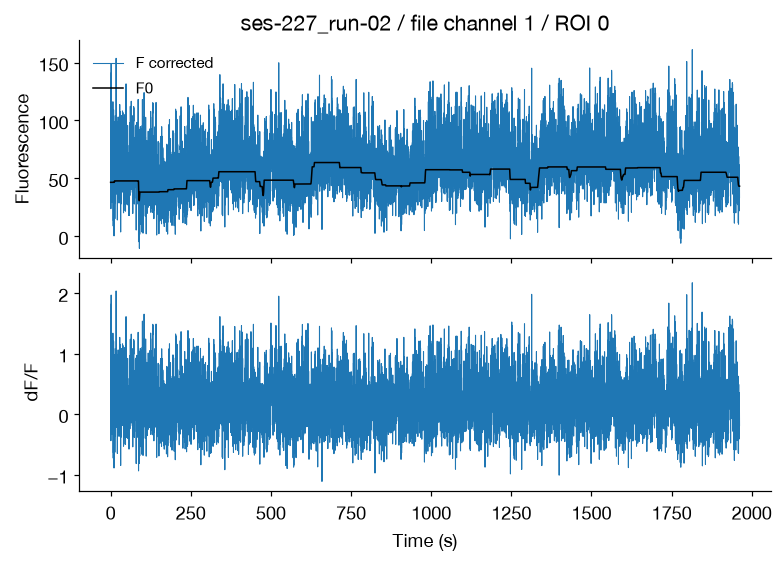

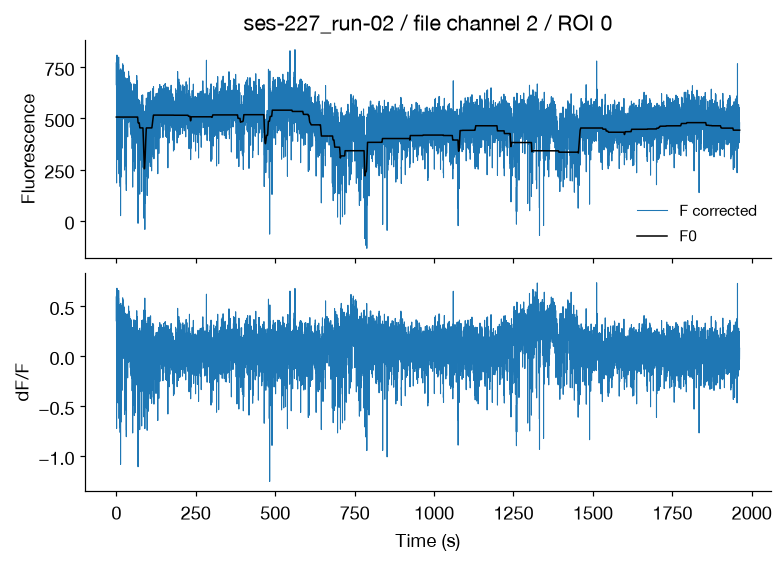

227 / run-02: [{'recording': 'ses-227_run-02', 'channel': 1, 'roi': 0, 'frames': 14754, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 52.08230972290039, 'abs_dff_p99': 1.2577272653579712, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-227_run-02', 'channel': 2, 'roi': 0, 'frames': 14754, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 444.637451171875, 'abs_dff_p99': 0.5241515040397644, 'status': 'ok', 'defaulted_settings': []}]


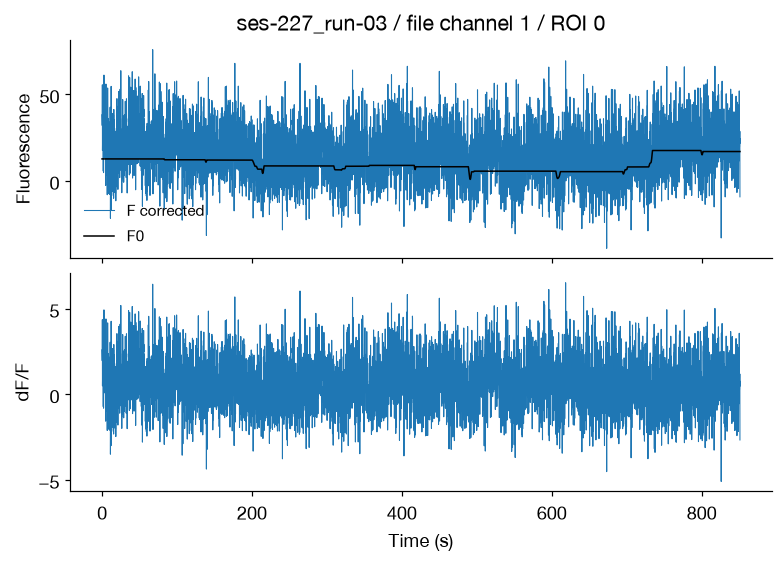

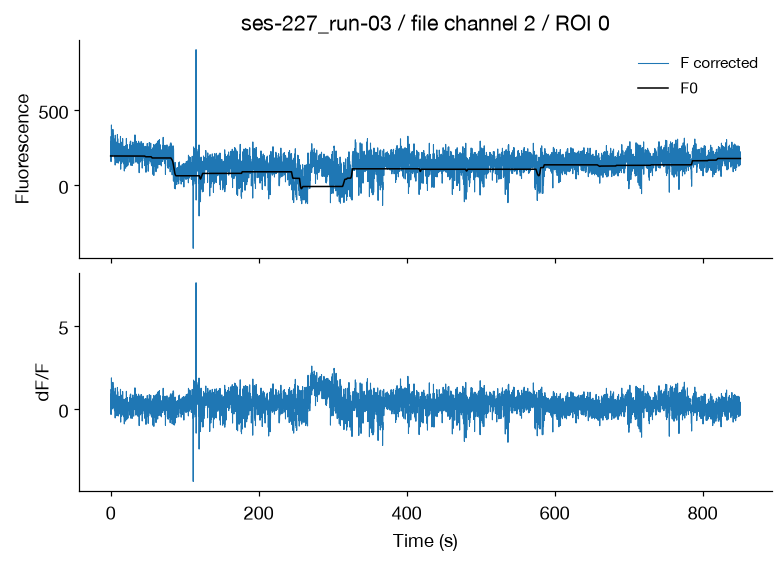

227 / run-03: [{'recording': 'ses-227_run-03', 'channel': 1, 'roi': 0, 'frames': 6401, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 9.825905799865723, 'abs_dff_p99': 4.4249467849731445, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-227_run-03', 'channel': 2, 'roi': 0, 'frames': 6401, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 110.693603515625, 'abs_dff_p99': 1.7355303764343262, 'status': 'ok', 'defaulted_settings': []}]


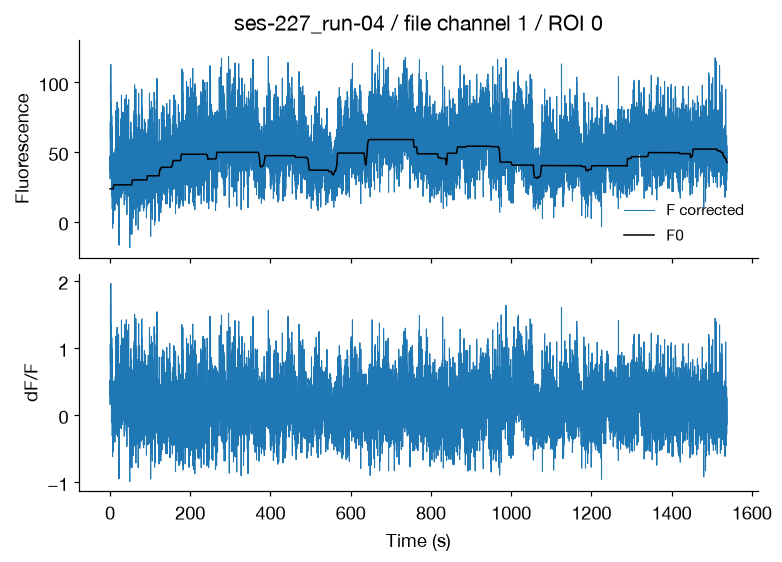

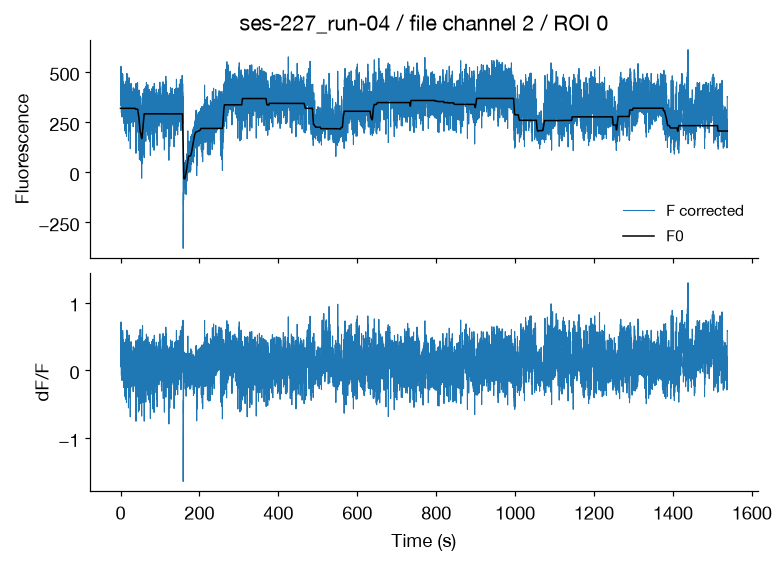

227 / run-04: [{'recording': 'ses-227_run-04', 'channel': 1, 'roi': 0, 'frames': 11566, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 45.51670455932617, 'abs_dff_p99': 1.1551419496536255, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-227_run-04', 'channel': 2, 'roi': 0, 'frames': 11566, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 293.0946960449219, 'abs_dff_p99': 0.6920106410980225, 'status': 'ok', 'defaulted_settings': []}]


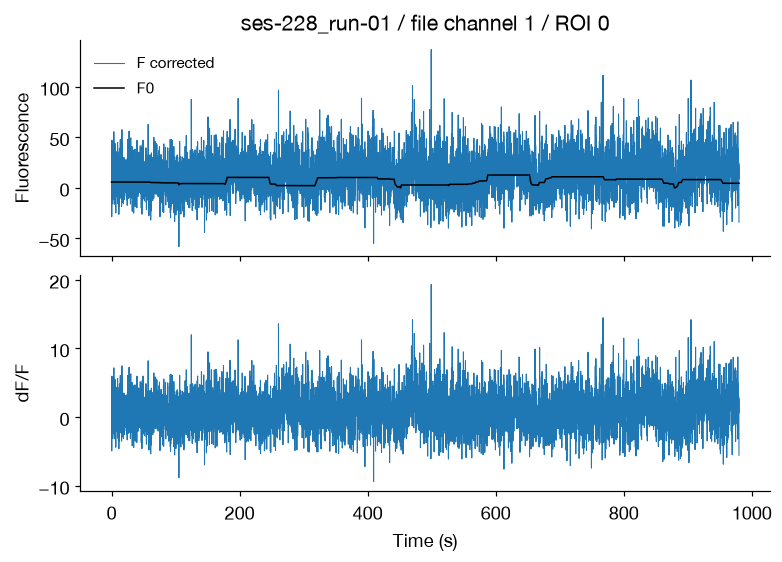

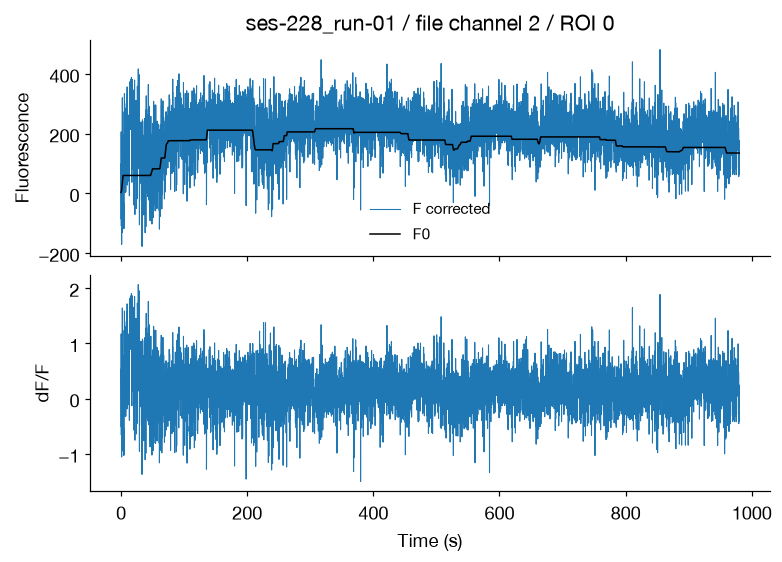

228 / run-01: [{'recording': 'ses-228_run-01', 'channel': 1, 'roi': 0, 'frames': 7371, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 6.952923774719238, 'abs_dff_p99': 8.19267749786377, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-228_run-01', 'channel': 2, 'roi': 0, 'frames': 7371, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 173.18240356445312, 'abs_dff_p99': 1.2588564157485962, 'status': 'ok', 'defaulted_settings': []}]


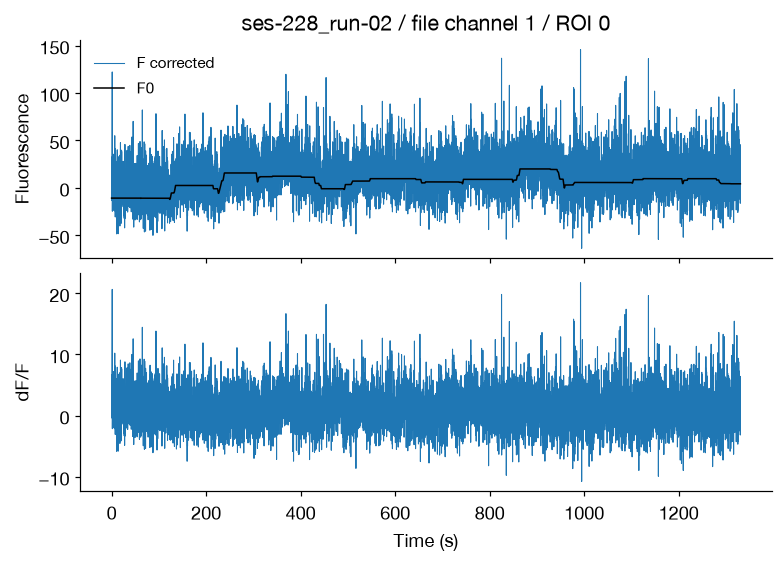

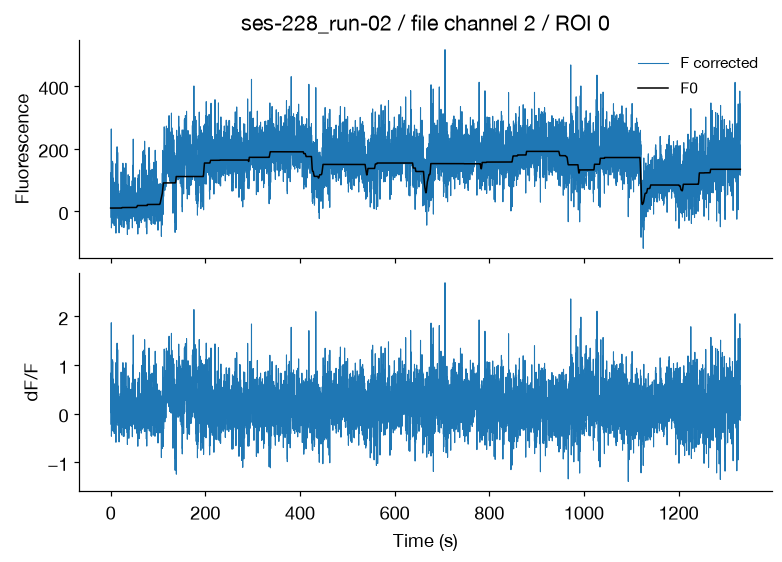

228 / run-02: [{'recording': 'ses-228_run-02', 'channel': 1, 'roi': 0, 'frames': 10007, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 6.450009346008301, 'abs_dff_p99': 9.576041221618652, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-228_run-02', 'channel': 2, 'roi': 0, 'frames': 10007, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 135.09368896484375, 'abs_dff_p99': 1.2545053958892822, 'status': 'ok', 'defaulted_settings': []}]


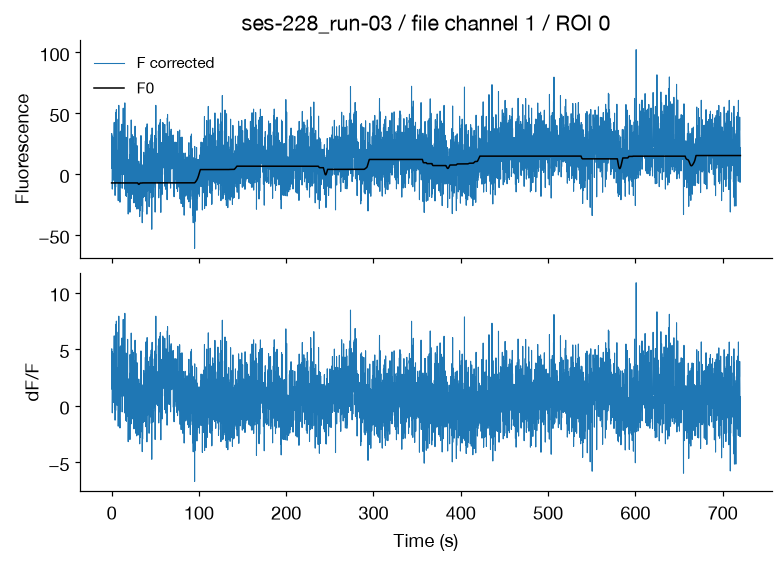

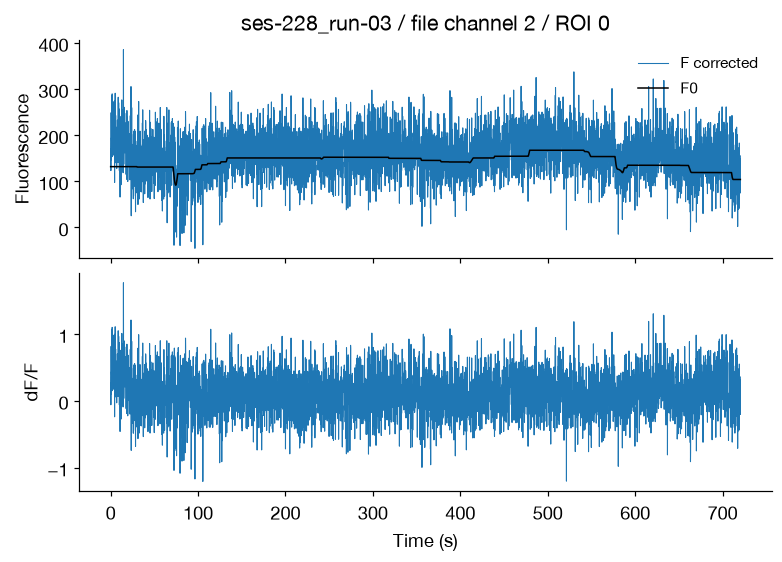

228 / run-03: [{'recording': 'ses-228_run-03', 'channel': 1, 'roi': 0, 'frames': 5418, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 8.05148696899414, 'abs_dff_p99': 6.007302761077881, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-228_run-03', 'channel': 2, 'roi': 0, 'frames': 5418, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 143.42095947265625, 'abs_dff_p99': 0.908952534198761, 'status': 'ok', 'defaulted_settings': []}]


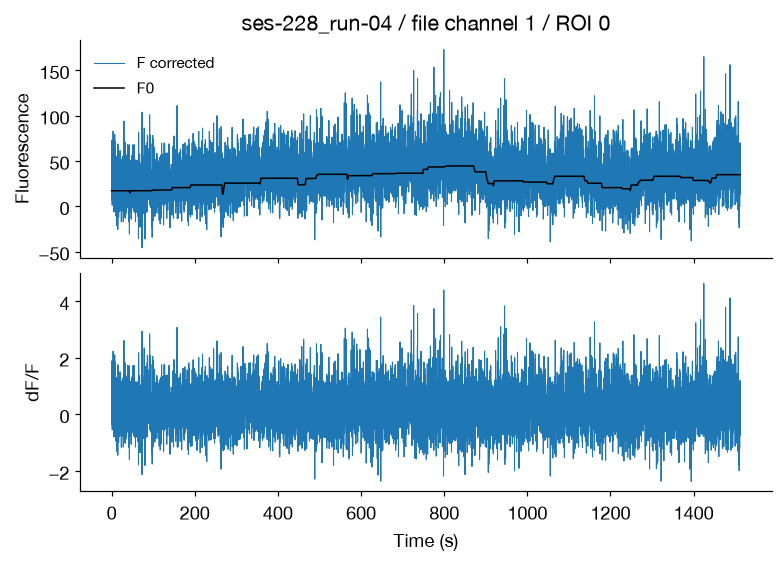

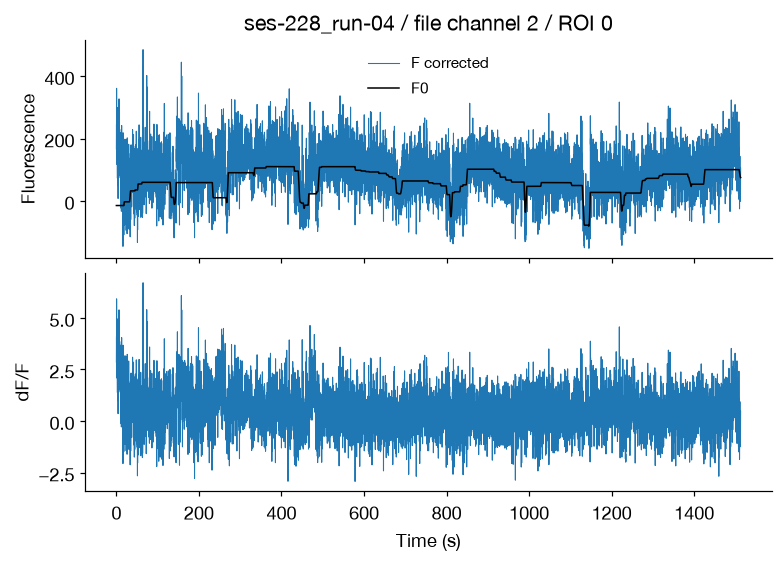

228 / run-04: [{'recording': 'ses-228_run-04', 'channel': 1, 'roi': 0, 'frames': 11375, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 29.481101989746094, 'abs_dff_p99': 2.164844274520874, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-228_run-04', 'channel': 2, 'roi': 0, 'frames': 11375, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 63.385215759277344, 'abs_dff_p99': 3.2830445766448975, 'status': 'ok', 'defaulted_settings': []}]


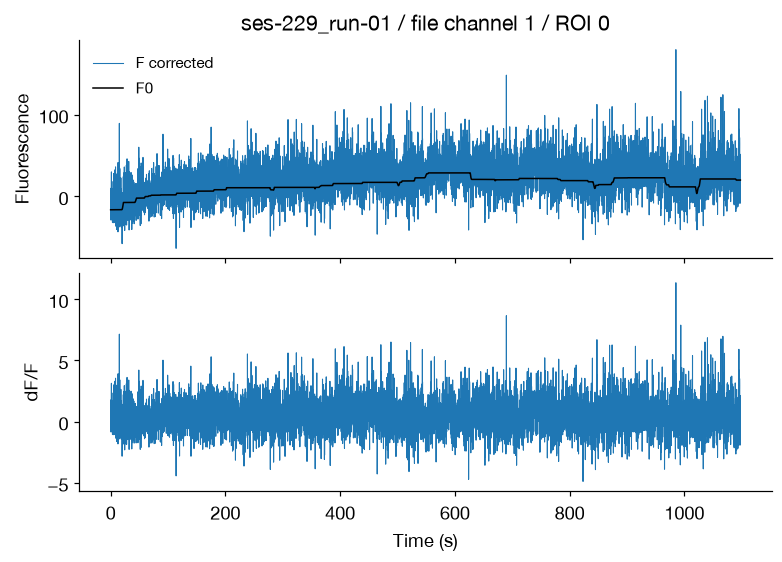

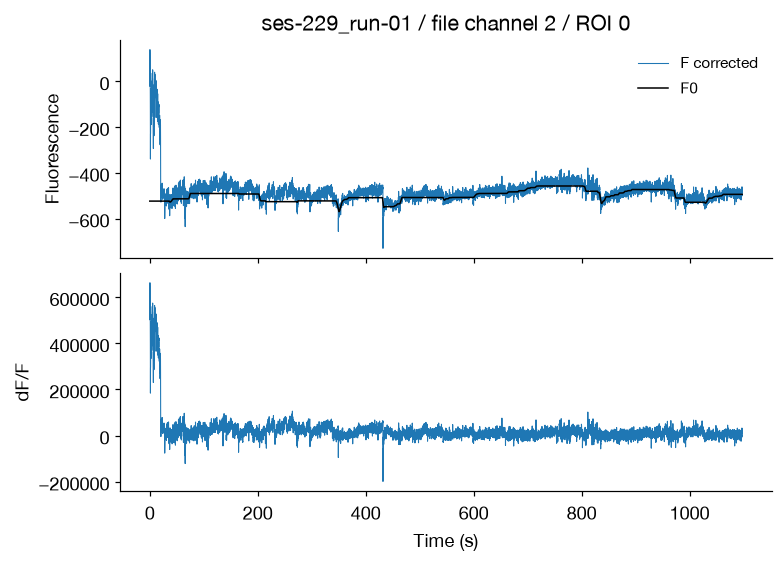

229 / run-01: [{'recording': 'ses-229_run-01', 'channel': 1, 'roi': 0, 'frames': 8255, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 14.800064086914062, 'abs_dff_p99': 4.197993755340576, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-229_run-01', 'channel': 2, 'roi': 0, 'frames': 8255, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': -500.5475769042969, 'abs_dff_p99': 422096.09375, 'status': 'CHECK F0', 'defaulted_settings': []}]


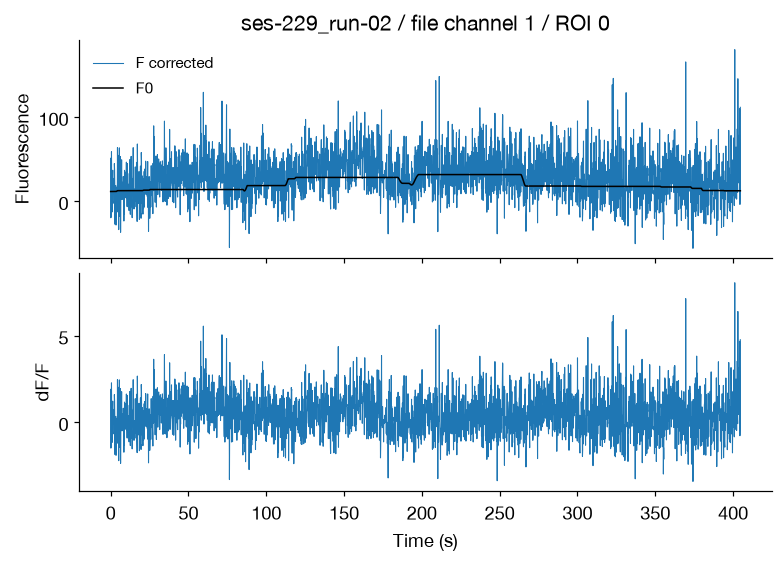

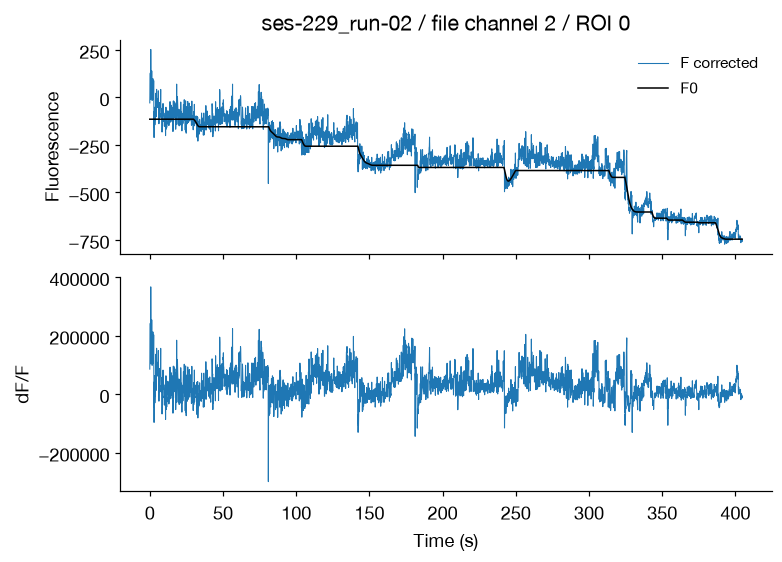

229 / run-02: [{'recording': 'ses-229_run-02', 'channel': 1, 'roi': 0, 'frames': 3044, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 20.81012535095215, 'abs_dff_p99': 3.496121406555176, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-229_run-02', 'channel': 2, 'roi': 0, 'frames': 3044, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': -362.1194152832031, 'abs_dff_p99': 174535.140625, 'status': 'CHECK F0', 'defaulted_settings': []}]


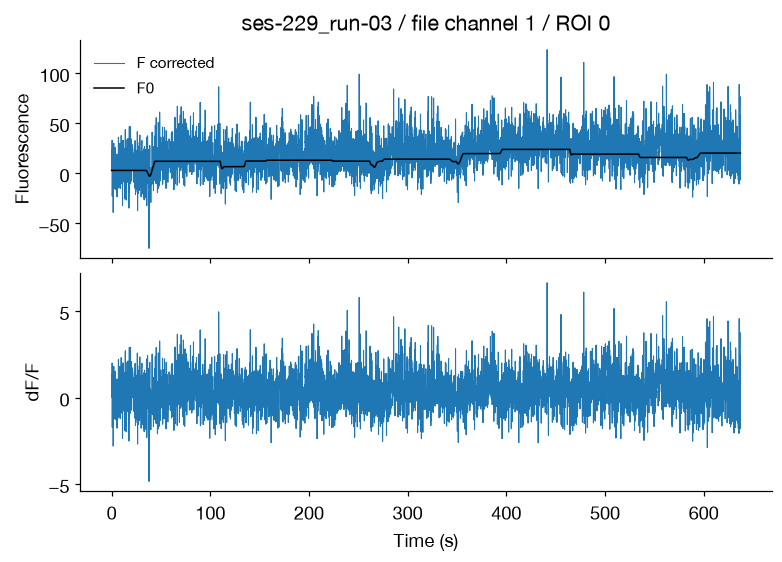

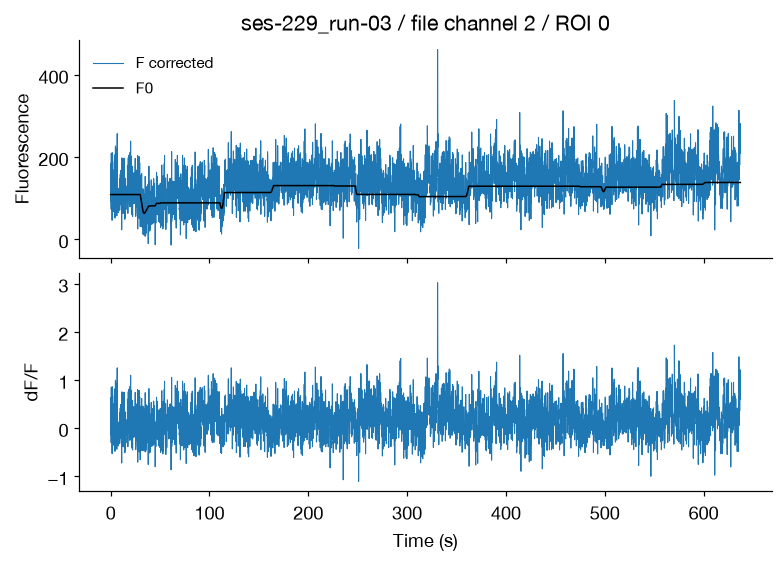

229 / run-03: [{'recording': 'ses-229_run-03', 'channel': 1, 'roi': 0, 'frames': 4793, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 14.986899375915527, 'abs_dff_p99': 3.4412107467651367, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-229_run-03', 'channel': 2, 'roi': 0, 'frames': 4793, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 118.30650329589844, 'abs_dff_p99': 1.1138566732406616, 'status': 'ok', 'defaulted_settings': []}]


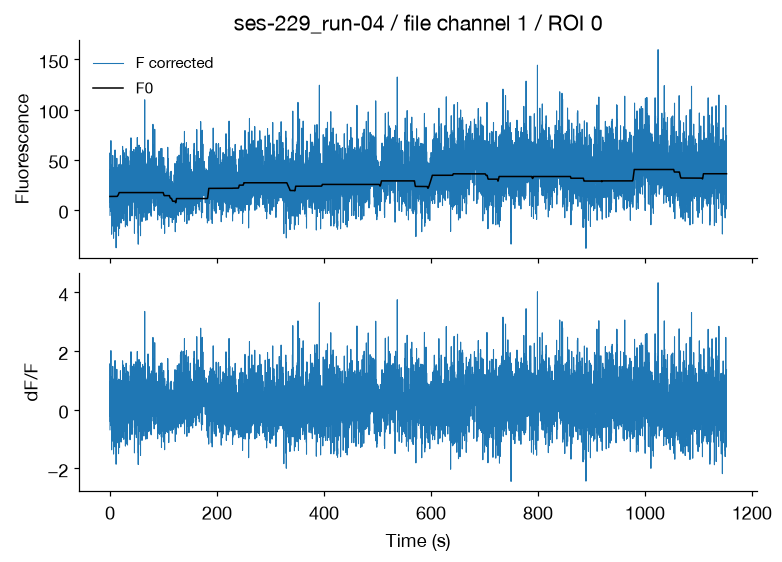

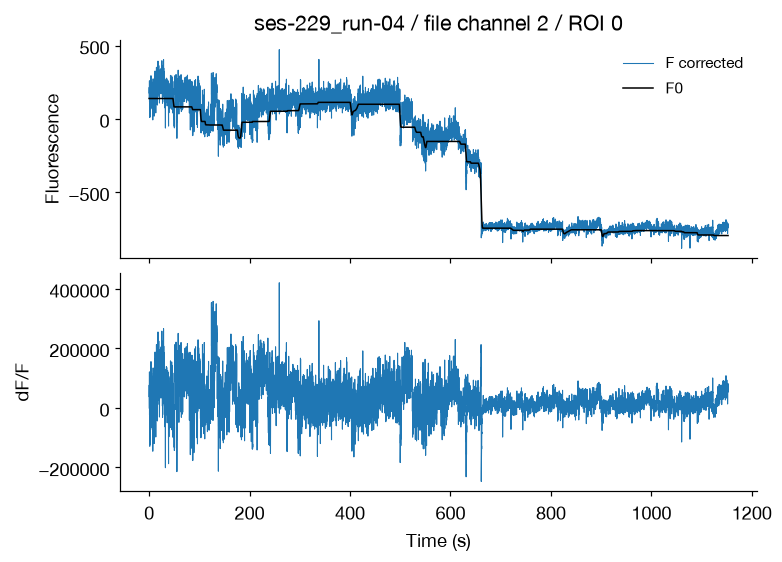

229 / run-04: [{'recording': 'ses-229_run-04', 'channel': 1, 'roi': 0, 'frames': 8669, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 27.60150146484375, 'abs_dff_p99': 2.1985058784484863, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-229_run-04', 'channel': 2, 'roi': 0, 'frames': 8669, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': -323.4744873046875, 'abs_dff_p99': 207377.4375, 'status': 'CHECK F0', 'defaulted_settings': []}]


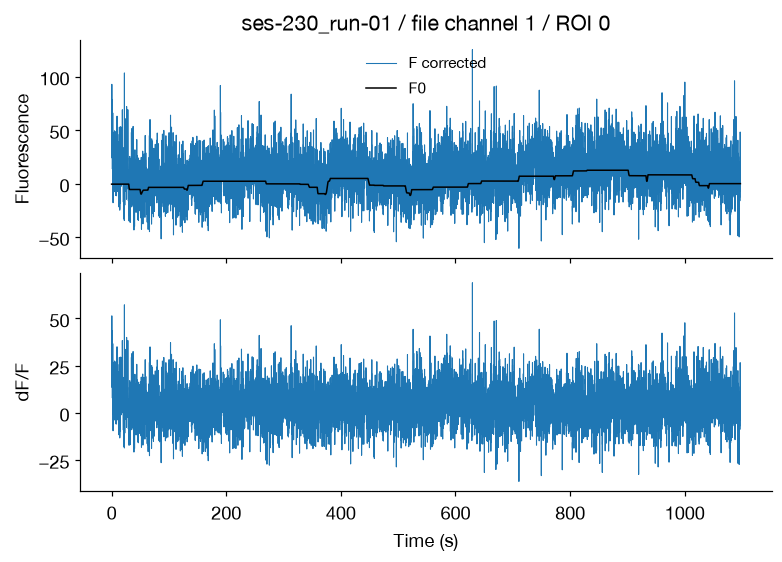

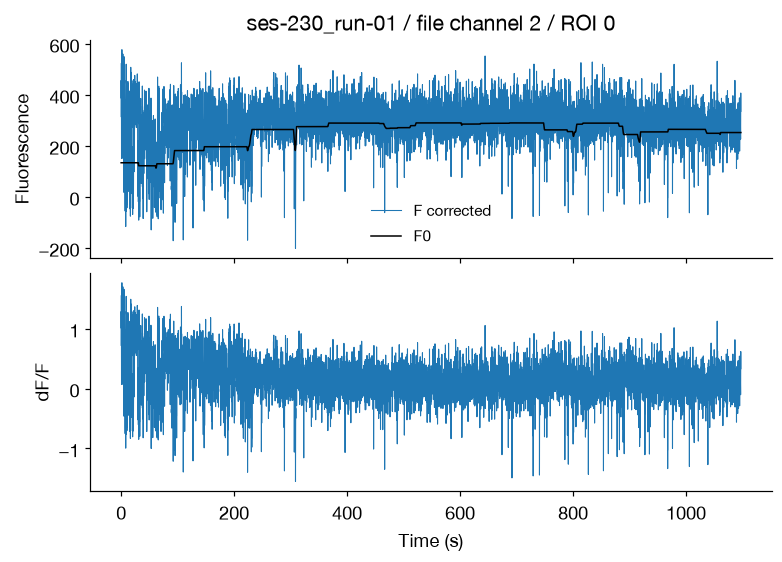

230 / run-01: [{'recording': 'ses-230_run-01', 'channel': 1, 'roi': 0, 'frames': 8251, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 1.8158854246139526, 'abs_dff_p99': 31.141220092773438, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-230_run-01', 'channel': 2, 'roi': 0, 'frames': 8251, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 251.11289978027344, 'abs_dff_p99': 1.0943291187286377, 'status': 'ok', 'defaulted_settings': []}]


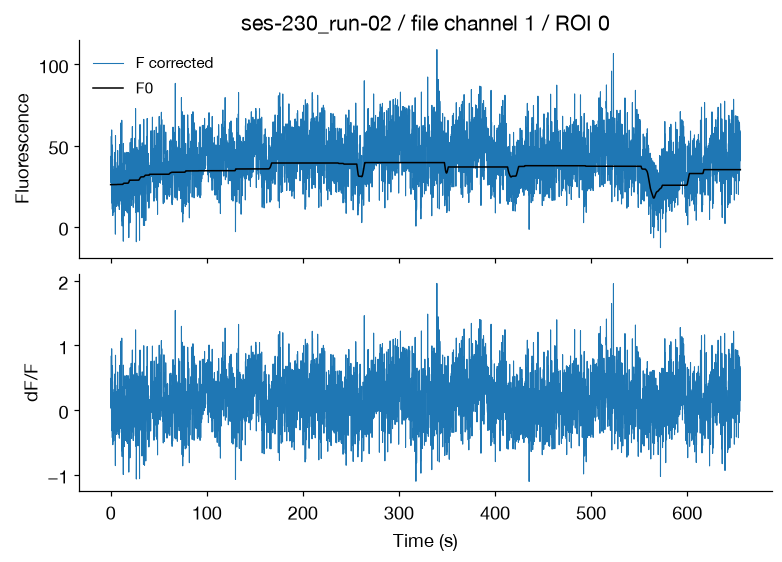

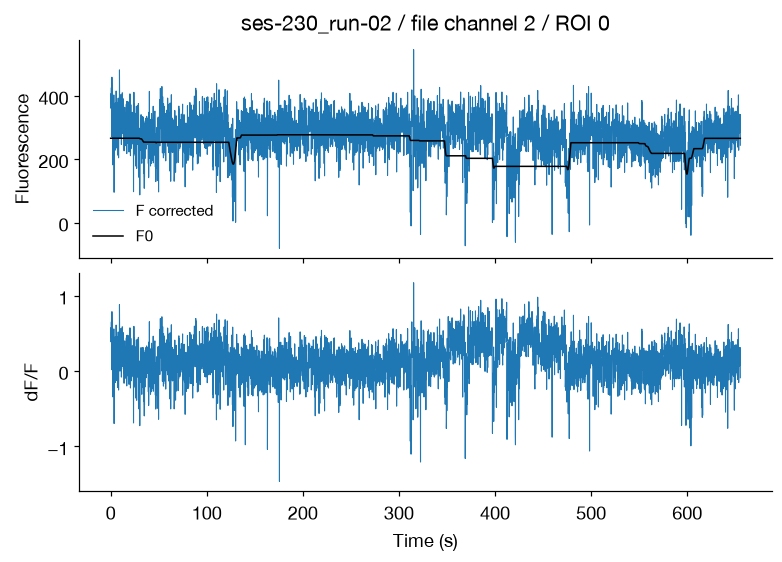

230 / run-02: [{'recording': 'ses-230_run-02', 'channel': 1, 'roi': 0, 'frames': 4929, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 35.50090789794922, 'abs_dff_p99': 1.1145190000534058, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-230_run-02', 'channel': 2, 'roi': 0, 'frames': 4929, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 244.62396240234375, 'abs_dff_p99': 0.7595773339271545, 'status': 'ok', 'defaulted_settings': []}]


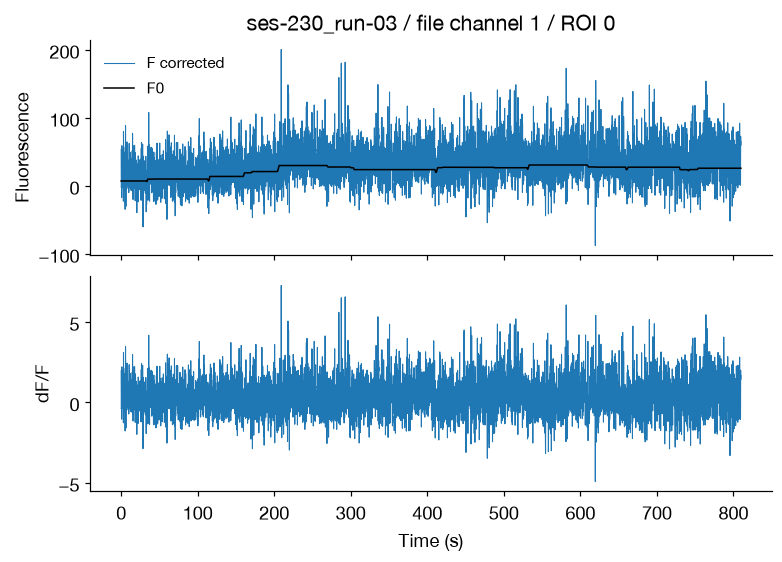

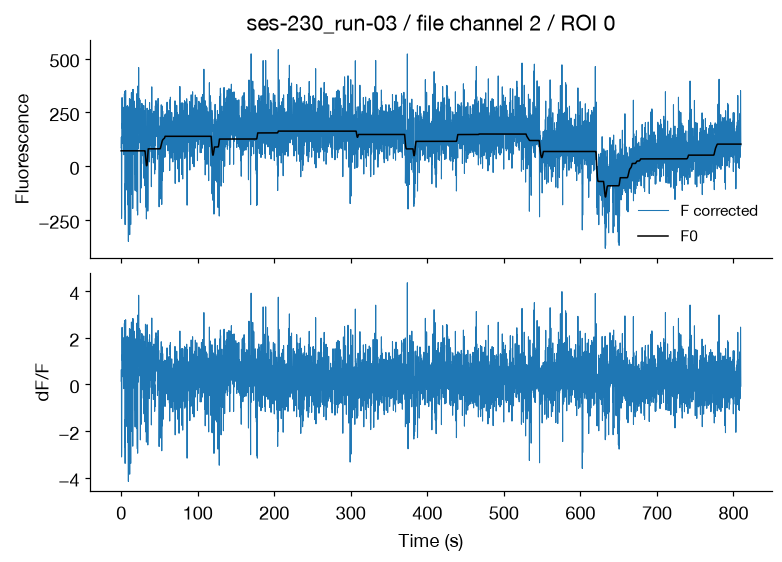

230 / run-03: [{'recording': 'ses-230_run-03', 'channel': 1, 'roi': 0, 'frames': 6090, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 23.474245071411133, 'abs_dff_p99': 3.616647243499756, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-230_run-03', 'channel': 2, 'roi': 0, 'frames': 6090, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 101.255615234375, 'abs_dff_p99': 2.7357118129730225, 'status': 'ok', 'defaulted_settings': []}]


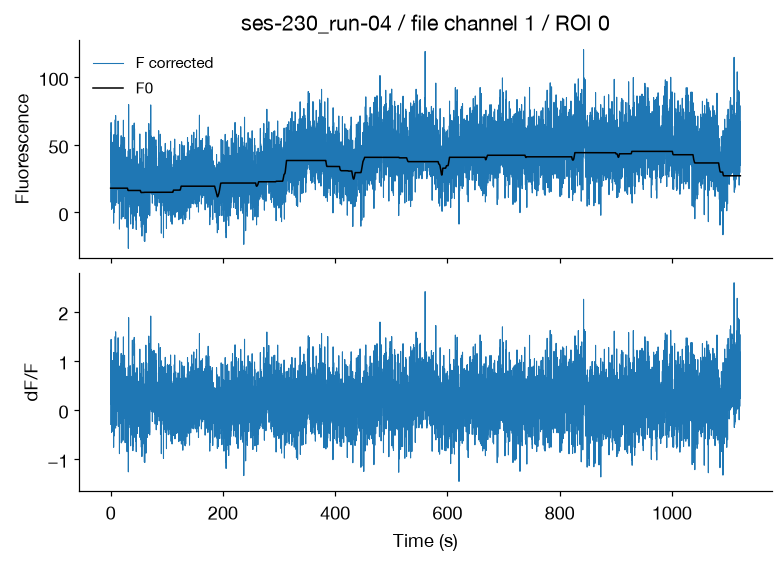

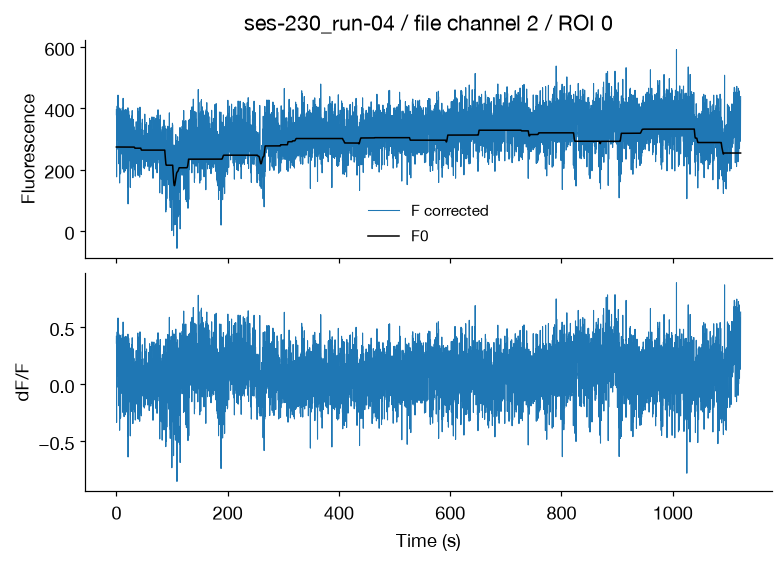

230 / run-04: [{'recording': 'ses-230_run-04', 'channel': 1, 'roi': 0, 'frames': 8439, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 33.82545471191406, 'abs_dff_p99': 1.3545807600021362, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-230_run-04', 'channel': 2, 'roi': 0, 'frames': 8439, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 290.98211669921875, 'abs_dff_p99': 0.5720048546791077, 'status': 'ok', 'defaulted_settings': []}]


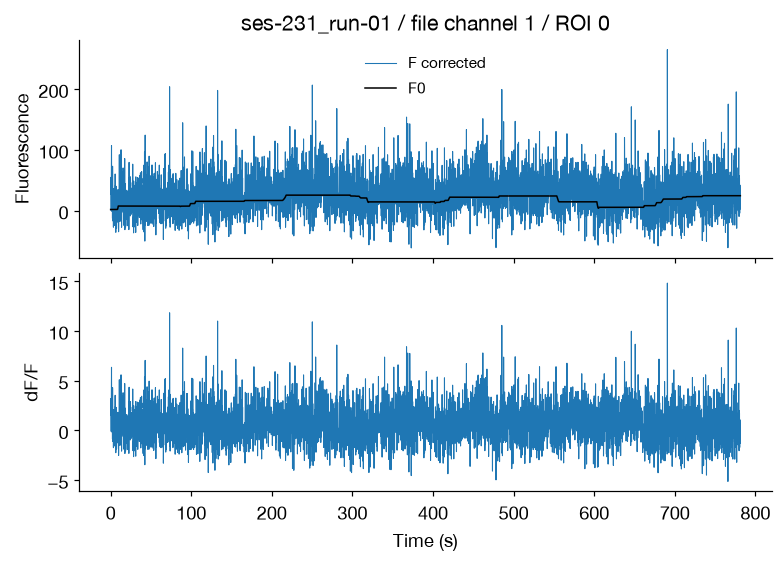

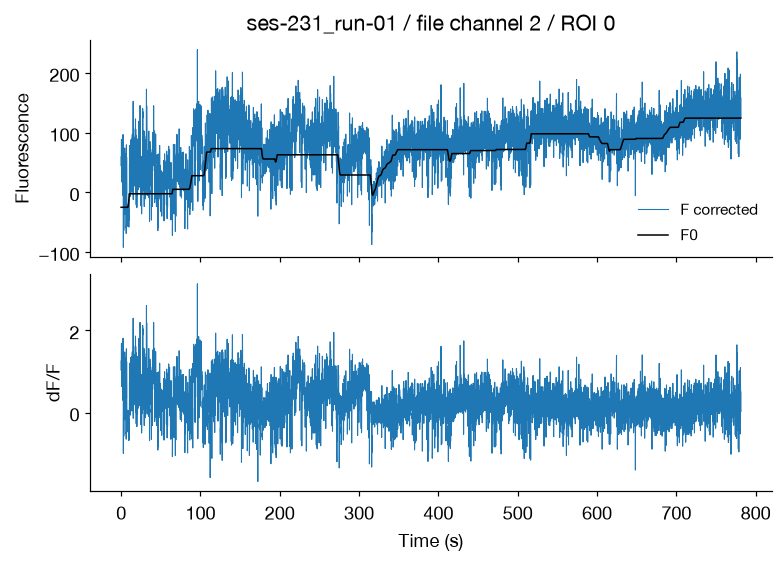

231 / run-01: [{'recording': 'ses-231_run-01', 'channel': 1, 'roi': 0, 'frames': 5877, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 16.62499237060547, 'abs_dff_p99': 5.346052169799805, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-231_run-01', 'channel': 2, 'roi': 0, 'frames': 5877, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 67.3368148803711, 'abs_dff_p99': 1.5422776937484741, 'status': 'ok', 'defaulted_settings': []}]


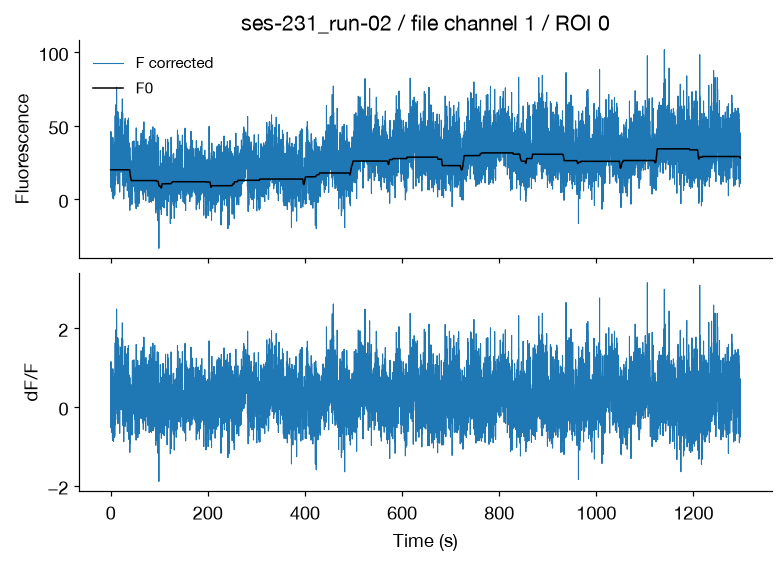

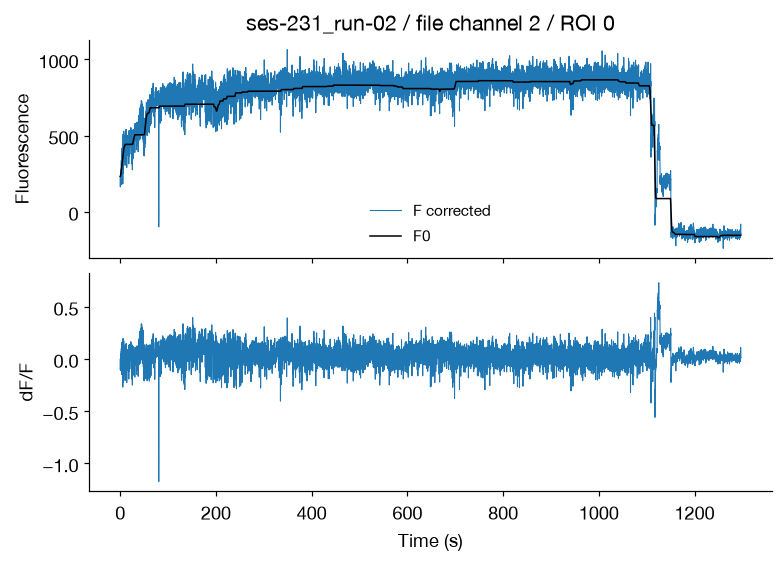

231 / run-02: [{'recording': 'ses-231_run-02', 'channel': 1, 'roi': 0, 'frames': 9752, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 22.65167808532715, 'abs_dff_p99': 1.7386208772659302, 'status': 'ok', 'defaulted_settings': []}, {'recording': 'ses-231_run-02', 'channel': 2, 'roi': 0, 'frames': 9752, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 666.053466796875, 'abs_dff_p99': 0.2840516269207001, 'status': 'ok', 'defaulted_settings': []}]


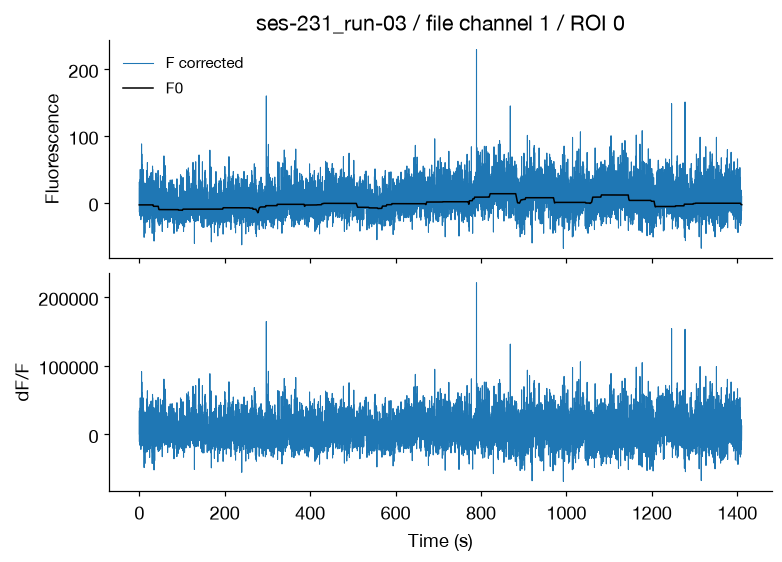

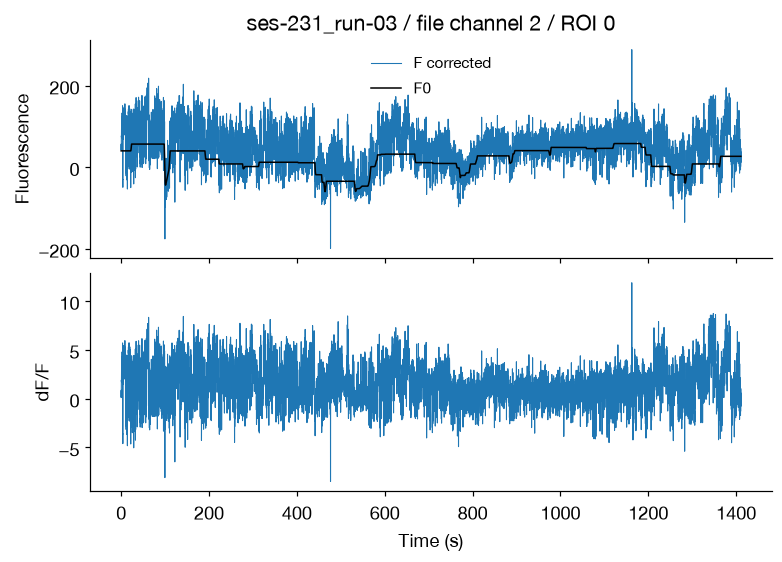

231 / run-03: [{'recording': 'ses-231_run-03', 'channel': 1, 'roi': 0, 'frames': 10609, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': -0.8015211224555969, 'abs_dff_p99': 64786.71875, 'status': 'CHECK F0', 'defaulted_settings': []}, {'recording': 'ses-231_run-03', 'channel': 2, 'roi': 0, 'frames': 10609, 'fs': 7.52, 'neucoeff': 0.7, 'baseline': 'maximin', 'mean_F0': 19.388078689575195, 'abs_dff_p99': 6.642302513122559, 'status': 'ok', 'defaulted_settings': []}]


In [32]:
def compare_one_run(session, plane):
    run_ops = np.load(plane / 'ops.npy', allow_pickle=True).item()
    missing_settings = [key for key in deconv_defaults if key not in run_ops]
    for key, value in deconv_defaults.items():
        run_ops.setdefault(key, value)
    label = f'ses-{session}_{plane.parents[1].name}'
    rows = []
    for channel in BATCH_CHANNELS:
        suffix = '' if channel == 1 else '_chan2'
        paths = [plane / f'{prefix}{suffix}.npy' for prefix in ('F', 'Fneu')]
        if channel == 2 and not any(p.exists() for p in paths):
            rows.append(dict(recording=label, channel=channel, status='channel unavailable'))
            continue
        raw, neu = [np.load(p, mmap_mode='r') for p in paths]
        if raw.ndim != 2 or raw.shape != neu.shape or 0 in raw.shape:
            raise ValueError(f'Invalid fluorescence shapes: {raw.shape}, {neu.shape}')
        ids = [r for r in BATCH_ROI_IDS if 0 <= r < raw.shape[0]]
        if not ids:
            raise ValueError(f'No selected ROIs exist in {label}')
        # The baseline operates per ROI; loading selected rows saves memory.
        corrected = raw[ids].astype(np.float32) - run_ops['neucoeff'] * neu[ids].astype(np.float32)
        values, baseline, denominator = suite2p_dff_with_f0(corrected, run_ops)
        start = 0 if FRAME_START is None else int(FRAME_START)
        stop = raw.shape[1] if FRAME_STOP is None else min(int(FRAME_STOP), raw.shape[1])
        if not 0 <= start < stop:
            raise ValueError('Invalid display frame range')
        sl = slice(start, stop)
        t = np.arange(start, stop) / run_ops['fs'] if USE_SECONDS else np.arange(start, stop)
        fig, axes = plt.subplots(2, len(ids), figsize=(7*len(ids), 5), squeeze=False, sharex=True, constrained_layout=True)
        for col, roi in enumerate(ids):
            axes[0,col].plot(t, corrected[col,sl], lw=.7, label='F corrected')
            axes[0,col].plot(t, baseline[col,sl], color='black', lw=1, label='F0')
            axes[0,col].set(title=f'{label} / file channel {channel} / ROI {roi}', ylabel='Fluorescence')
            axes[0,col].legend()
            axes[1,col].plot(t, values[col,sl], lw=.7)
            axes[1,col].set(xlabel='Time (s)' if USE_SECONDS else 'Frame', ylabel='dF/F')
            mean_f0 = float(np.mean(baseline[col]))
            rows.append(dict(recording=label, channel=channel, roi=roi, frames=raw.shape[1],
                             fs=float(run_ops['fs']), neucoeff=float(run_ops['neucoeff']),
                             baseline=str(run_ops['baseline']), mean_F0=mean_f0,
                             abs_dff_p99=float(np.nanpercentile(np.abs(values[col]),99)),
                             status='CHECK F0' if mean_f0 <= .001 else 'ok',
                             defaulted_settings=missing_settings))
        if SAVE_BATCH_FIGURES:
            folder = OUTPUT_ROOT / 'batch_overview'
            folder.mkdir(parents=True, exist_ok=True)
            fig.savefig(folder / f'{label}_channel-{channel}.png')
        plt.show()
        plt.close(fig)
    return rows

batch_summary = []
if RUN_BATCH_COMPARISON:
    for session, plane in run_planes:
        try:
            rows = compare_one_run(session, plane)
            batch_summary.extend(rows)
            print(f'{session} / {plane.parents[1].name}:', rows)
        except (OSError, ValueError, KeyError) as exc:
            row = dict(recording=str(plane), status='ERROR', error=str(exc))
            batch_summary.append(row)
            print(row)
    if SAVE_BATCH_FIGURES:
        folder = OUTPUT_ROOT / 'batch_overview'
        folder.mkdir(parents=True, exist_ok=True)
        (folder / 'summary.json').write_text(json.dumps(batch_summary, indent=2))
else:
    print('Batch overview disabled; set RUN_BATCH_COMPARISON=True to run.')